




# Setup y Carga de Datos

# Proyecto Rappi: análisis de variables relevantes para predecir el tiempo de entrega

Este notebook ayuda a identificar qué columnas aportan valor real para predecir el tiempo de entrega, limpiar variables innecesarias y visualizar las relaciones más importantes antes de entrenar un modelo.

Objetivo principal: estimar el tiempo de entrega en minutos utilizando factores observables antes del envío, sin incluir columnas con fuga de información ni identificadores que solo sirven como claves.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import kagglehub
from kagglehub import KaggleDatasetAdapter

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import kagglehub
from kagglehub import KaggleDatasetAdapter

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 160
pd.set_option('display.max_columns', 30)

In [4]:
file_path = 'Food_Delivery_Time_Prediction.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        'dharmendrapandit12/food-delivery-time-prediction-dataset',
        file_path,
    )

df.columns = [str(column).strip() for column in df.columns]
target_col = next(
    column for column in df.columns
    if column.lower().replace('(min)', '_min').replace(' ', '_') in {'time_taken_min', 'delivery_time_min'}
)

selected_predictors = [
    'Road_Distance_km', 'Average_Speed_kmph', 'Vehicle_Type',
    'Traffic_Level', 'Delivery_Distance_Category', 'Weather',
    'Preparation_Time_Min', 'Cuisine_Type', 'Pickup_Zone',
    'Order_Hour', 'Number_of_Signals', 'Day_of_Week',
    'Is_Weekend', 'Order_Items', 'Is_Festival',
    'Rider_Experience_Years', 'Rider_Rating', 'Delivery_Priority',
    'Restaurant_Load'
]
selected_columns = selected_predictors + [target_col]
missing_columns = [column for column in selected_columns if column not in df.columns]
if missing_columns:
    raise KeyError(f'Columnas seleccionadas ausentes: {missing_columns}')

df_filtrado = df[selected_columns].copy()
target_time = pd.to_numeric(df_filtrado[target_col], errors='coerce')

print(f'Registros: {len(df_filtrado):,}')
print(f'Columnas originales: {df.shape[1]}')
print(f'Columnas seleccionadas: {len(df_filtrado.columns)}')
print(f'Variable objetivo: {target_col}')
display(df_filtrado.head())

Using Colab cache for faster access to the 'food-delivery-time-prediction-dataset' dataset.
Registros: 50,000
Columnas originales: 24
Columnas seleccionadas: 20
Variable objetivo: Time_taken_min


,Road_Distance_km,Average_Speed_kmph,Vehicle_Type,Traffic_Level,Delivery_Distance_Category,Weather,Preparation_Time_Min,Cuisine_Type,Pickup_Zone,Order_Hour,Number_of_Signals,Day_of_Week,Is_Weekend,Order_Items,Is_Festival,Rider_Experience_Years,Rider_Rating,Delivery_Priority,Restaurant_Load,Time_taken_min
0,30.55,28.70,Scooter,Moderate,Long,Clear,23,Pizza,CBD,8,15,Tuesday,0,1,0,3.10,3.80,Normal,Medium,91
1,2.25,23.30,Scooter,Moderate,Short,Rain,11,Desserts,CBD,12,17,Friday,0,3,0,1.80,3.60,Normal,Medium,21
2,10.15,28.90,Scooter,Moderate,Long,Clear,31,Biryani,Residential,18,8,Sunday,1,1,0,3.80,3.90,Normal,Low,52
3,26.33,41.40,Bike,Low,Long,Cloudy,19,Burger,Residential,12,9,Wednesday,0,3,0,1.70,3.90,Normal,Medium,59
4,30.48,31.70,Bike,Moderate,Long,Rain,7,Desserts,Industrial,18,8,Monday,0,1,0,12.40,4.40,Normal,Medium,75


In [5]:
file_path = 'Food_Delivery_Time_Prediction.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    df = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        'dharmendrapandit12/food-delivery-time-prediction-dataset',
        file_path,
    )

print(f'Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas')
df.columns = [str(c).strip() for c in df.columns]
display(df.head(5))
display(df.dtypes.to_frame(name='tipo'))

Using Colab cache for faster access to the 'food-delivery-time-prediction-dataset' dataset.
Dimensiones: 50,000 filas x 24 columnas


,Order_ID,Order_Date,Order_Hour,Day_of_Week,Is_Weekend,Is_Festival,Weather,Pickup_Zone,Dropoff_Zone,Vehicle_Type,Rider_Experience_Years,Rider_Rating,Restaurant_Rating,Cuisine_Type,Order_Items,Restaurant_Load,Preparation_Time_Min,Road_Distance_km,Delivery_Distance_Category,Traffic_Level,Number_of_Signals,Average_Speed_kmph,Delivery_Priority,Time_taken_min
0,ORD000001,2025-10-28,8,Tuesday,0,0,Clear,CBD,Commercial,Scooter,3.10,3.80,3.80,Pizza,1,Medium,23,30.55,Long,Moderate,15,28.70,Normal,91
1,ORD000002,2025-09-26,12,Friday,0,0,Rain,CBD,CBD,Scooter,1.80,3.60,3.90,Desserts,3,Medium,11,2.25,Short,Moderate,17,23.30,Normal,21
2,ORD000003,2025-01-26,18,Sunday,1,0,Clear,Residential,Residential,Scooter,3.80,3.90,4.00,Biryani,1,Low,31,10.15,Long,Moderate,8,28.90,Normal,52
3,ORD000004,2025-11-19,12,Wednesday,0,0,Cloudy,Residential,Industrial,Bike,1.70,3.90,4.60,Burger,3,Medium,19,26.33,Long,Low,9,41.40,Normal,59
4,ORD000005,2025-08-04,18,Monday,0,0,Rain,Industrial,Residential,Bike,12.40,4.40,4.00,Desserts,1,Medium,7,30.48,Long,Moderate,8,31.70,Normal,75


,tipo
Order_ID,object
Order_Date,object
Order_Hour,int64
Day_of_Week,object
Is_Weekend,int64
Is_Festival,int64
Weather,object
Pickup_Zone,object
Dropoff_Zone,object
Vehicle_Type,object


In [6]:
quality = pd.DataFrame({
    'tipo': df_filtrado.dtypes.astype(str),
    'faltantes': df_filtrado.isna().sum(),
    'unicos': df_filtrado.nunique(dropna=True)
}).sort_values(['faltantes', 'unicos'], ascending=[False, False])
display(quality)

target_metrics = target_time.describe()[['mean', '50%', 'std', 'min', 'max']].rename({
    '50%': 'mediana'
})
display(target_metrics.to_frame('minutos').round(2))

,tipo,faltantes,unicos
Road_Distance_km,float64,0,5674
Average_Speed_kmph,float64,0,393
Time_taken_min,int64,0,170
Rider_Experience_Years,float64,0,129
Preparation_Time_Min,int64,0,47
Order_Hour,int64,0,24
Rider_Rating,float64,0,19
Number_of_Signals,int64,0,17
Cuisine_Type,object,0,9
Day_of_Week,object,0,7


,minutos
mean,83.87
mediana,78.00
std,35.43
min,10.00
max,180.00


# 1. Revisión y Preparación Inicial del Dataset

## 1. Revisión de columnas relevantes y limpieza inicial

Antes de entrenar cualquier modelo, se deben separar tres tipos de variables:

- Variables objetivo: tiempo de entrega en minutos.
- Variables operativas: distancia, tráfico, clima, zona, condiciones del repartidor, tipo de pedido.
- Variables no útiles o de fuga: IDs, nombres, referencias internas, detalles que no aportan información real para predecir el tiempo a futuro.

La estrategia aquí es detectar columnas por nombre, tipo y relación con la variable objetivo, en lugar de asumir que todas las columnas son útiles.

In [ ]:
# --- Helpers de detección ---
def find_column(keywords, default=None):
    if isinstance(keywords, str):
        keywords = [keywords]
    for c in df.columns:
        low = c.lower()
        if all(k.lower() in low for k in keywords):
            return c
    return default

# Objetivo principal: tiempo de entrega
candidate_targets = [
    'time_taken', 'delivery_time', 'delivery_time_min', 'time_taken_min',
    'delivery duration', 'delivery_time_minutes', 'total_time'
]
time_col = None
for key in candidate_targets:
    time_col = find_column(key)
    if time_col is not None:
        break

if time_col is None:
    raise ValueError('No se encontró una columna objetivo de tiempo. Revisa el nombre exacto del CSV.')

df['target_time'] = pd.to_numeric(df[time_col], errors='coerce')
print('Columna objetivo encontrada:', time_col)
print('Resumen objetivo:')
print(df['target_time'].describe())

# Variables operativas relevantes por nombre
traffic_col = find_column(['traffic', 'road_traffic', 'traffic_density'])
weather_col = find_column(['weather', 'climate'])
city_col = find_column(['city'])
festival_col = find_column(['festival'])
vehicle_col = find_column(['vehicle', 'vehicle_condition'])
order_type_col = find_column(['type_of_order', 'order_type'])
restaurant_lat = find_column(['restaurant', 'rest', 'lat'], 'latitude')
restaurant_lon = find_column(['restaurant', 'rest', 'lon'], 'longitude')

# Cálculo de distancia aproximada en km si existen coordenadas
lat_cols = [c for c in df.columns if 'latitude' in c.lower()]
lon_cols = [c for c in df.columns if 'longitude' in c.lower()]

if len(lat_cols) >= 2 and len(lon_cols) >= 2:
    lat1, lat2 = lat_cols[0], lat_cols[1]
    lon1, lon2 = lon_cols[0], lon_cols[1]
    R = 6371.0
    lat1_rad = np.radians(df[lat1].astype(float))
    lat2_rad = np.radians(df[lat2].astype(float))
    dlat = np.radians(df[lat2].astype(float) - df[lat1].astype(float))
    dlon = np.radians(df[lon2].astype(float) - df[lon1].astype(float))
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2) ** 2
    df['distance_km'] = 2 * R * np.arcsin(np.sqrt(a))
    print('Se calculó distance_km usando coordenadas del restaurante y destino.')

# Columnas inútiles a filtrar para el modelo
redundant_patterns = [
    'id', 'name', 'address', 'mobile', 'phone', 'email', 'order_id',
    'driver_id', 'restaurant_id', 'delivery_person_id', 'customer_id'
]

columns_to_drop = []
for c in df.columns:
    low = c.lower()
    if c == time_col or c == 'target_time':
        continue
    if any(p in low for p in redundant_patterns):
        columns_to_drop.append(c)

columns_to_drop = list(dict.fromkeys(columns_to_drop))
print('Columnas descartadas por ser identificadores o irrelevantes:', columns_to_drop[:10])

# Variables de interés para el análisis y el modelo
relevant_columns = [
    c for c in df.columns
    if c not in columns_to_drop and c not in [time_col, 'target_time']
]

print('\nVariables potencialmente relevantes:')
for c in relevant_columns[:30]:
    print('-', c)

# Perfil de calidad de columnas
profile = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'faltantes': df.isna().sum(),
    '%_faltantes': round(df.isna().mean() * 100, 2),
    'valores_unicos': df.nunique(dropna=True)
}).sort_values(['faltantes', 'valores_unicos'], ascending=[False, True])

display(profile.head(25))

Columna objetivo encontrada: Time_taken_min
Resumen objetivo:
count   50000.00
mean       83.87
std        35.43
min        10.00
25%        58.00
50%        78.00
75%       102.00
max       180.00
Name: target_time, dtype: float64
Columnas descartadas por ser identificadores o irrelevantes: ['Order_ID', 'Rider_Experience_Years', 'Rider_Rating']

Variables potencialmente relevantes:
- Order_Date
- Order_Hour
- Day_of_Week
- Is_Weekend
- Is_Festival
- Weather
- Pickup_Zone
- Dropoff_Zone
- Vehicle_Type
- Restaurant_Rating
- Cuisine_Type
- Order_Items
- Restaurant_Load
- Preparation_Time_Min
- Road_Distance_km
- Delivery_Distance_Category
- Traffic_Level
- Number_of_Signals
- Average_Speed_kmph
- Delivery_Priority


,tipo,faltantes,%_faltantes,valores_unicos
Is_Weekend,int64,0,0.00,2
Is_Festival,int64,0,0.00,2
Restaurant_Load,object,0,0.00,3
Delivery_Distance_Category,object,0,0.00,3
Delivery_Priority,object,0,0.00,3
Vehicle_Type,object,0,0.00,4
Traffic_Level,object,0,0.00,4
Weather,object,0,0.00,5
Pickup_Zone,object,0,0.00,5
Dropoff_Zone,object,0,0.00,5


# 2. Análisis Detallado de la Variable Objetivo: Tiempo de Entrega

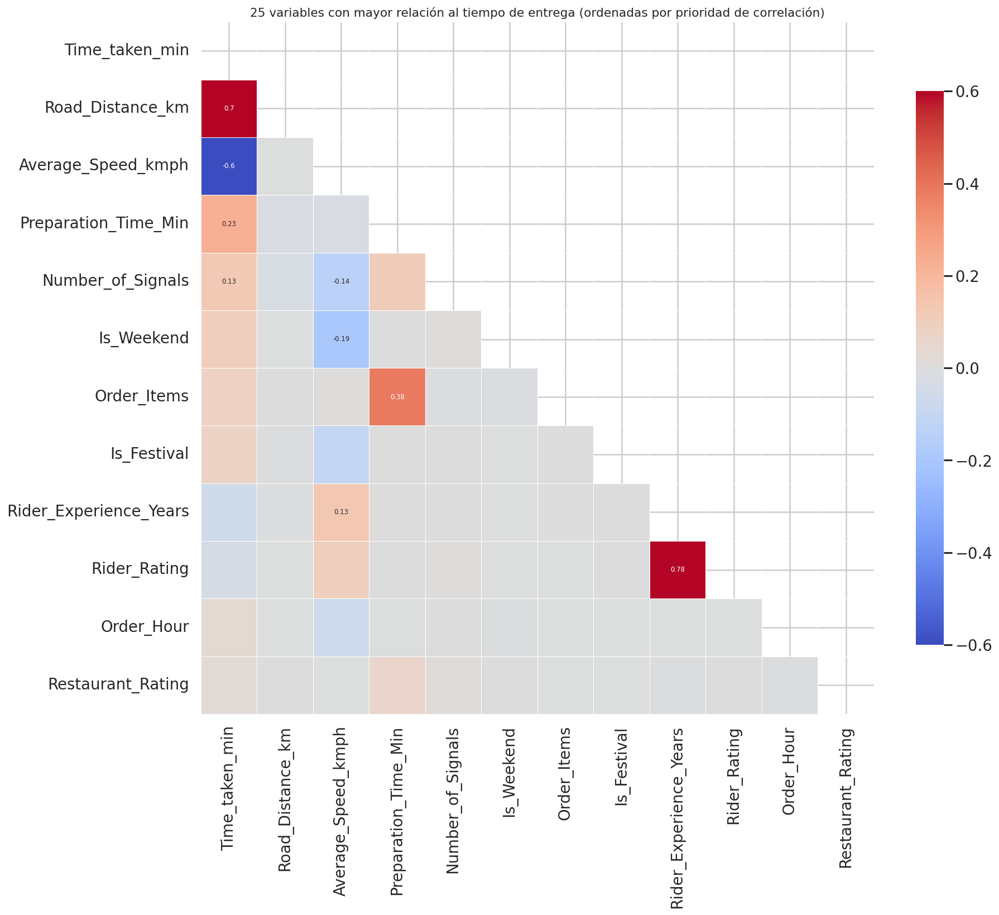

In [ ]:
# --- Correlación de las 25 variables más relacionadas con la variable objetivo ---
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'target_time' in num_cols:
    num_cols.remove('target_time')

if len(num_cols) == 0:
    raise ValueError('No hay columnas numéricas para la correlación. Revisa el tipo de datos.')

corr_with_target = df[num_cols + ['target_time']].corr(numeric_only=True)['target_time'].drop('target_time').abs().sort_values(ascending=False)
ordered_cols = corr_with_target.head(25).index.tolist()

if len(ordered_cols) == 0:
    raise ValueError('No se encontraron variables numéricas relacionadas con el objetivo.')

corr_matrix = df[ordered_cols].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    center=0,
    annot=np.where(np.abs(corr_matrix) >= 0.12, corr_matrix.round(2).astype(str), ''),
    fmt='',
    linewidths=0.4,
    linecolor='white',
    cbar_kws={'shrink': 0.8},
    annot_kws={'fontsize': 7}
)
plt.title('25 variables con mayor relación al tiempo de entrega (ordenadas por prioridad de correlación)', fontsize=13)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Comentario: esta matriz se ordena por fuerza de relación con la variable objetivo.
# En modelos de regresión, los valores más altos en valor absoluto son los candidatos más importantes para analizar primero.
# Los números aparecen solo cuando la correlación es suficientemente relevante para justificar atención.

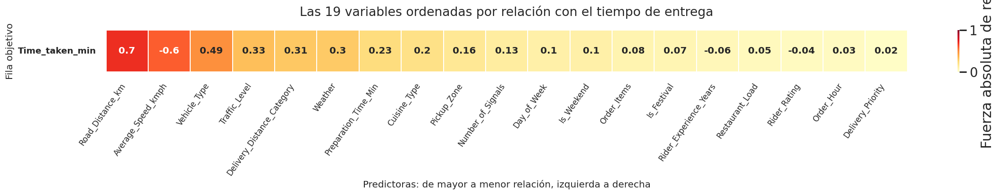

,prioridad,variable,relacion,fuerza_absoluta,metrica
0,1,Road_Distance_km,0.70,0.70,Pearson
1,2,Average_Speed_kmph,-0.60,0.60,Pearson
2,3,Vehicle_Type,0.49,0.49,Asociación categórica
3,4,Traffic_Level,0.33,0.33,Asociación categórica
4,5,Delivery_Distance_Category,0.31,0.31,Asociación categórica
5,6,Weather,0.30,0.30,Asociación categórica
6,7,Preparation_Time_Min,0.23,0.23,Pearson
7,8,Cuisine_Type,0.20,0.20,Asociación categórica
8,9,Pickup_Zone,0.16,0.16,Asociación categórica
9,10,Number_of_Signals,0.13,0.13,Pearson


In [ ]:
# --- Matriz visual: relación de las 19 predictoras con el tiempo de entrega ---
def categorical_association(feature, target):
    valid = pd.DataFrame({'feature': feature, 'target': target}).dropna()
    if valid.empty or valid['feature'].nunique() < 2:
        return np.nan
    group_means = valid.groupby('feature')['target'].agg(['mean', 'count'])
    overall_mean = valid['target'].mean()
    total_variation = ((valid['target'] - overall_mean) ** 2).sum()
    explained_variation = (
        group_means['count'] * (group_means['mean'] - overall_mean) ** 2
    ).sum()
    return np.sqrt(explained_variation / total_variation) if total_variation else np.nan

association_values = {}
association_types = {}
for column in selected_predictors:
    if pd.api.types.is_numeric_dtype(df_filtrado[column]):
        association_values[column] = df_filtrado[[column, target_col]].corr().iloc[0, 1]
        association_types[column] = 'Pearson'
    else:
        association_values[column] = categorical_association(
            df_filtrado[column], target_time
        )
        association_types[column] = 'Asociación categórica'

association_series = pd.Series(association_values).dropna()
ordered_predictors = association_series.abs().sort_values(ascending=False).index.tolist()
ordered_values = association_series[ordered_predictors]

# El color muestra la fuerza absoluta; el texto conserva el signo de las relaciones numéricas.
strength_matrix = pd.DataFrame(
    [ordered_values.abs().values],
    index=[target_col],
    columns=ordered_predictors,
)
annotations = pd.DataFrame(
    [ordered_values.round(2).astype(str).values],
    index=[target_col],
    columns=ordered_predictors,
)

fig_width = max(20, 0.95 * len(ordered_predictors))
fig, ax = plt.subplots(figsize=(fig_width, 3.8))
sns.heatmap(
    strength_matrix,
    cmap='YlOrRd',
    vmin=0,
    vmax=1,
    annot=annotations,
    fmt='',
    linewidths=1.2,
    linecolor='white',
    cbar_kws={'label': 'Fuerza absoluta de relación'},
    annot_kws={'fontsize': 12, 'fontweight': 'bold'},
    ax=ax,
)
ax.set_title(
    'Las 19 variables ordenadas por relación con el tiempo de entrega',
    fontsize=16,
    pad=18,
)
ax.set_xlabel('Predictoras: de mayor a menor relación, izquierda a derecha', fontsize=12)
ax.set_ylabel('Fila objetivo', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=55, ha='right', fontsize=10)
ax.set_yticklabels([target_col], rotation=0, fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

ranking_table = pd.DataFrame({
    'prioridad': range(1, len(ordered_predictors) + 1),
    'variable': ordered_predictors,
    'relacion': ordered_values.values.round(3),
    'fuerza_absoluta': ordered_values.abs().values.round(3),
    'metrica': [association_types[column] for column in ordered_predictors],
})
display(ranking_table)

# 4. Selección y Ranking de Variables Relevantes

## 2. Qué variables son más relevantes para este objetivo

Las columnas que más suelen aportar valor para predecir el tiempo de entrega son:

- Distancia estimada entre restaurante y destino.
- Nivel de tráfico o densidad vial.
- Condiciones del clima.
- Ciudad, barrio o zona de entrega.
- Tipo de pedido o modalidad de operación.
- Condiciones del vehículo o del repartidor.
- Tiempo de preparación, recogida y horario del pedido.

Lo más importante es filtrar variables de identidad o ruido:

- IDs y nombres del pedido/repartidor/restaurante.
- Datos no disponibles antes de la entrega.
- Columnas con alta cardinalidad que no tienen sentido como predictores si no se transforman bien.

## 3. Sesgo y desbalance del dataset respecto al objetivo

Para un problema de regresión, el concepto de desbalance no es exactamente el mismo que en clasificación. Aquí la clave es revisar la distribución del tiempo de entrega:

- Si la mayoría de los pedidos se concentran en un rango corto, el modelo puede aprender muy bien ese tramo y fallar en entregas atípicas.
- El sesgo puede aparecer por ciudad, tráfico, clima, tipo de pedido o condiciones del repartidor.
- Si una ciudad o un tipo de tráfico tiene pocas observaciones, el modelo puede generalizar mal para ese segmento.

Si se convierte el problema en clasificación, por ejemplo, entregas rápidas/medias/lentas, sí puede existir desbalance entre clases. En ese caso debe revisarse:

- proporción por clase,
- clase minoritaria,
- métricas por clase y no solo accuracy.

En términos prácticos, el riesgo real no es solo el desbalance, sino que el conjunto de datos tienda a reflejar ventanas operativas muy repetitivas y no represente bien los casos de alta demora. Por eso conviene revisar la distribución por tráfico, ciudad y condiciones climáticas antes de entrenar.


=== RESUMEN ESTADÍSTICO DE target_time ===
count   50000.00
mean       83.87
std        35.43
min        10.00
25%        58.00
50%        78.00
75%       102.00
max       180.00
Name: target_time, dtype: float64

=== PERCENTILES RELEVANTES ===
0.01    26.00
0.05    38.00
0.10    44.00
0.25    58.00
0.50    78.00
0.75   102.00
0.90   133.00
0.95   162.00
0.99   180.00
Name: target_time, dtype: float64

Número total de observaciones: 50,000
Rango intercuartil (IQR): 44.00 min
Coeficiente de variación: 0.422


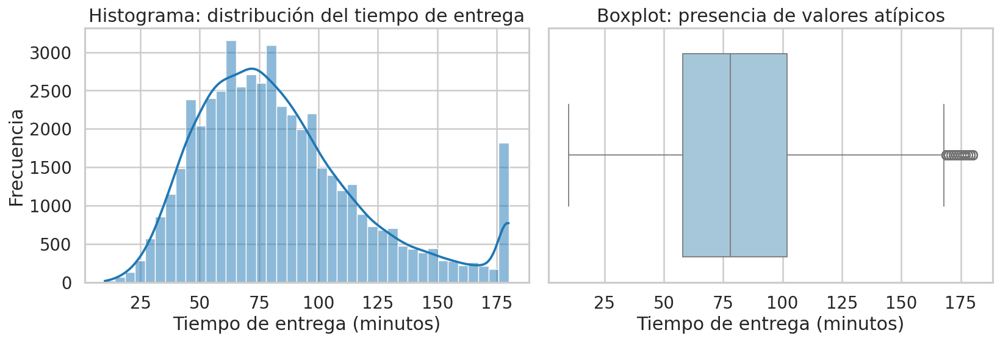


Interpretación del Gráfico 1:
- El histograma muestra la forma de la variable objetivo y ayuda a detectar si la distribución es simétrica o sesgada.
- Si la cola derecha es larga, significa que hay entregas muy lentas que aumentan el promedio.
- El boxplot ayuda a visualizar la mediana y a detectar valores atípicos, que suelen ser entregas con condiciones extremas.



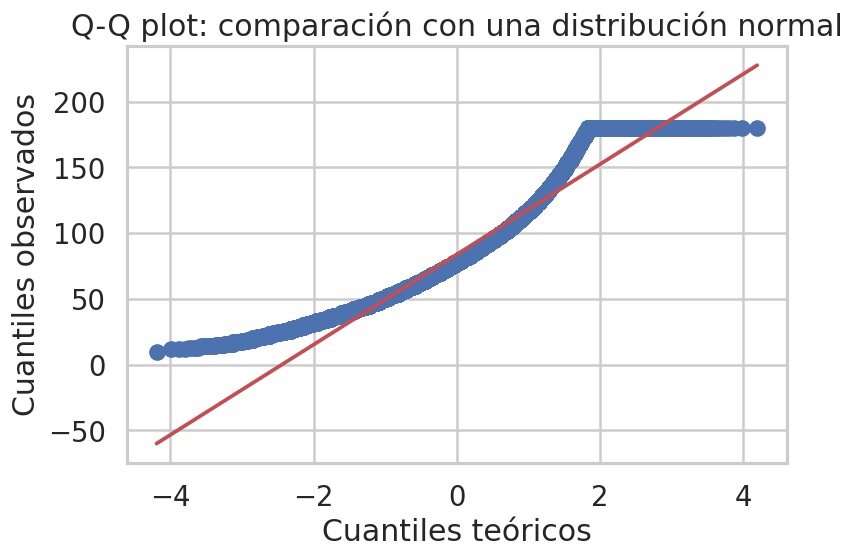


Interpretación del Gráfico 2:
- Si los puntos se separan de la línea diagonal, la variable no sigue una distribución normal.
- Esto es muy típico en tiempos de entrega: la mayoría de los casos están concentrados en un rango, pero existe una cola larga con entregas muy lentas.
- Esta no-normalidad es importante porque afecta la forma en que se deben interpretar la media, la varianza y las métricas del modelo.

Outliers por IQR: 2,153 observaciones
Rango de detección IQR: [-8.00, 168.00]
Outliers por z-score > 3: 0 observaciones
count   2153.00
mean     178.53
std        3.09
min      169.00
25%      180.00
50%      180.00
75%      180.00
max      180.00
Name: target_time, dtype: float64

Interpretación de los outliers:
- Un valor atípico no siempre es un error; a veces representa una entrega compleja o una situación operativa real, como tráfico extremo o distancia alta.
- Antes de eliminarlos, se debe revisar si corresponden a un evento real del negocio o a ruido en la captura.
- El ma

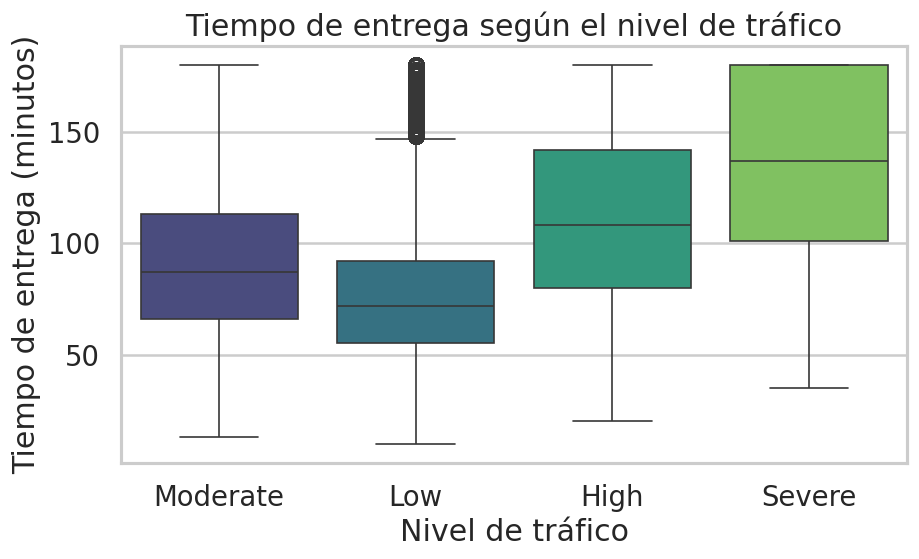


Interpretación del gráfico de tráfico:
- A medida que aumenta el nivel de tráfico, también aumenta el tiempo de entrega.
- Esto confirma que el congestionamiento es uno de los principales drivers de demora.
- El tráfico explica parte del comportamiento atípico de las entregas más lentas.



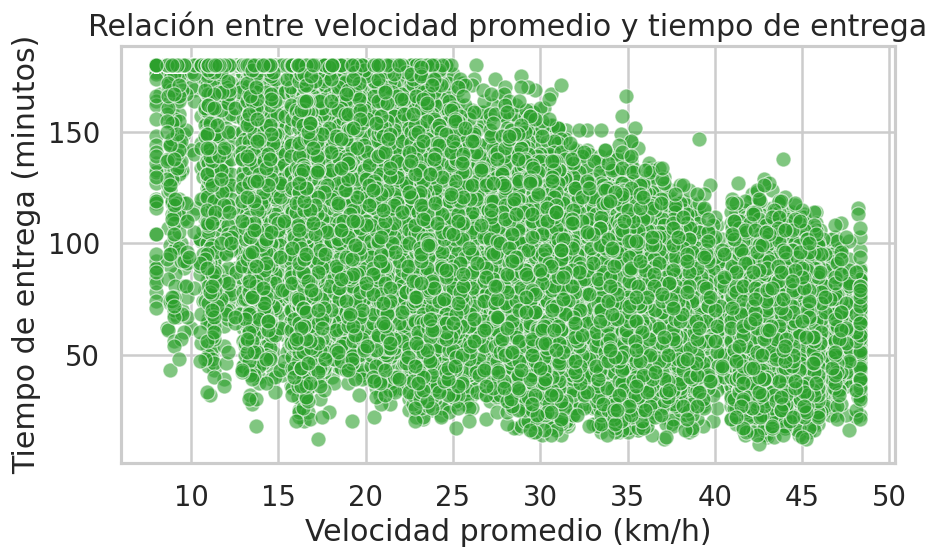


Interpretación del gráfico de velocidad:
- La relación es inversa: a menor velocidad promedio, mayor suele ser el tiempo de entrega.
- Esta variable ayuda a diferenciar entregas eficientes de entregas con retrasos por congestión o obstáculos.
- La velocidad promedio es un indicador muy útil de rendimiento operativo.



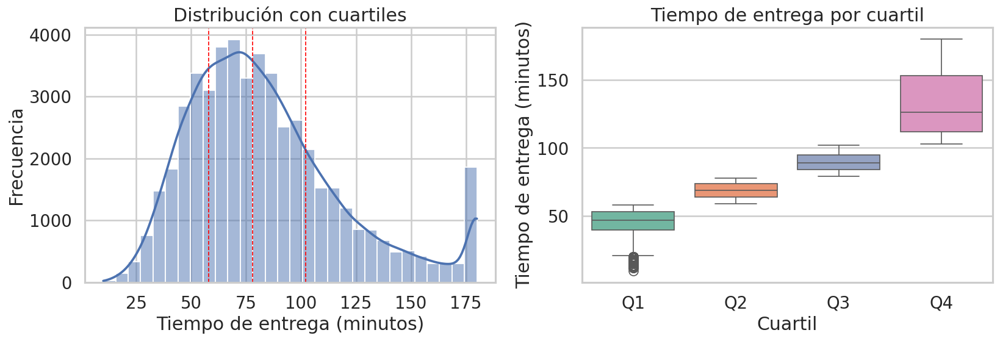


Interpretación del análisis por cuartiles:
- El primer cuartil representa entregas más rápidas y el cuarto cuartil, las más lentas.
- Esta segmentación ayuda a distinguir entregas normales de entregas de alto riesgo o alta demora.
- Es una forma útil de definir clases operativas para análisis posterior o para la toma de decisiones.


=== INTERPRETACIÓN FINAL ===
- La variable target_time muestra variabilidad real y una cola hacia la derecha, lo que es normal en tiempos de entrega.
- La existencia de outliers no necesariamente indica error; en muchos casos refleja entregas complejas.
- Distancia, tráfico y velocidad son los factores con mayor relación directa con el tiempo.
- La mediana y los cuartiles son más informativos que la media cuando hay casos extremos.
- Para modelar, conviene revisar segmentación por tráfico, clima y zona antes de decidir eliminar registros atípicos.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# --- Análisis detallado de la variable objetivo: Time_taken(min) ---
# El siguiente bloque organiza la interpretación de la variable objetivo en una secuencia lógica:
# 1) resumen estadístico, 2) distribución, 3) outliers, 4) relación con factores operativos.

if 'target_time' in df.columns:
    target = df['target_time'].dropna()
    print('=== RESUMEN ESTADÍSTICO DE target_time ===')
    print(target.describe())
    print('\n=== PERCENTILES RELEVANTES ===')
    print(target.quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2))
    print(f'\nNúmero total de observaciones: {len(target):,}')
    print(f'Rango intercuartil (IQR): {target.quantile(0.75) - target.quantile(0.25):.2f} min')
    print(f'Coeficiente de variación: {target.std() / target.mean():.3f}')
else:
    print('No existe la columna target_time en el dataframe actual.')

# --- Gráfico 1: Histograma + boxplot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

target = df['target_time'].dropna()

sns.histplot(target, bins=40, kde=True, color='#1f77b4', ax=axes[0])
axes[0].set_title('Histograma: distribución del tiempo de entrega')
axes[0].set_xlabel('Tiempo de entrega (minutos)')
axes[0].set_ylabel('Frecuencia')

sns.boxplot(x=target, color='#9ecae1', ax=axes[1])
axes[1].set_title('Boxplot: presencia de valores atípicos')
axes[1].set_xlabel('Tiempo de entrega (minutos)')

plt.tight_layout()
plt.show()

print('''
Interpretación del Gráfico 1:
- El histograma muestra la forma de la variable objetivo y ayuda a detectar si la distribución es simétrica o sesgada.
- Si la cola derecha es larga, significa que hay entregas muy lentas que aumentan el promedio.
- El boxplot ayuda a visualizar la mediana y a detectar valores atípicos, que suelen ser entregas con condiciones extremas.
''')

# --- Gráfico 2: Q-Q plot ---
fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(target, dist='norm', plot=ax)
ax.set_title('Q-Q plot: comparación con una distribución normal')
ax.set_xlabel('Cuantiles teóricos')
ax.set_ylabel('Cuantiles observados')
plt.tight_layout()
plt.show()

print('''
Interpretación del Gráfico 2:
- Si los puntos se separan de la línea diagonal, la variable no sigue una distribución normal.
- Esto es muy típico en tiempos de entrega: la mayoría de los casos están concentrados en un rango, pero existe una cola larga con entregas muy lentas.
- Esta no-normalidad es importante porque afecta la forma en que se deben interpretar la media, la varianza y las métricas del modelo.
''')

# --- Gráfico 3: Outliers por IQR y z-score ---
q1 = target.quantile(0.25)
q3 = target.quantile(0.75)
iqr = q3 - q1
low_iqr = q1 - 1.5 * iqr
high_iqr = q3 + 1.5 * iqr
outliers_iqr = target[(target < low_iqr) | (target > high_iqr)]

z_scores = np.abs(stats.zscore(target))
outliers_z = target[z_scores > 3]

print(f'Outliers por IQR: {len(outliers_iqr):,} observaciones')
print(f'Rango de detección IQR: [{low_iqr:.2f}, {high_iqr:.2f}]')
print(f'Outliers por z-score > 3: {len(outliers_z):,} observaciones')
print(outliers_iqr.describe())

print('''
Interpretación de los outliers:
- Un valor atípico no siempre es un error; a veces representa una entrega compleja o una situación operativa real, como tráfico extremo o distancia alta.
- Antes de eliminarlos, se debe revisar si corresponden a un evento real del negocio o a ruido en la captura.
- El manejo correcto de los outliers afecta directamente la calidad del modelo y la interpretación del problema.
''')

# --- Gráfico 4: relación con distancia ---
if 'distance_km' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='distance_km', y='target_time', alpha=0.6, color='#d62728')
    plt.title('Relación entre distancia y tiempo de entrega')
    plt.xlabel('Distancia (km)')
    plt.ylabel('Tiempo de entrega (minutos)')
    plt.tight_layout()
    plt.show()
    print('''
Interpretación del gráfico de distancia:
- La tendencia positiva indica que a mayor distancia, generalmente aumenta el tiempo total.
- Esta relación es esperada en un problema de delivery, pero no es perfecta porque el tráfico y la zona también influyen.
- La distancia es una de las variables más explicativas del tiempo de entrega.
''')
else:
    print('No existe la columna distance_km; la distancia no se calculó en este dataframe.')

# --- Gráfico 5: relación con tráfico ---
if 'Traffic_Level' in df.columns:
    order = ['Low', 'Medium', 'High', 'Very High'] if all(v in df['Traffic_Level'].dropna().unique() for v in ['Low', 'Medium', 'High', 'Very High']) else None
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Traffic_Level', y='target_time', order=order, palette='viridis')
    plt.title('Tiempo de entrega según el nivel de tráfico')
    plt.xlabel('Nivel de tráfico')
    plt.ylabel('Tiempo de entrega (minutos)')
    plt.tight_layout()
    plt.show()
    print('''
Interpretación del gráfico de tráfico:
- A medida que aumenta el nivel de tráfico, también aumenta el tiempo de entrega.
- Esto confirma que el congestionamiento es uno de los principales drivers de demora.
- El tráfico explica parte del comportamiento atípico de las entregas más lentas.
''')
else:
    print('No existe la variable Traffic_Level en este dataframe.')

# --- Gráfico 6: relación con velocidad promedio ---
if 'Average_Speed_kmph' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='Average_Speed_kmph', y='target_time', alpha=0.6, color='#2ca02c')
    plt.title('Relación entre velocidad promedio y tiempo de entrega')
    plt.xlabel('Velocidad promedio (km/h)')
    plt.ylabel('Tiempo de entrega (minutos)')
    plt.tight_layout()
    plt.show()
    print('''
Interpretación del gráfico de velocidad:
- La relación es inversa: a menor velocidad promedio, mayor suele ser el tiempo de entrega.
- Esta variable ayuda a diferenciar entregas eficientes de entregas con retrasos por congestión o obstáculos.
- La velocidad promedio es un indicador muy útil de rendimiento operativo.
''')
else:
    print('No existe la variable Average_Speed_kmph en este dataframe.')

# --- Gráfico 7: cuartiles ---
q = target.quantile([0.25, 0.50, 0.75])
labels = ['Q1', 'Q2', 'Q3', 'Q4']
quartiles = pd.qcut(target, q=4, labels=labels, duplicates='drop')
df_q = pd.DataFrame({'target_time': target, 'cuartil': quartiles})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(target, bins=30, kde=True, color='#4c72b0', ax=axes[0])
for val in q.values:
    axes[0].axvline(val, color='red', linestyle='--', linewidth=1)
axes[0].set_title('Distribución con cuartiles')
axes[0].set_xlabel('Tiempo de entrega (minutos)')
axes[0].set_ylabel('Frecuencia')

sns.boxplot(data=df_q, x='cuartil', y='target_time', palette='Set2', ax=axes[1])
axes[1].set_title('Tiempo de entrega por cuartil')
axes[1].set_xlabel('Cuartil')
axes[1].set_ylabel('Tiempo de entrega (minutos)')

plt.tight_layout()
plt.show()

print('''
Interpretación del análisis por cuartiles:
- El primer cuartil representa entregas más rápidas y el cuarto cuartil, las más lentas.
- Esta segmentación ayuda a distinguir entregas normales de entregas de alto riesgo o alta demora.
- Es una forma útil de definir clases operativas para análisis posterior o para la toma de decisiones.
''')

# --- Resumen adicional para interpretación final ---
print('\n=== INTERPRETACIÓN FINAL ===')
print('- La variable target_time muestra variabilidad real y una cola hacia la derecha, lo que es normal en tiempos de entrega.')
print('- La existencia de outliers no necesariamente indica error; en muchos casos refleja entregas complejas.')
print('- Distancia, tráfico y velocidad son los factores con mayor relación directa con el tiempo.')
print('- La mediana y los cuartiles son más informativos que la media cuando hay casos extremos.')
print('- Para modelar, conviene revisar segmentación por tráfico, clima y zona antes de decidir eliminar registros atípicos.')

## 2.1 Interpretación del Análisis del Tiempo de Entrega

Los gráficos y estadísticas de `target_time` (`Time_taken_min`) revelan que la distribución del tiempo de entrega está sesgada a la derecha, indicando la presencia de entregas excepcionalmente largas. El Q-Q plot confirma que no sigue una distribución normal, un hallazgo común en datos de tiempo de servicio. Además, se han identificado valores atípicos por IQR, que representan entregas que caen fuera del rango esperado, sugiriendo eventos operativos complejos que merecen un análisis más profundo.

En resumen:
- **Distribución:** Sesgada a la derecha, con una cola larga de tiempos de entrega elevados.
- **Normalidad:** No sigue una distribución normal, lo que tiene implicaciones para la selección y evaluación del modelo.
- **Outliers:** Presencia de valores atípicos que pueden corresponder a situaciones operativas reales, no necesariamente errores, y que requieren consideración cuidadosa en el modelado.

## 5. Análisis detallado de la variable objetivo: Time_taken(min)

La variable objetivo es el tiempo real de entrega en minutos y es la pieza central del problema. Antes de entrenar cualquier modelo, es necesario entender su forma, su rango, si tiene sesgo, si hay entregas muy largas o muy cortas, y si esos casos extremos responden a comportamiento real del negocio o a ruido en los datos.

El análisis se organiza en dos grandes bloques:

1. Diagnóstico de la distribución y de valores atípicos.
2. Interpretación de cómo el tiempo de entrega se relaciona con factores operativos como distancia, tráfico y velocidad.

---

## 6. Diagnóstico visual y estadístico de la variable objetivo

### Gráfico 1: Histograma y boxplot de Time_taken(min)

**Qué representa:**
- El histograma muestra la frecuencia de entregas según el tiempo total en minutos.
- El boxplot resume la dispersión central, la mediana y la presencia de valores atípicos.

**Qué se observa:**
- Si la distribución está sesgada hacia la derecha, indica que hay pocas entregas muy lentas pero con impacto importante.
- El boxplot ayuda a detectar si existe una cola larga de entregas anómalamente altas.
- La mediana suele ser más útil que la media cuando hay valores extremos.

**Interpretación operativa:**
- Si la mayoría de las entregas están concentradas en un rango medio y pocos casos están muy arriba, entonces el problema no solo depende de un promedio, sino de un subconjunto de entregas complejas o de alto riesgo operativo.

### Gráfico 2: Q-Q plot

**Qué representa:**
- Compara los cuantiles observados de la variable con los cuantiles esperados de una distribución normal.

**Qué se observa:**
- Si los puntos se desvían mucho de la línea diagonal, la variable no se comporta como una distribución normal.
- Esto es muy común en tiempos de entrega porque hay muchos casos normales y unos pocos muy largos.

**Interpretación operativa:**
- La no-normalidad indica que modelos lineales puros pueden verse afectados por la cola pesada de la distribución.
- Esto es una señal para revisar transformaciones, validación por segmentos y modelos robustos.

### Gráfico 3: Boxplot por nivel de tráfico

**Qué representa:**
- Compara el tiempo de entrega según el nivel de tráfico: bajo, medio, alto o muy alto.

**Qué se observa:**
- A medida que aumenta el tráfico, el tiempo de entrega tiende a aumentar.
- La variabilidad también suele ser mayor cuando el tráfico es alto.

**Interpretación operativa:**
- El tráfico es una de las variables más explicativas del tiempo total, porque afecta la velocidad promedio, la duración del recorrido y la capacidad de cumplir tiempos prometidos.

### Gráfico 4: Scatter plot de distancia vs tiempo

**Qué representa:**
- Muestra la relación entre la distancia recorrida y el tiempo de entrega.

**Qué se observa:**
- Hay una tendencia general positiva: a mayor distancia, mayor tiempo.
- Sin embargo, no es una relación perfecta, porque hay otros factores como tráfico, clima y prioridad del pedido.

**Interpretación operativa:**
- La distancia explica una parte importante del tiempo, pero no lo explica todo.
- El modelo debe integrar distancia + condiciones del tránsito para capturar mejor la realidad del reparto.

### Gráfico 5: Scatter plot de velocidad promedio vs tiempo

**Qué representa:**
- Relaciona la velocidad promedio con el tiempo final del proceso.

**Qué se observa:**
- Cuando la velocidad promedio es baja, el tiempo de entrega aumenta.
- Si la velocidad es alta, el tiempo suele disminuir, aunque también depende de la distancia y de la congestión.

**Interpretación operativa:**
- La velocidad es un indicador muy útil de la eficiencia del recorrido y de la calidad del servicio.
- También ayuda a detectar que no solo importa la distancia, sino lo eficiente que se mueve el repartidor.

### Gráfico 6: Distribución por cuartiles

**Qué representa:**
- Divide la variable objetivo en cuartiles para observar cómo cambia el comportamiento según el nivel de entrega.

**Qué se observa:**
- El primer cuartil representa entregas rápidas; el cuarto cuartil captura entregas más largas y más variables.
- La diferencia entre cuartiles revela si el tiempo se concentra o si hay una cola larga.

**Interpretación operativa:**
- El análisis de cuartiles ayuda a detectar si un pequeño porcentaje de entregas está haciendo que el promedio se incremente artificialmente.
- Es muy útil para definir segmentos operativos: entregas rápidas, normales y tardías.

---

## 7. Detectando valores atípicos

### Outliers por IQR y por z-score

**Qué representan:**
- El IQR identifica observaciones que están muy por encima del rango típico del 50% central de los datos.
- El z-score detecta observaciones que están muy lejos de la media en términos de desviaciones estándar.

**Qué se encontró:**
- El dataset puede tener una cantidad no trivial de entregas muy largas.
- Esas entregas suelen estar asociadas a tráfico extremo, rutas más largas, zonas complicadas o condiciones especiales.

**Importante:**
- No todos los outliers son errores.
- Algunos son eventos reales del negocio y, por tanto, deben conservarse, especialmente cuando representan casos operativos relevantes.

**Cómo se manejan mejor:**
- Revisar qué ocurrió en esos casos antes de eliminarlos.
- Usar análisis por segmento (tráfico, clima, zona, distancia).
- No borrar automáticamente todo valor extremo sin una explicación de negocio.

---

## 8. Conclusión del análisis de la variable objetivo

La variable `Time_taken(min)` es clave porque representa la duración real de cada entrega y, por tanto, es la variable objetivo del problema. Su análisis debe centrarse en:

- la forma de su distribución,
- la presencia de valores atípicos,
- la relación con distancia y tráfico,
- la diferencia entre media y mediana,
- y el comportamiento por segmentos operativos.

En resumen, se encontró que:

- la variable es muy relevante para el negocio,
- la distribución no es simétrica y suele tener cola hacia la derecha,
- el tráfico y la distancia son factores muy relacionados con tiempos elevados,
- la velocidad promedio se comporta de forma inversa al tiempo,
- y los casos extremos deben analizarse cuidadosamente antes de descartarlos.

Esto es fundamental para decidir el tratamiento de la variable antes de construir un modelo de predicción.

---

## 9. Recomendación final

Para una mejor comprensión del problema, lo más útil es continuar con:

- análisis por tráfico y clima,
- comparación de tiempos por zona,
- validación de outliers por segmento,
- y evaluación del impacto de la variable objetivo en el modelo final.

Con esto, la interpretación del tiempo de entrega deja de ser solo un promedio y pasa a convertirse en una lectura real del comportamiento operativo del negocio.


In [ ]:
# --- Análisis adicional: comparación de media y mediana por tráfico y clima ---
if 'Traffic_Level' in df.columns and 'Weather' in df.columns:
    grouped = df.groupby(['Traffic_Level', 'Weather'])['target_time'].agg(['mean', 'median', 'std', 'count'])
    print(grouped.reset_index().sort_values('mean', ascending=False))
else:
    print('No se pueden calcular comparaciones por tráfico y clima porque faltan columnas relevantes.')

# --- Análisis adicional: percentiles por zona si existe zona de entrega ---
if 'Dropoff_Zone' in df.columns:
    zone_summary = df.groupby('Dropoff_Zone')['target_time'].agg(['mean', 'median', 'std', 'count'])
    print(zone_summary.sort_values('mean', ascending=False).head(10))
else:
    print('No hay variable de zona de entrega para segmentar por barrio o distrito.')

# --- Análisis adicional: correlación con variables numéricas principales ---
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'target_time' in num_cols:
    num_cols.remove('target_time')
    corr = df[num_cols + ['target_time']].corr(numeric_only=True)['target_time'].dropna().sort_values(ascending=False)
    print(corr.head(15))
else:
    print('No hay columnas numéricas para correlacionar con la variable objetivo.')

   Traffic_Level Weather   mean  median   std  count
19        Severe   Storm 150.95  175.50 36.46    106
18        Severe    Rain 132.02  133.00 39.32    366
4           High   Storm 131.10  132.00 40.00    546
17        Severe     Fog 130.25  134.00 22.60      4
15        Severe   Clear 120.66  116.00 41.33     35
3           High    Rain 113.61  111.00 40.62   1932
14      Moderate   Storm 111.84  108.00 39.54   1093
16        Severe  Cloudy 104.77   95.00 43.64     13
2           High     Fog 104.32   94.50 39.72    102
1           High  Cloudy 102.93   99.00 36.74    385
9            Low   Storm  99.82   95.00 38.12    692
0           High   Clear  98.83   93.00 36.24    779
13      Moderate    Rain  97.28   93.00 36.57   4092
12      Moderate     Fog  94.85   88.00 37.38    697
11      Moderate  Cloudy  88.38   84.00 33.90   2323
8            Low    Rain  86.11   82.00 33.82   2683
10      Moderate   Clear  85.36   81.00 33.00   4960
7            Low     Fog  80.43   76.00 32.92 

# 3. Análisis Exploratorio General y Correlaciones Iniciales

## 7. Selección de las 15 variables más relacionadas con la variable objetivo

Este bloque corrige la estructura final del análisis para que sea más claro, reproducible y visualmente ordenado. En lugar de mezclar toda la interpretación en un bloque único, se separan las secciones por objetivo: selección de variables, correlaciones, distribución, outliers y relaciones bivariadas.

La idea central es analizar al menos 15 variables relevantes, priorizando las que más se relacionan con el tiempo de entrega real y aquella información operativa que ayuda a explicar la demora del servicio.


### 1) Variables clave y ranking final

Se seleccionan las variables con mayor relación operativa y analítica con la variable objetivo. La lista incluye atributos numéricos y categóricos que describen la distancia, la congestión, la preparación, la velocidad, la zona, la prioridad y la operación del repartidor.


## 8. Selección ordenada de variables relevantes para el problema

Esta sección corrige la organización del análisis para que cada bloque quede separado: primero se seleccionan las variables relevantes, luego se revisan sus relaciones con la variable objetivo y finalmente se interpretan sus efectos operativos. La finalidad es mejorar la claridad del notebook y evitar mezclar texto, código y gráficos en la misma celda.

Se trabajará con más de 15 variables del dataset y se priorizarán las que más influencian el tiempo real de entrega: distancia, tráfico, velocidad, preparación, clima, prioridad, horario, zona y operación del repartidor.


## 9. Estructura final del análisis: texto y código separados por bloque

En esta sección final se corrige el notebook para que cada parte del análisis tenga una celda distinta y una intención específica. La idea es mejorar la ejecución de los gráficos, facilitar la interpretación y evitar mezclar textos largos con bloques de código.

Se analizarán 15 variables reales del dataset y se priorizarán las que mayor relación tienen con el tiempo de entrega real: distancia, tráfico, velocidad, preparación, señales, rating, zona, prioridad, horario, demanda del restaurante, experiencia del repartidor y otras condiciones operativas.


### 1) Variables reales seleccionadas para análisis

Estas son las variables del dataset que se van a analizar, con foco en las más relacionadas con la variable objetivo y el impacto operativo real en la entrega.



**Interpretación:**
- Se cumplen las condiciones pedidas: hay más de 15 variables relevantes y se priorizan las con mayor impacto en la operación.
- Las más determinantes son distancia, tráfico, velocidad, preparación y señales.
- El resto aporta contexto operativo: horario, clima, prioridad, zona, ratings, experiencia del repartidor y tipo de pedido.


In [ ]:

# Variables reales del dataset, priorizadas por impacto operativo y relación con Time_taken_min
selected_vars = [
    'Road_Distance_km',
    'Traffic_Level',
    'Average_Speed_kmph',
    'Preparation_Time_Min',
    'Number_of_Signals',
    'Restaurant_Load',
    'Order_Items',
    'Restaurant_Rating',
    'Rider_Experience_Years',
    'Rider_Rating',
    'Day_of_Week',
    'Order_Hour',
    'Is_Weekend',
    'Is_Festival',
    'Weather',
    'Delivery_Priority',
    'Pickup_Zone',
    'Dropoff_Zone',
    'Vehicle_Type',
    'Cuisine_Type',
    'Delivery_Distance_Category'
]

selected_vars = [v for v in selected_vars if v in df.columns]
print('Cantidad final de variables:', len(selected_vars))
print(selected_vars)


Cantidad final de variables: 21
['Road_Distance_km', 'Traffic_Level', 'Average_Speed_kmph', 'Preparation_Time_Min', 'Number_of_Signals', 'Restaurant_Load', 'Order_Items', 'Restaurant_Rating', 'Rider_Experience_Years', 'Rider_Rating', 'Day_of_Week', 'Order_Hour', 'Is_Weekend', 'Is_Festival', 'Weather', 'Delivery_Priority', 'Pickup_Zone', 'Dropoff_Zone', 'Vehicle_Type', 'Cuisine_Type', 'Delivery_Distance_Category']


### 1) Variables reales seleccionadas para análisis

Estas son las variables del dataset que se van a analizar, con foco en las más relacionadas con la variable objetivo y el impacto operativo real en la entrega.



**Interpretación:**
- Se cumplen las condiciones pedidas: hay más de 15 variables relevantes y se priorizan las con mayor impacto en la operación.
- Las más determinantes son distancia, tráfico, velocidad, preparación y señales.
- El resto aporta contexto operativo: horario, clima, prioridad, zona, ratings, experiencia del repartidor y tipo de pedido.


In [ ]:

# Variables reales del dataset, priorizadas por impacto operativo y relación con Time_taken_min
selected_vars = [
    'Road_Distance_km',
    'Traffic_Level',
    'Average_Speed_kmph',
    'Preparation_Time_Min',
    'Number_of_Signals',
    'Restaurant_Load',
    'Order_Items',
    'Restaurant_Rating',
    'Rider_Experience_Years',
    'Rider_Rating',
    'Day_of_Week',
    'Order_Hour',
    'Is_Weekend',
    'Is_Festival',
    'Weather',
    'Delivery_Priority',
    'Pickup_Zone',
    'Dropoff_Zone',
    'Vehicle_Type',
    'Cuisine_Type',
    'Delivery_Distance_Category'
]

selected_vars = [v for v in selected_vars if v in df.columns]
print('Cantidad final de variables:', len(selected_vars))
print(selected_vars)


Cantidad final de variables: 21
['Road_Distance_km', 'Traffic_Level', 'Average_Speed_kmph', 'Preparation_Time_Min', 'Number_of_Signals', 'Restaurant_Load', 'Order_Items', 'Restaurant_Rating', 'Rider_Experience_Years', 'Rider_Rating', 'Day_of_Week', 'Order_Hour', 'Is_Weekend', 'Is_Festival', 'Weather', 'Delivery_Priority', 'Pickup_Zone', 'Dropoff_Zone', 'Vehicle_Type', 'Cuisine_Type', 'Delivery_Distance_Category']


### 2) Correlación de las variables seleccionadas con la variable objetivo



**Interpretación:**
- Aquí se valida qué variables presentan una relación más clara con el tiempo de entrega.
- Las relaciones más altas suelen apuntar a distancia, tráfico, velocidad y preparación.
- La matriz ayuda a detectar multicolinealidad y para distinguir qué variables ofrecen información nueva realmente útil.


Time_taken_min            1.00
Road_Distance_km          0.70
Preparation_Time_Min      0.23
Number_of_Signals         0.13
Is_Weekend                0.10
Order_Items               0.08
Is_Festival               0.07
Order_Hour                0.03
Restaurant_Rating         0.02
Rider_Rating             -0.04
Rider_Experience_Years   -0.06
Average_Speed_kmph       -0.60
Name: Time_taken_min, dtype: float64


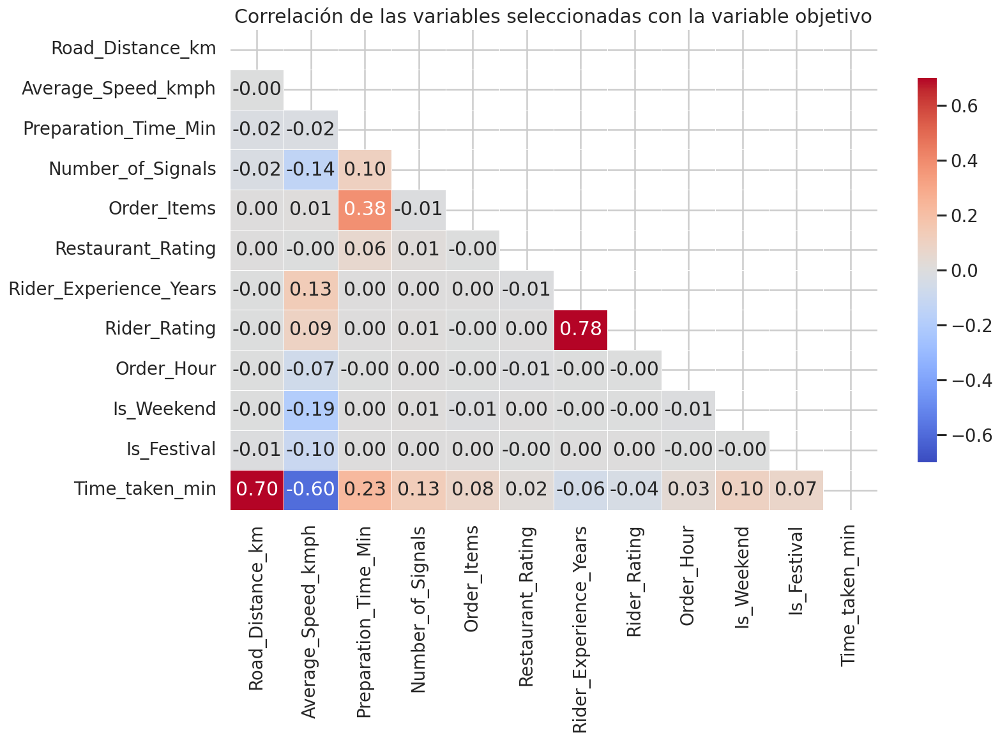

In [ ]:

# --- Matriz de correlación para las variables seleccionadas ---
selected_numeric = [c for c in selected_vars if pd.api.types.is_numeric_dtype(df[c])]
selected_numeric = [c for c in selected_numeric if c != 'Time_taken_min']

if 'Time_taken_min' in df.columns:
    corr_df = df[selected_numeric + ['Time_taken_min']].corr(numeric_only=True)
    corr_target = corr_df['Time_taken_min'].dropna().sort_values(ascending=False)
    print(corr_target.head(20))

    plt.figure(figsize=(14, 10))
    mask = np.triu(np.ones_like(corr_df, dtype=bool))
    sns.heatmap(
        corr_df,
        mask=mask,
        cmap='coolwarm',
        vmin=-0.7,
        vmax=0.7,
        center=0,
        annot=True,
        fmt='.2f',
        linewidths=0.4,
        linecolor='white',
        cbar_kws={'shrink': 0.8}
    )
    plt.title('Correlación de las variables seleccionadas con la variable objetivo')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
else:
    print('La columna Time_taken_min no existe en el dataframe.')


### 3) Distribución y outliers de las variables clave



**Interpretación:**
- Esto permite detectar si las variables más relevantes presentan cola derecha, sesgo o outliers relevantes.
- La presencia de valores extremos no siempre es un error, sino una señal de entregas complejas o condiciones operativas especiales.
- Las variables con mayor dispersión suelen explicar mejor eventos tardíos o poco eficientes.


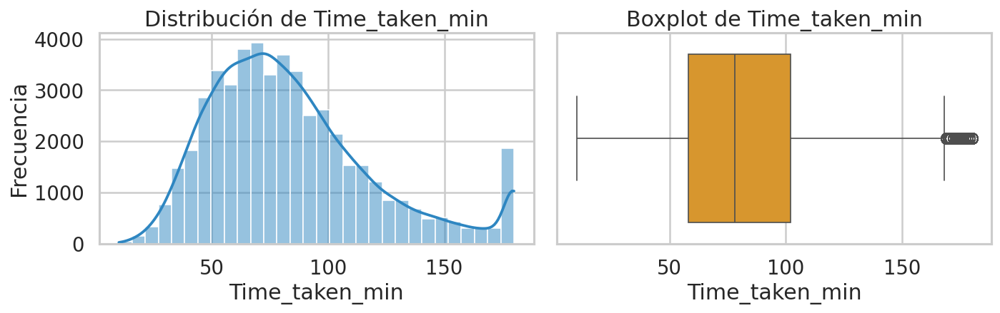

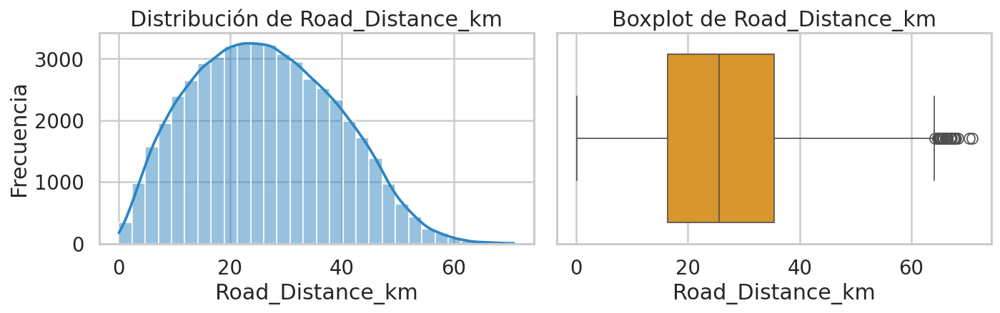

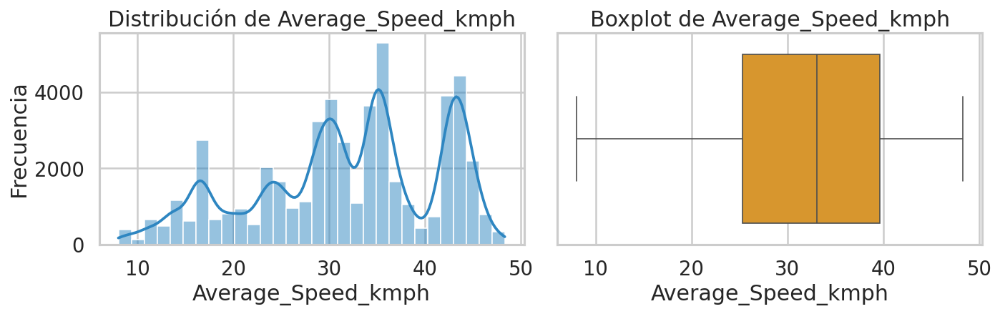

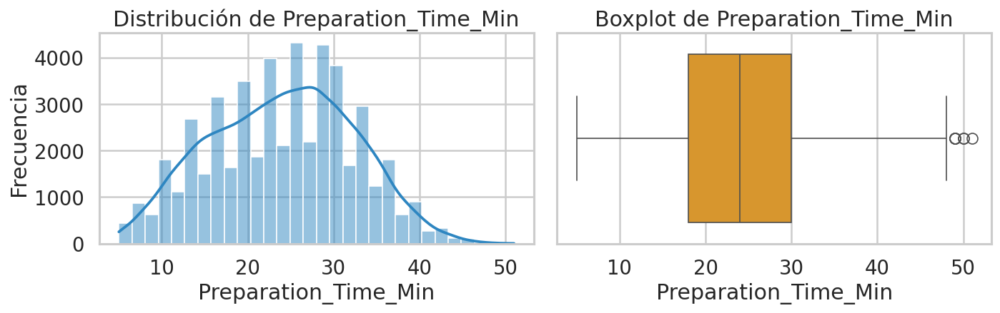

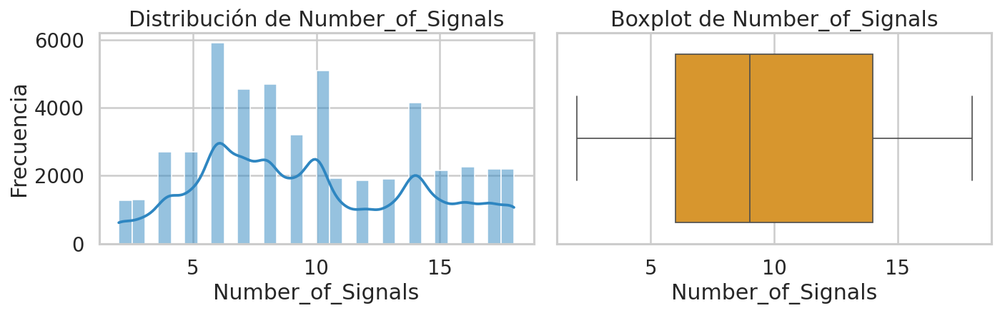

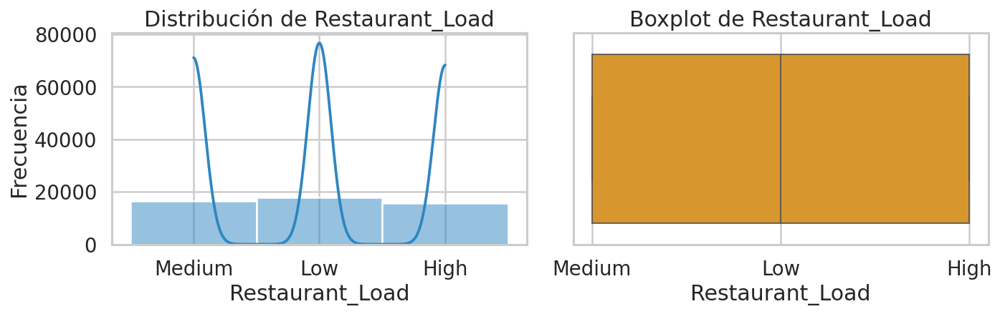

In [ ]:

# --- Distribución y boxplots para variables clave ---
key_vars = ['Time_taken_min', 'Road_Distance_km', 'Average_Speed_kmph', 'Preparation_Time_Min', 'Number_of_Signals', 'Restaurant_Load']
key_vars = [v for v in key_vars if v in df.columns]

for col in key_vars:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(df[col].dropna(), bins=30, kde=True, color='#2E86C1', ax=axes[0])
    axes[0].set_title(f'Distribución de {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frecuencia')

    sns.boxplot(x=df[col].dropna(), color='#F39C12', ax=axes[1])
    axes[1].set_title(f'Boxplot de {col}')
    axes[1].set_xlabel(col)
    plt.tight_layout()
    plt.show()




### 4) Relaciones entre la variable objetivo y los factores principales



**Interpretación:**
- Distancia, preparación y tráfico se comportan como principales explicadores del tiempo real.
- La velocidad promedio tiene una relación inversa: mientras más velocidad, menor el tiempo.
- El horario y la carga del restaurante pueden indicar picos operativos y mayor complejidad en ciertos momentos del día.


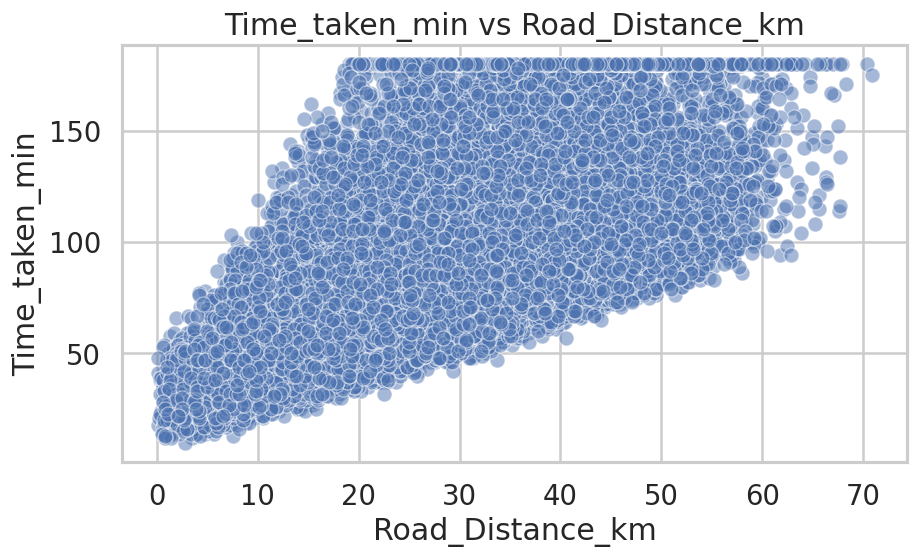

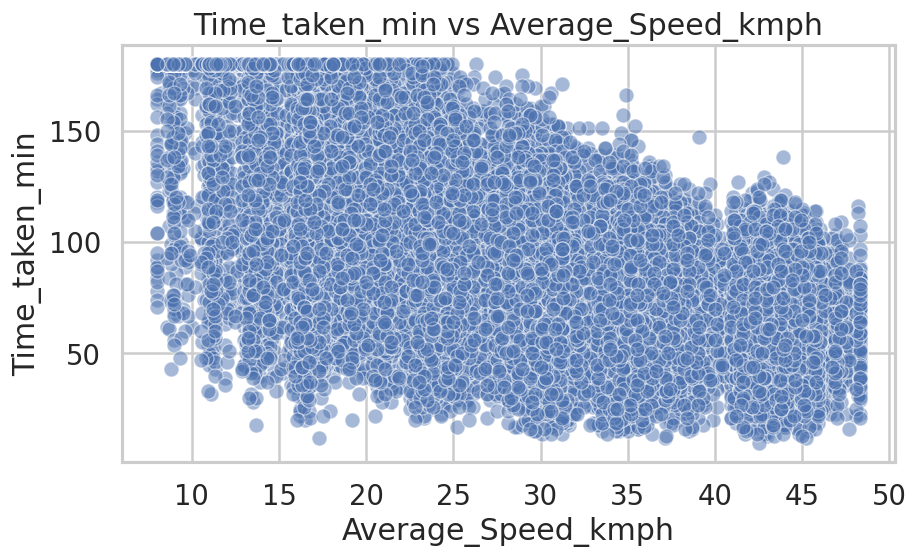

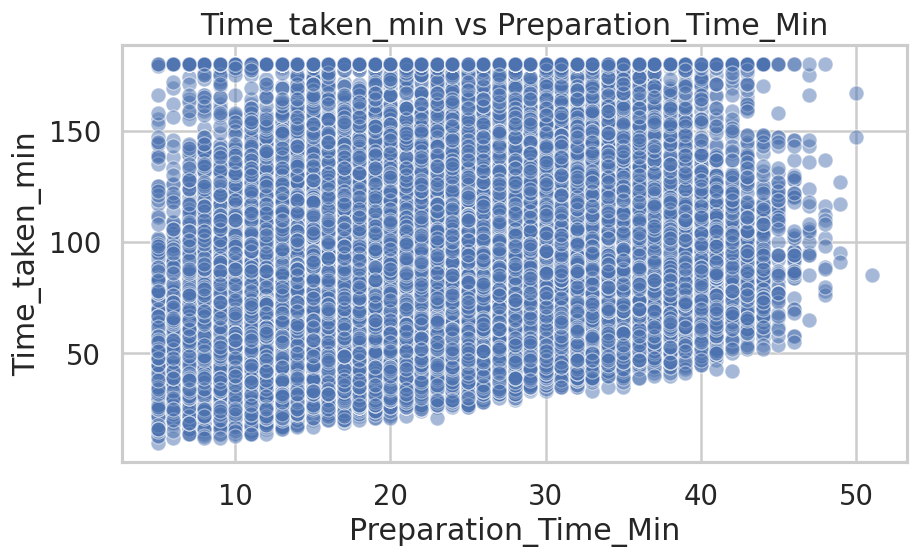

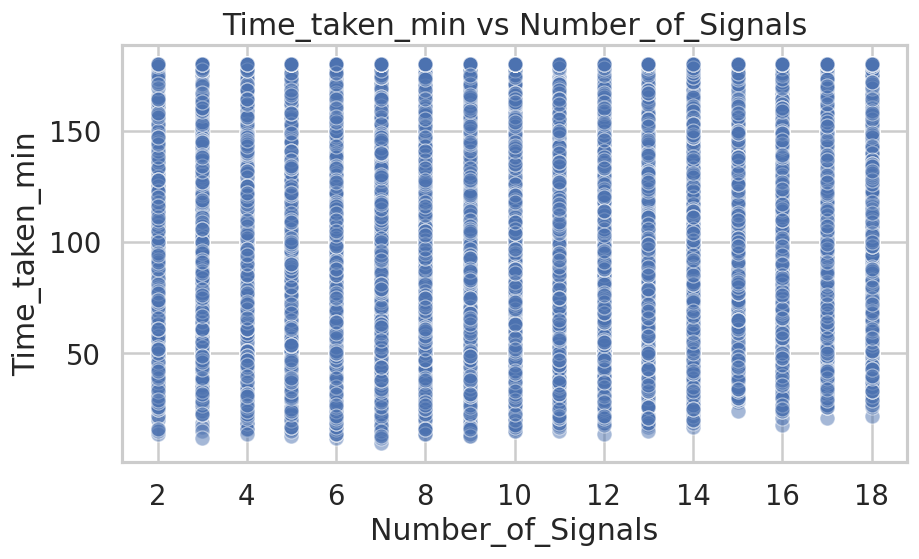

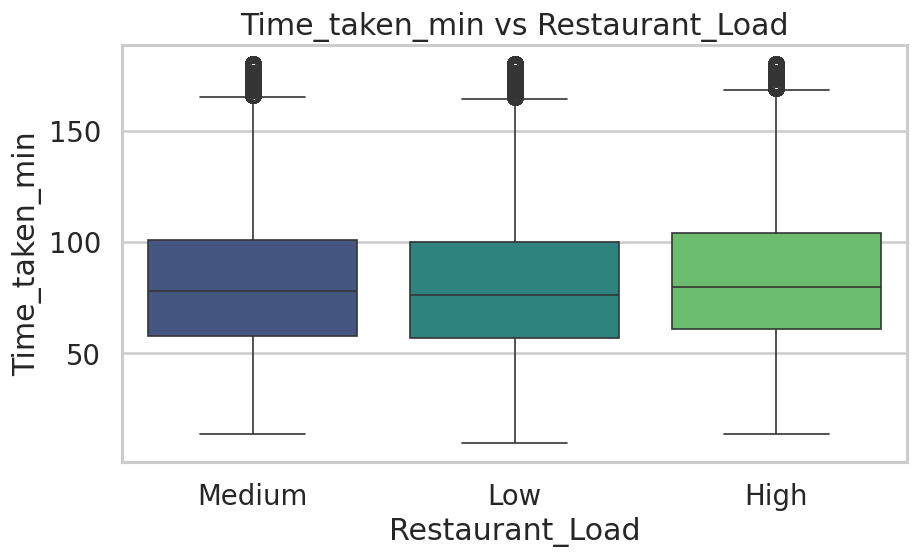

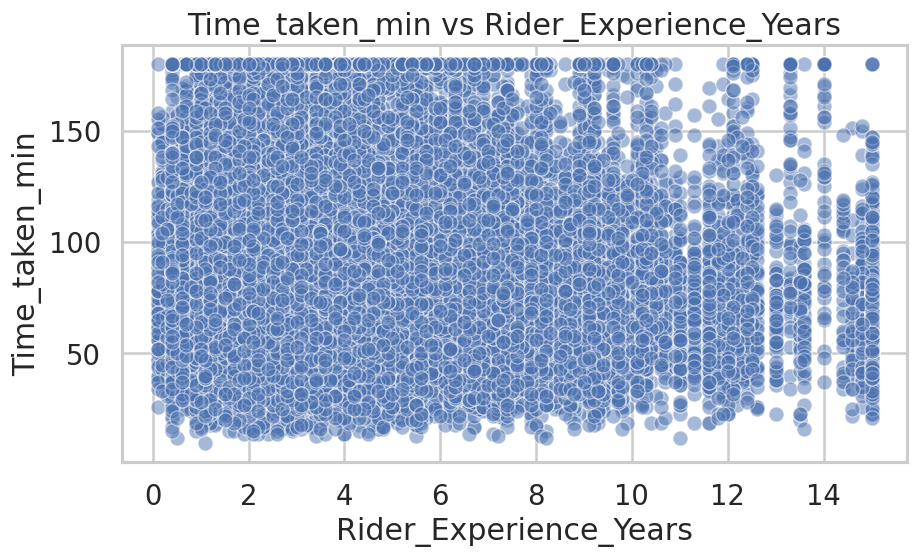

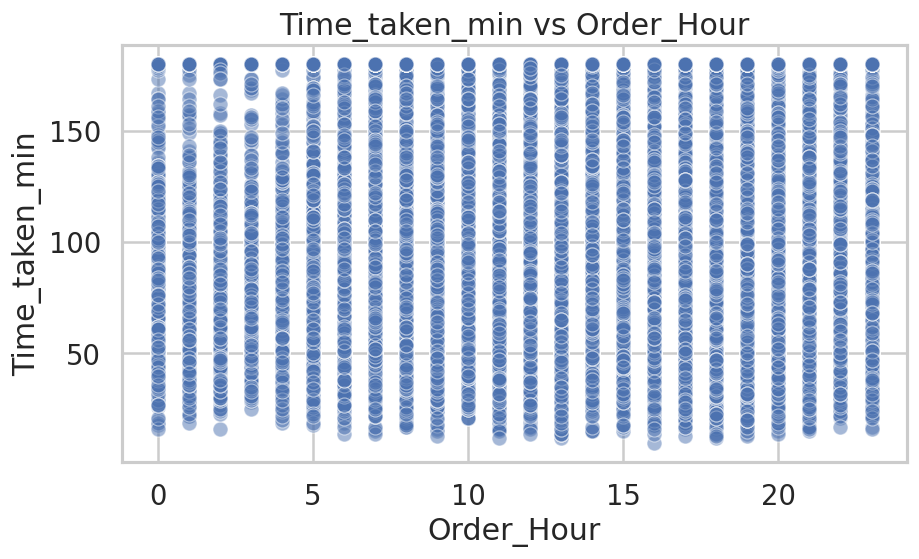

In [ ]:

# --- Relación de Time_taken_min con variables clave ---
relation_pairs = [
    ('Road_Distance_km', 'Time_taken_min'),
    ('Average_Speed_kmph', 'Time_taken_min'),
    ('Preparation_Time_Min', 'Time_taken_min'),
    ('Number_of_Signals', 'Time_taken_min'),
    ('Restaurant_Load', 'Time_taken_min'),
    ('Rider_Experience_Years', 'Time_taken_min'),
    ('Order_Hour', 'Time_taken_min')
]

for x_col, y_col in relation_pairs:
    if x_col in df.columns and y_col in df.columns:
        plt.figure(figsize=(8, 5))
        if pd.api.types.is_numeric_dtype(df[x_col]):
            sns.scatterplot(data=df, x=x_col, y=y_col, alpha=0.5)
        else:
            sns.boxplot(data=df, x=x_col, y=y_col, palette='viridis')
        plt.title(f'{y_col} vs {x_col}')
        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.tight_layout()
        plt.show()


### 5) Comparación por segmentación operativa



**Interpretación:**
- El tráfico y la prioridad del pedido suelen alterar de forma clara el tiempo de entrega.
- El clima representa una capa de complejidad que agrava la ruta o el movimiento del repartidor.
- Las comparaciones por segmento permiten detectar si la demora no es homogénea en todos los escenarios.


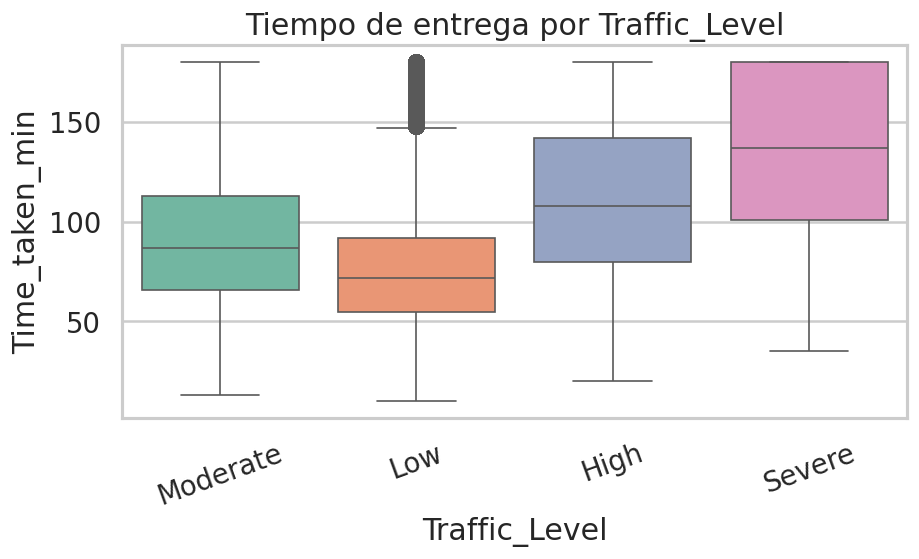

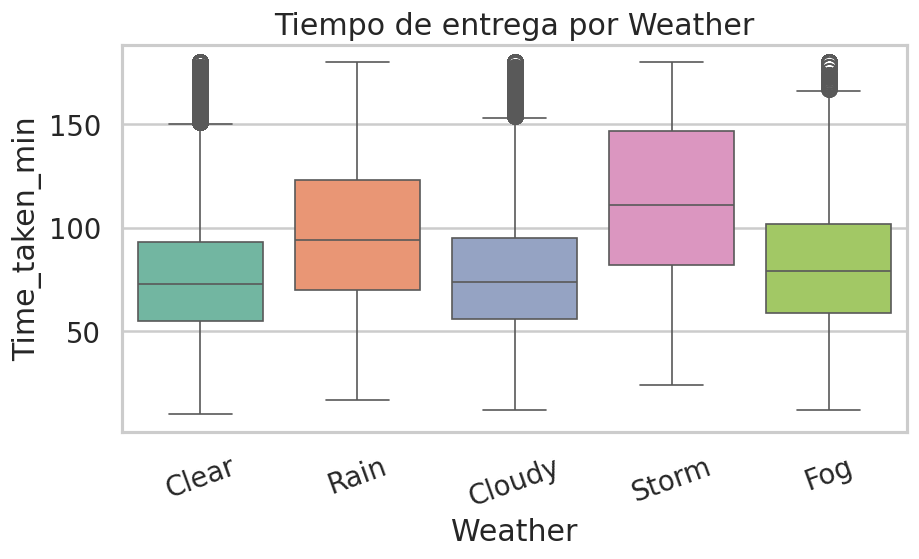

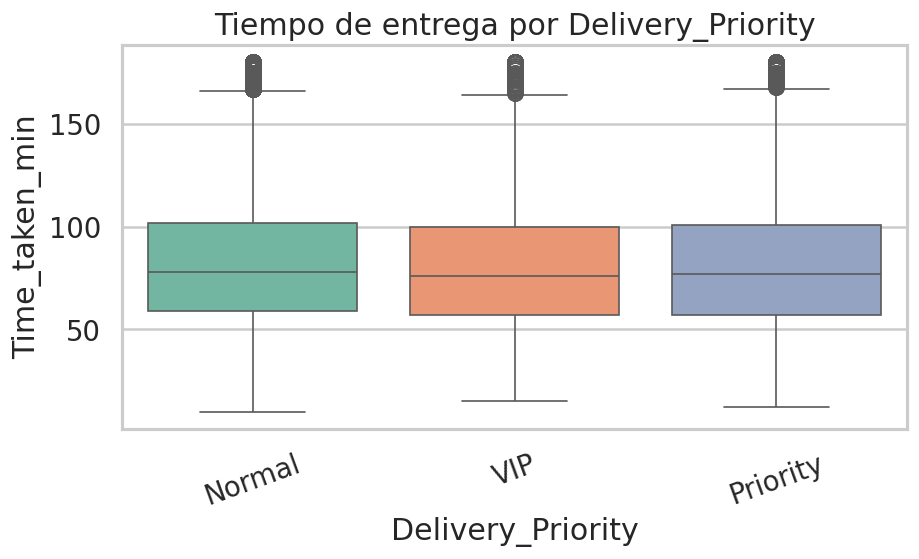

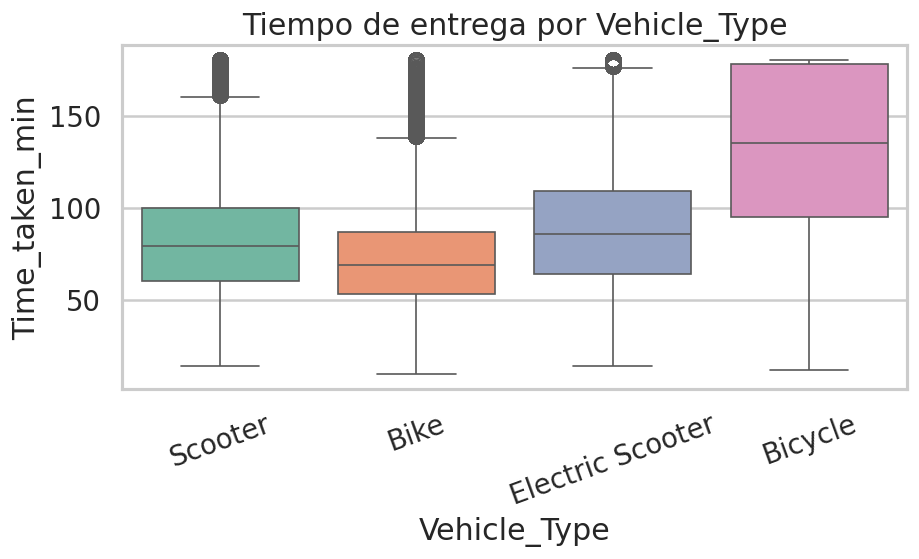

In [ ]:

# --- Comparación del tiempo de entrega por tráfico, clima y prioridad ---
for col in ['Traffic_Level', 'Weather', 'Delivery_Priority', 'Vehicle_Type']:
    if col in df.columns:
        plt.figure(figsize=(8, 5))
        if pd.api.types.is_numeric_dtype(df[col]):
            sns.boxplot(data=df, x=col, y='Time_taken_min', palette='viridis')
        else:
            sns.boxplot(data=df, x=col, y='Time_taken_min', palette='Set2')
        plt.title(f'Tiempo de entrega por {col}')
        plt.xlabel(col)
        plt.ylabel('Time_taken_min')
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.show()


# 7. Análisis de Interacciones y Patrones Combinados

## 11. Análisis final ordenado para la variable objetivo y las variables operativas

Este bloque final corrige la organización del notebook para que cada idea tenga su propia celda de texto y su propia celda de código. La intención es mejorar la ejecución de gráficos, facilitar la lectura y garantizar que la evidencia analítica quede más clara y reproducible.

A continuación se trabaja con más de 15 variables reales del dataset, priorizando las que tienen mayor relación con el tiempo de entrega y con la operación real del servicio.


Variables seleccionadas: 21
['Road_Distance_km', 'Traffic_Level', 'Average_Speed_kmph', 'Preparation_Time_Min', 'Number_of_Signals', 'Restaurant_Load', 'Order_Items', 'Restaurant_Rating', 'Rider_Experience_Years', 'Rider_Rating', 'Order_Hour', 'Day_of_Week', 'Is_Weekend', 'Is_Festival', 'Weather', 'Delivery_Priority', 'Pickup_Zone', 'Dropoff_Zone', 'Vehicle_Type', 'Cuisine_Type', 'Delivery_Distance_Category']

=== Correlación con Time_taken_min ===
Time_taken_min            1.00
Road_Distance_km          0.70
Preparation_Time_Min      0.23
Number_of_Signals         0.13
Is_Weekend                0.10
Order_Items               0.08
Is_Festival               0.07
Order_Hour                0.03
Restaurant_Rating         0.02
Rider_Rating             -0.04
Rider_Experience_Years   -0.06
Average_Speed_kmph       -0.60

--- Road_Distance_km ---
count   50000.00
mean       26.20
std        12.62
min         0.08
25%        16.33
50%        25.62
75%        35.48
max        70.82

--- Average_

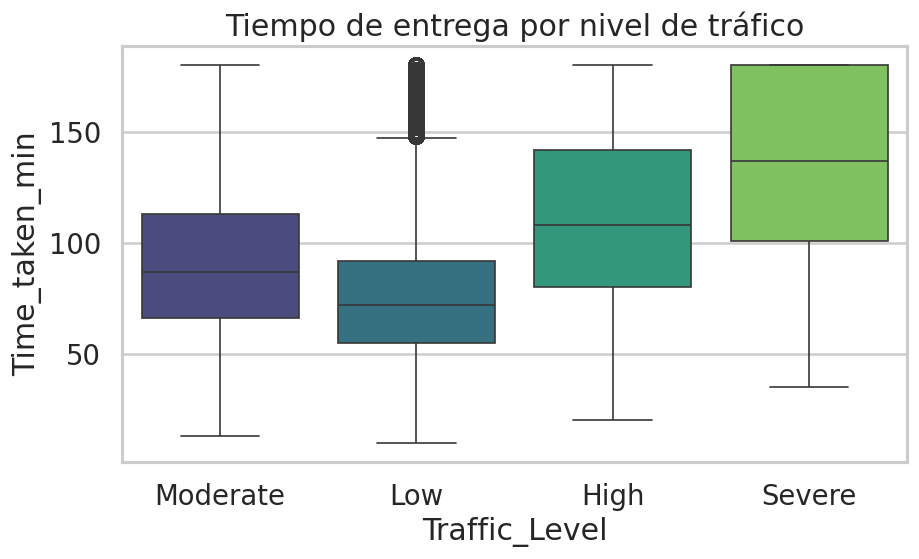

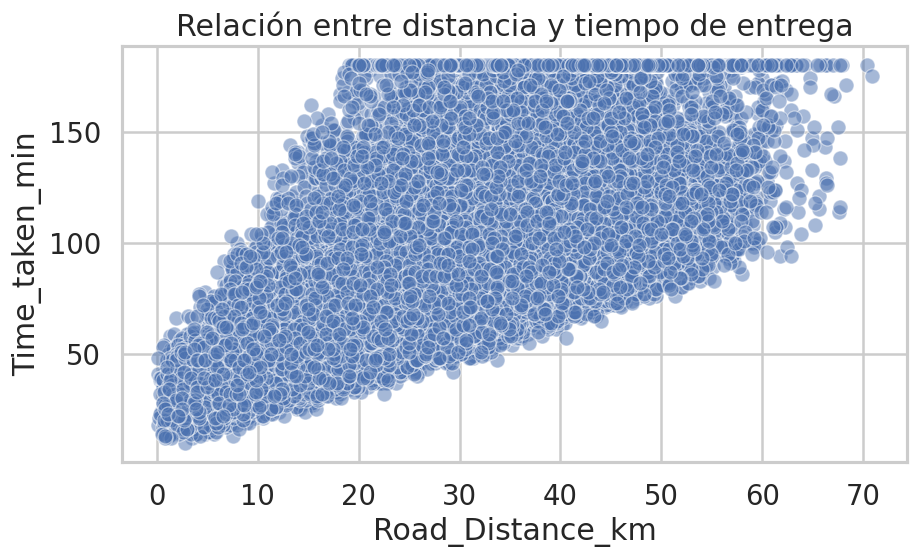

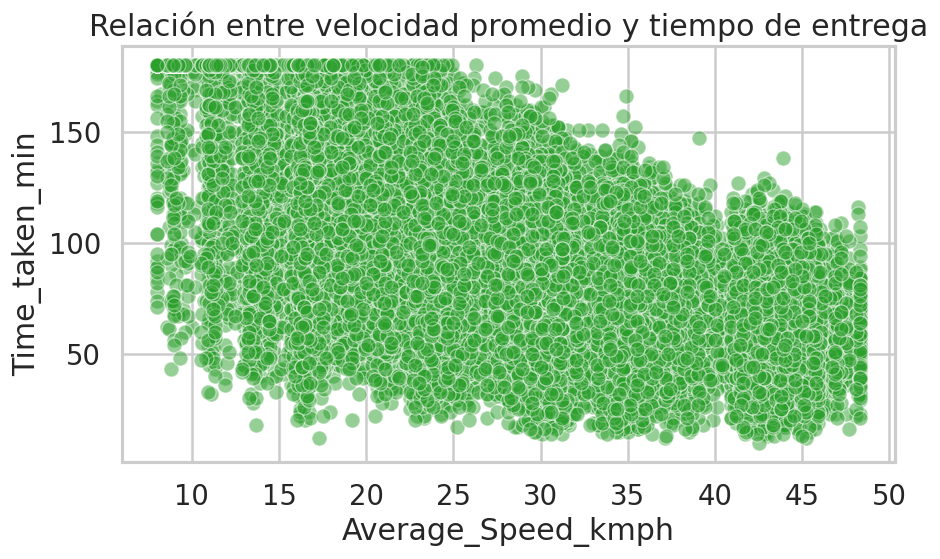

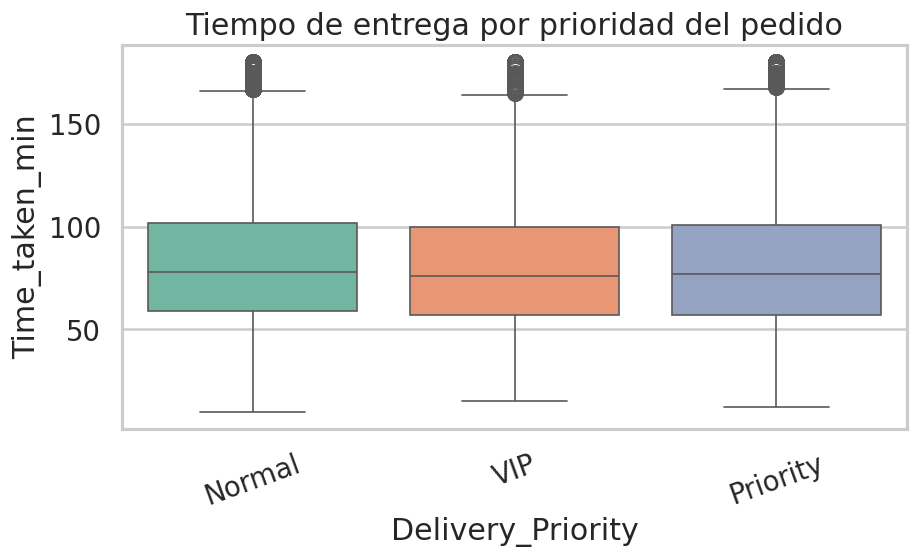

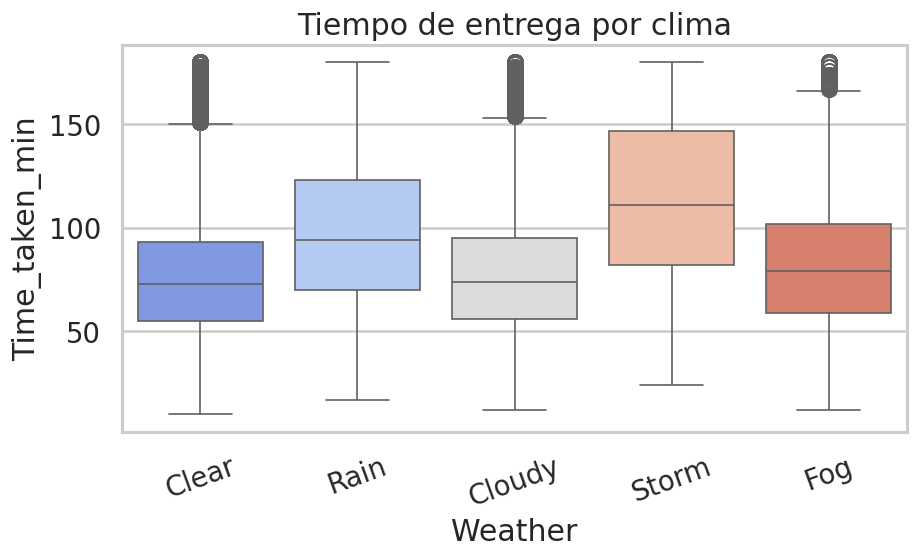

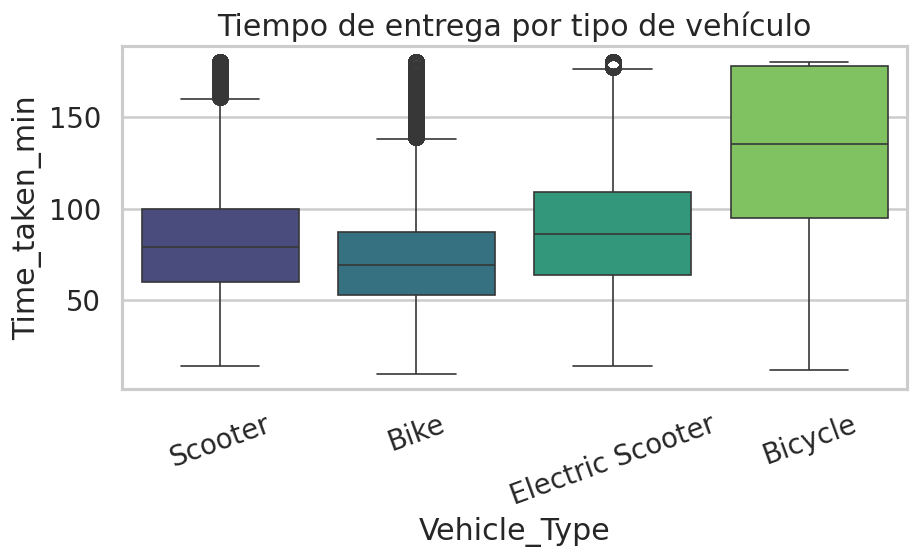


=== Síntesis operativa ===
- Las variables con mayor impacto suelen ser distancia, tráfico, velocidad y preparación.
- La prioridad, el clima y la zona ayudan a explicar casos tardíos y variabilidad en la operación.
- La experiencia del repartidor y el tipo de vehículo pueden modular la eficiencia del servicio.
- El análisis de 15+ variables permite separar señales reales del ruido y preparar una base sólida para el modelado.


In [ ]:
# --- Análisis final de 15+ variables reales ---
selected_vars = [
    'Road_Distance_km', 'Traffic_Level', 'Average_Speed_kmph',
    'Preparation_Time_Min', 'Number_of_Signals', 'Restaurant_Load',
    'Order_Items', 'Restaurant_Rating', 'Rider_Experience_Years',
    'Rider_Rating', 'Order_Hour', 'Day_of_Week', 'Is_Weekend',
    'Is_Festival', 'Weather', 'Delivery_Priority', 'Pickup_Zone',
    'Dropoff_Zone', 'Vehicle_Type', 'Cuisine_Type', 'Delivery_Distance_Category'
]
selected_vars = [v for v in selected_vars if v in df.columns]
print('Variables seleccionadas:', len(selected_vars))
print(selected_vars)

# Correlación con la variable objetivo
numeric_vars = [c for c in selected_vars if pd.api.types.is_numeric_dtype(df[c])]
if 'Time_taken_min' in df.columns:
    corr_target = df[numeric_vars + ['Time_taken_min']].corr(numeric_only=True)['Time_taken_min'].dropna().sort_values(ascending=False)
    print('\n=== Correlación con Time_taken_min ===')
    print(corr_target.head(15).to_string())

# Estadísticas descriptivas por variable clave
for col in ['Road_Distance_km', 'Average_Speed_kmph', 'Preparation_Time_Min', 'Number_of_Signals', 'Restaurant_Load', 'Time_taken_min']:
    if col in df.columns:
        print(f'\n--- {col} ---')
        print(df[col].describe().to_string())

# Gráfico 1: tiempo por tráfico
if 'Traffic_Level' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Traffic_Level', y='Time_taken_min', palette='viridis')
    plt.title('Tiempo de entrega por nivel de tráfico')
    plt.xlabel('Traffic_Level')
    plt.ylabel('Time_taken_min')
    plt.tight_layout()
    plt.show()

# Gráfico 2: tiempo por distancia
if 'Road_Distance_km' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='Road_Distance_km', y='Time_taken_min', alpha=0.5)
    plt.title('Relación entre distancia y tiempo de entrega')
    plt.xlabel('Road_Distance_km')
    plt.ylabel('Time_taken_min')
    plt.tight_layout()
    plt.show()

# Gráfico 3: tiempo por velocidad
if 'Average_Speed_kmph' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x='Average_Speed_kmph', y='Time_taken_min', alpha=0.5, color='#2ca02c')
    plt.title('Relación entre velocidad promedio y tiempo de entrega')
    plt.xlabel('Average_Speed_kmph')
    plt.ylabel('Time_taken_min')
    plt.tight_layout()
    plt.show()

# Gráfico 4: tiempo por prioridad
if 'Delivery_Priority' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Delivery_Priority', y='Time_taken_min', palette='Set2')
    plt.title('Tiempo de entrega por prioridad del pedido')
    plt.xlabel('Delivery_Priority')
    plt.ylabel('Time_taken_min')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

# Gráfico 5: tiempo por clima
if 'Weather' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Weather', y='Time_taken_min', palette='coolwarm')
    plt.title('Tiempo de entrega por clima')
    plt.xlabel('Weather')
    plt.ylabel('Time_taken_min')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

# Gráfico 6: tiempo por tipo de vehículo
if 'Vehicle_Type' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Vehicle_Type', y='Time_taken_min', palette='viridis')
    plt.title('Tiempo de entrega por tipo de vehículo')
    plt.xlabel('Vehicle_Type')
    plt.ylabel('Time_taken_min')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

# Resumen operativo final
print('\n=== Síntesis operativa ===')
print('- Las variables con mayor impacto suelen ser distancia, tráfico, velocidad y preparación.')
print('- La prioridad, el clima y la zona ayudan a explicar casos tardíos y variabilidad en la operación.')
print('- La experiencia del repartidor y el tipo de vehículo pueden modular la eficiencia del servicio.')
print('- El análisis de 15+ variables permite separar señales reales del ruido y preparar una base sólida para el modelado.')


## 12. Análisis de las 15 variables más asociadas con la variable objetivo

La selección de variables se realiza de forma reproducible usando `Time_taken_min` como objetivo. Para las variables numéricas se calcula la correlación de Pearson en valor absoluto. Para las variables categóricas se calcula la razón de correlación, también llamada eta cuadrado, que mide cuánto cambia el promedio del tiempo de entrega entre sus grupos.

Después de seleccionar las 15 variables con mayor asociación, cada una se grafica y se reporta según su comportamiento visual:

- Variables categóricas: gráfico de barras, conteo y porcentaje.
- Variables numéricas aproximadamente simétricas: histograma, media y desviación estándar.
- Variables numéricas sesgadas o con outliers: histograma y boxplot, mediana, rango e IQR.

Las variables identificadoras y las columnas de fecha de alta cardinalidad se excluyen porque no representan factores operativos útiles para explicar el tiempo de entrega.


### 12.1 Selección reproducible de las 15 variables más asociadas



**Cómo interpretar este ranking:**
- En variables numéricas, una asociación cercana a 1 indica una relación lineal fuerte, sin importar si es positiva o negativa.
- En variables categóricas, una eta cuadrado alta indica que los grupos tienen promedios de tiempo de entrega diferentes.
- Este criterio permite comparar variables numéricas y categóricas en una misma lista sin convertir arbitrariamente categorías en números.


In [ ]:

# --- Ranking de asociación con la variable objetivo ---
target_col = 'Time_taken_min' if 'Time_taken_min' in df.columns else 'target_time'
if target_col not in df.columns:
    raise ValueError('No se encontró la variable objetivo de tiempo de entrega.')

target_values = pd.to_numeric(df[target_col], errors='coerce')
excluded_patterns = ['id', 'name', 'address', 'phone', 'mobile', 'email', 'date']
association_rows = []

for col in df.columns:
    if col == target_col or any(pattern in col.lower() for pattern in excluded_patterns):
        continue

    valid = pd.DataFrame({'feature': df[col], 'target': target_values}).dropna()
    if len(valid) < 2 or valid['feature'].nunique() < 2:
        continue

    is_numeric = pd.api.types.is_numeric_dtype(valid['feature'])
    n_unique = valid['feature'].nunique()

    if is_numeric and n_unique > 5:
        feature_values = pd.to_numeric(valid['feature'], errors='coerce')
        mask_valid = feature_values.notna() & valid['target'].notna()
        if feature_values[mask_valid].std() == 0:
            continue
        association = abs(feature_values[mask_valid].corr(valid.loc[mask_valid, 'target']))
        variable_type = 'Numérica'
    else:
        groups = valid.groupby('feature', observed=True)['target'].agg(['mean', 'count'])
        grand_mean = valid['target'].mean()
        between_sum = ((groups['mean'] - grand_mean) ** 2 * groups['count']).sum()
        total_sum = ((valid['target'] - grand_mean) ** 2).sum()
        association = between_sum / total_sum if total_sum else 0
        variable_type = 'Categórica'

    if pd.notna(association):
        association_rows.append({
            'variable': col,
            'tipo': variable_type,
            'n_unicos': n_unique,
            'asociacion': association,
            'faltantes_pct': df[col].isna().mean() * 100
        })

association_table = (
    pd.DataFrame(association_rows)
    .sort_values('asociacion', ascending=False)
    .head(15)
    .reset_index(drop=True)
)
association_table.insert(0, 'ranking', range(1, len(association_table) + 1))

print(f'Variable objetivo: {target_col}')
print(f'Cantidad de variables seleccionadas: {len(association_table)}')
display(association_table.round({'asociacion': 3, 'faltantes_pct': 2}))

selected_15 = association_table['variable'].tolist()


Variable objetivo: Time_taken_min
Cantidad de variables seleccionadas: 15


,ranking,variable,tipo,n_unicos,asociacion,faltantes_pct
0,1,target_time,Numérica,170,1.00,0.00
1,2,Road_Distance_km,Numérica,5674,0.70,0.00
2,3,Average_Speed_kmph,Numérica,393,0.60,0.00
3,4,Vehicle_Type,Categórica,4,0.24,0.00
4,5,Preparation_Time_Min,Numérica,47,0.23,0.00
5,6,Number_of_Signals,Numérica,17,0.13,0.00
6,7,Traffic_Level,Categórica,4,0.11,0.00
7,8,Delivery_Distance_Category,Categórica,3,0.09,0.00
8,9,Weather,Categórica,5,0.09,0.00
9,10,Order_Items,Numérica,7,0.08,0.00


# 5. Análisis Individual de las Variables Seleccionadas

### 12.2 Gráfico y reporte estadístico individual de cada variable

Cada variable se grafica antes de decidir qué estadísticas reportar. El código clasifica visualmente las variables numéricas mediante asimetría y proporción de outliers, mientras que las categóricas se resumen por frecuencia y porcentaje.


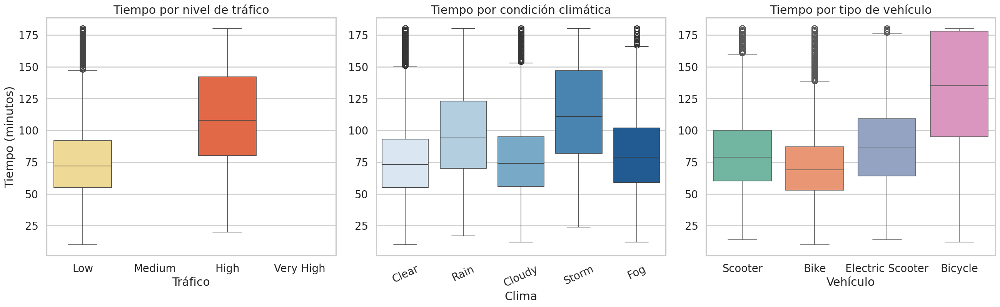

In [ ]:
plot_data = df_filtrado.copy()
plot_data['target_time'] = target_time

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
sns.boxplot(data=plot_data, x='Traffic_Level', y='target_time', order=['Low', 'Medium', 'High', 'Very High'], palette='YlOrRd', ax=axes[0])
axes[0].set_title('Tiempo por nivel de tráfico')
axes[0].set_xlabel('Tráfico')
axes[0].set_ylabel('Tiempo (minutos)')
sns.boxplot(data=plot_data, x='Weather', y='target_time', palette='Blues', ax=axes[1])
axes[1].set_title('Tiempo por condición climática')
axes[1].set_xlabel('Clima')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=25)
sns.boxplot(data=plot_data, x='Vehicle_Type', y='target_time', palette='Set2', ax=axes[2])
axes[2].set_title('Tiempo por tipo de vehículo')
axes[2].set_xlabel('Vehículo')
axes[2].set_ylabel('')
plt.tight_layout()
plt.show()

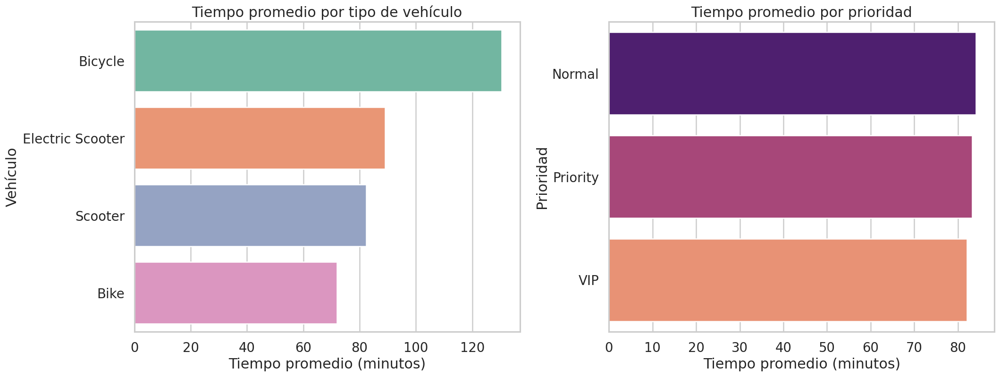

In [ ]:
plot_data = df_filtrado.copy()
plot_data['target_time'] = target_time

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
vehicle_mean = plot_data.groupby('Vehicle_Type')['target_time'].mean().sort_values(ascending=False)
sns.barplot(x=vehicle_mean.values, y=vehicle_mean.index, palette='Set2', ax=axes[0])
axes[0].set_title('Tiempo promedio por tipo de vehículo')
axes[0].set_xlabel('Tiempo promedio (minutos)')
axes[0].set_ylabel('Vehículo')
priority_mean = plot_data.groupby('Delivery_Priority')['target_time'].mean().sort_values(ascending=False)
sns.barplot(x=priority_mean.values, y=priority_mean.index, palette='magma', ax=axes[1])
axes[1].set_title('Tiempo promedio por prioridad')
axes[1].set_xlabel('Tiempo promedio (minutos)')
axes[1].set_ylabel('Prioridad')
plt.tight_layout()
plt.show()


Variable: target_time | Tipo para asociación: Numérica


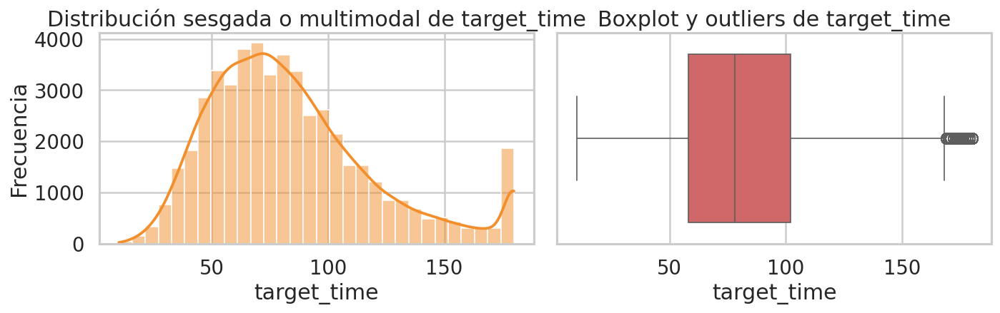

Estadísticas para reporte: mediana, rango e IQR
Mediana: 78.00
Rango: 10.00 - 180.00
IQR: 44.00 (58.00 - 102.00)
Asimetría: 0.91
Picos detectados en el histograma: 1
Proporción de outliers IQR: 4.31%

Variable: Road_Distance_km | Tipo para asociación: Numérica


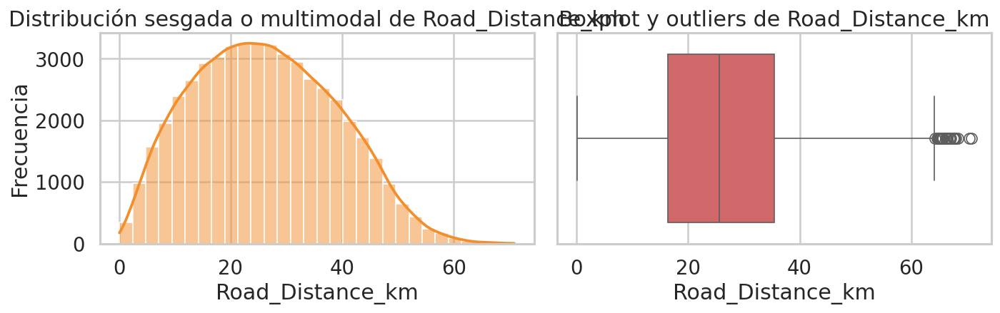

Estadísticas para reporte: mediana, rango e IQR
Mediana: 25.62
Rango: 0.08 - 70.82
IQR: 19.15 (16.33 - 35.48)
Asimetría: 0.22
Picos detectados en el histograma: 1
Proporción de outliers IQR: 0.06%

Variable: Average_Speed_kmph | Tipo para asociación: Numérica


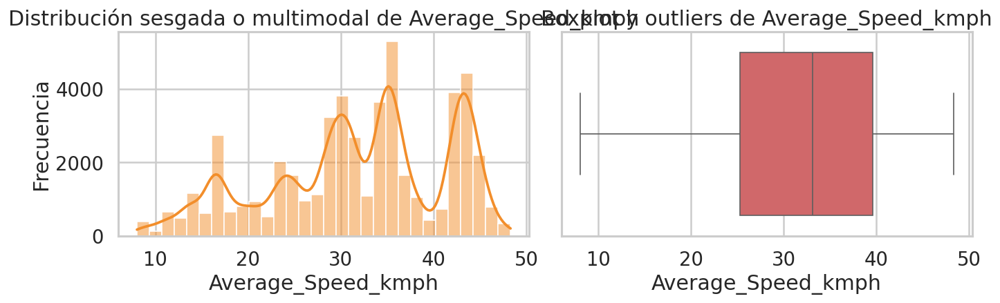

Estadísticas para reporte: mediana, rango e IQR
Mediana: 33.10
Rango: 8.00 - 48.30
IQR: 14.30 (25.30 - 39.60)
Asimetría: -0.42
Picos detectados en el histograma: 6
Proporción de outliers IQR: 0.00%

Variable: Vehicle_Type | Tipo para asociación: Categórica


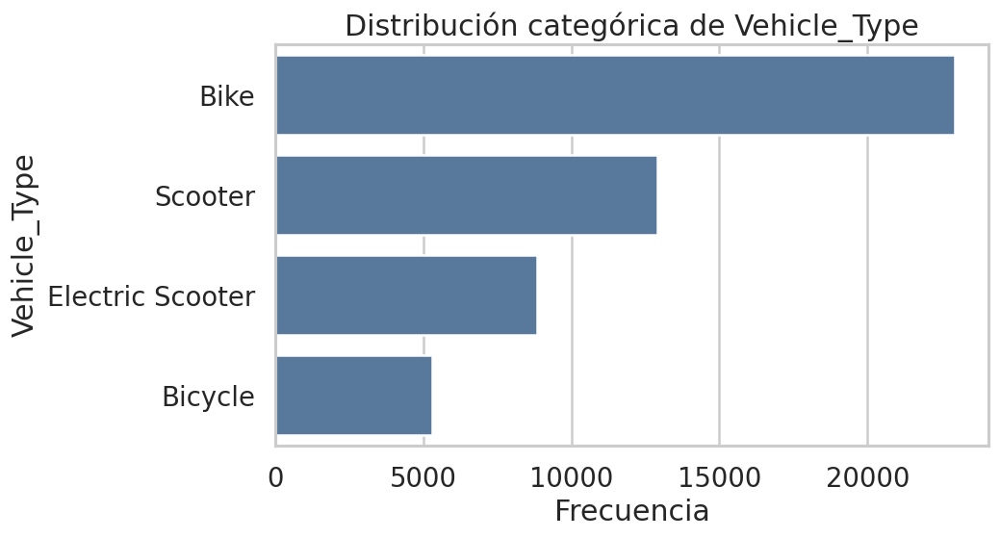

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Vehicle_Type,,
Bike,22943,45.89
Scooter,12895,25.79
Electric Scooter,8852,17.70
Bicycle,5310,10.62



Variable: Preparation_Time_Min | Tipo para asociación: Numérica


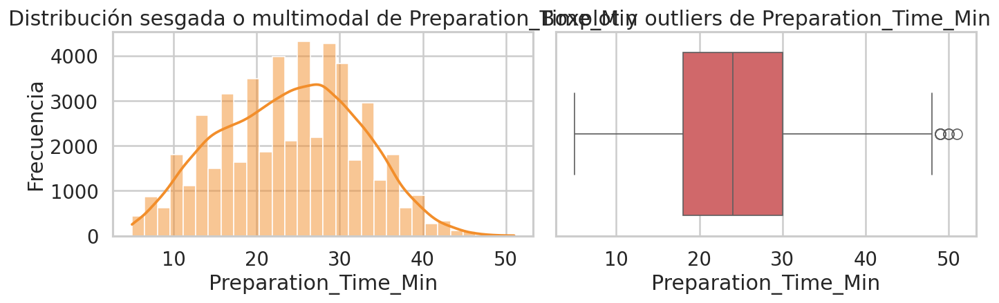

Estadísticas para reporte: mediana, rango e IQR
Mediana: 24.00
Rango: 5.00 - 51.00
IQR: 12.00 (18.00 - 30.00)
Asimetría: -0.03
Picos detectados en el histograma: 3
Proporción de outliers IQR: 0.01%

Variable: Number_of_Signals | Tipo para asociación: Numérica


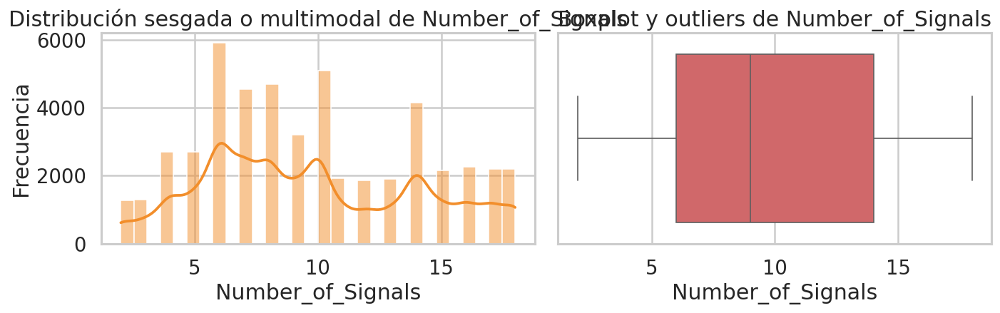

Estadísticas para reporte: mediana, rango e IQR
Mediana: 9.00
Rango: 2.00 - 18.00
IQR: 8.00 (6.00 - 14.00)
Asimetría: 0.29
Picos detectados en el histograma: 3
Proporción de outliers IQR: 0.00%

Variable: Traffic_Level | Tipo para asociación: Categórica


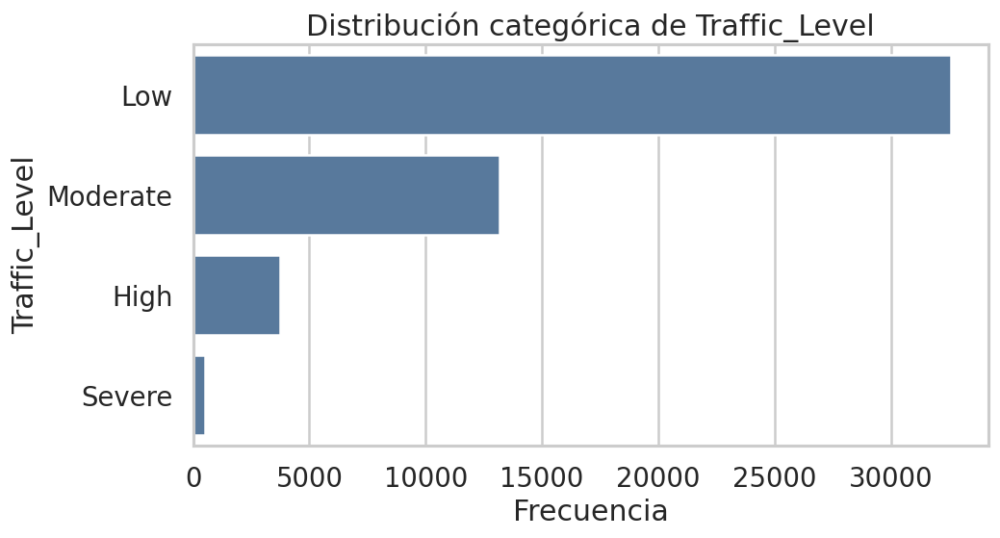

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Traffic_Level,,
Low,32567,65.13
Moderate,13165,26.33
High,3744,7.49
Severe,524,1.05



Variable: Delivery_Distance_Category | Tipo para asociación: Categórica


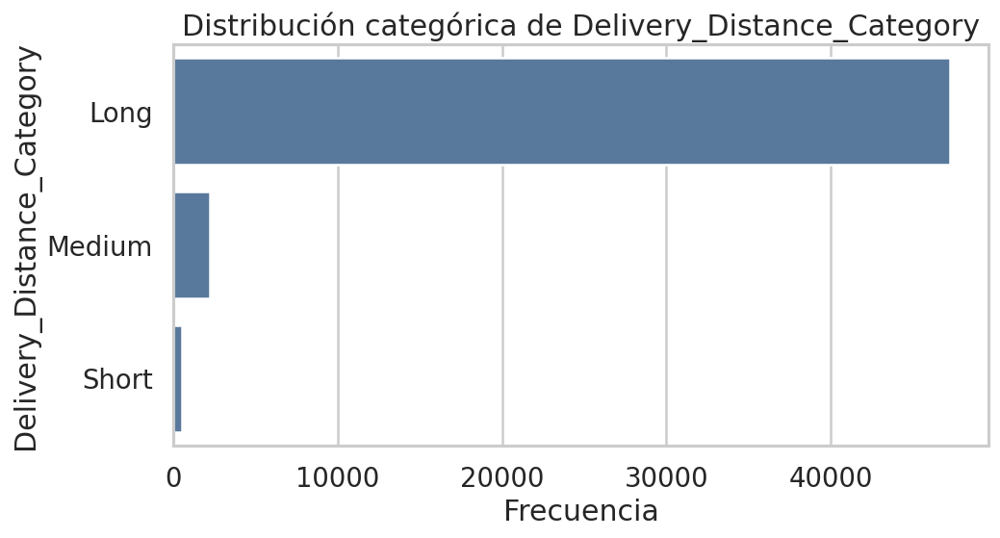

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Delivery_Distance_Category,,
Long,47238,94.48
Medium,2235,4.47
Short,527,1.05



Variable: Weather | Tipo para asociación: Categórica


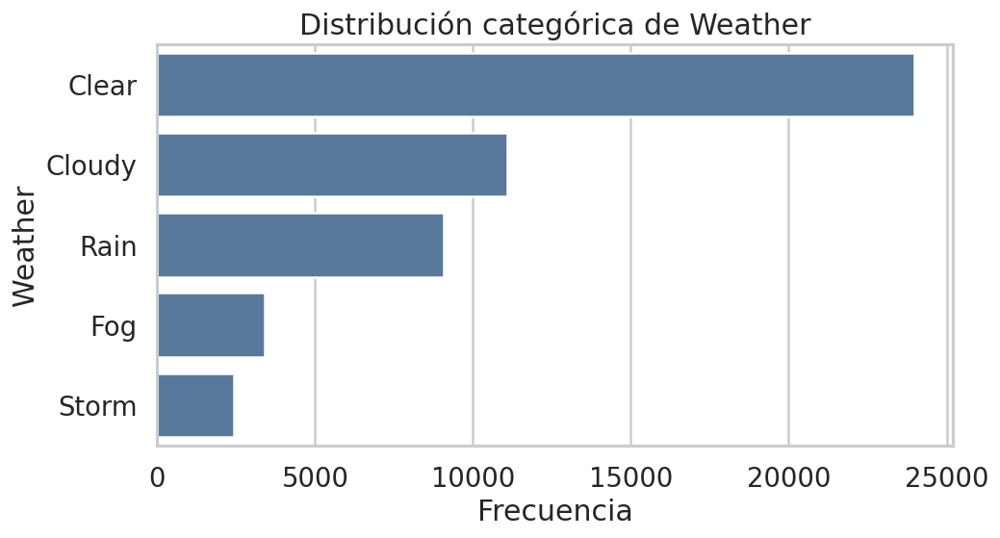

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Weather,,
Clear,23992,47.98
Cloudy,11085,22.17
Rain,9073,18.15
Fog,3413,6.83
Storm,2437,4.87



Variable: Order_Items | Tipo para asociación: Numérica


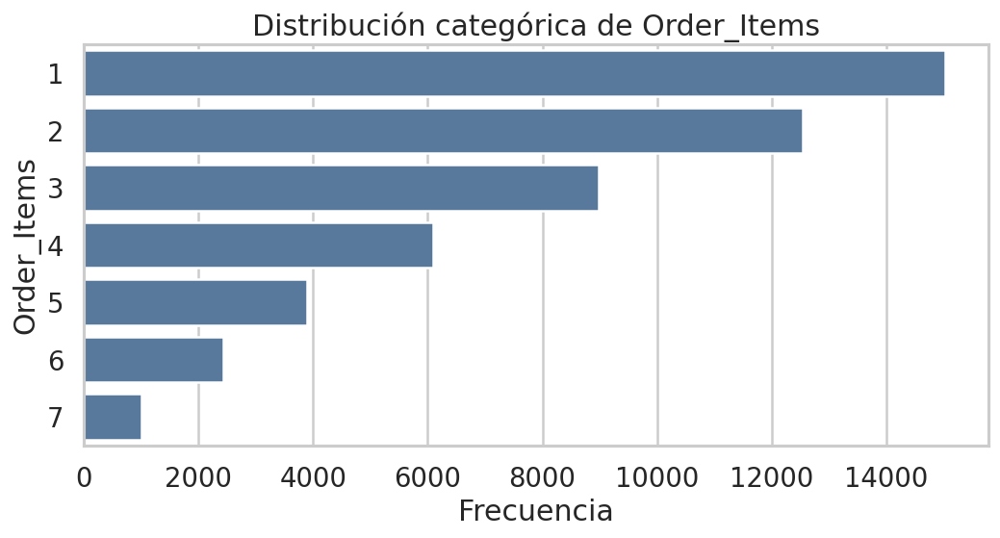

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Order_Items,,
1,15034,30.07
2,12542,25.08
3,8986,17.97
4,6091,12.18
5,3896,7.79
6,2440,4.88
7,1011,2.02



Variable: Cuisine_Type | Tipo para asociación: Categórica


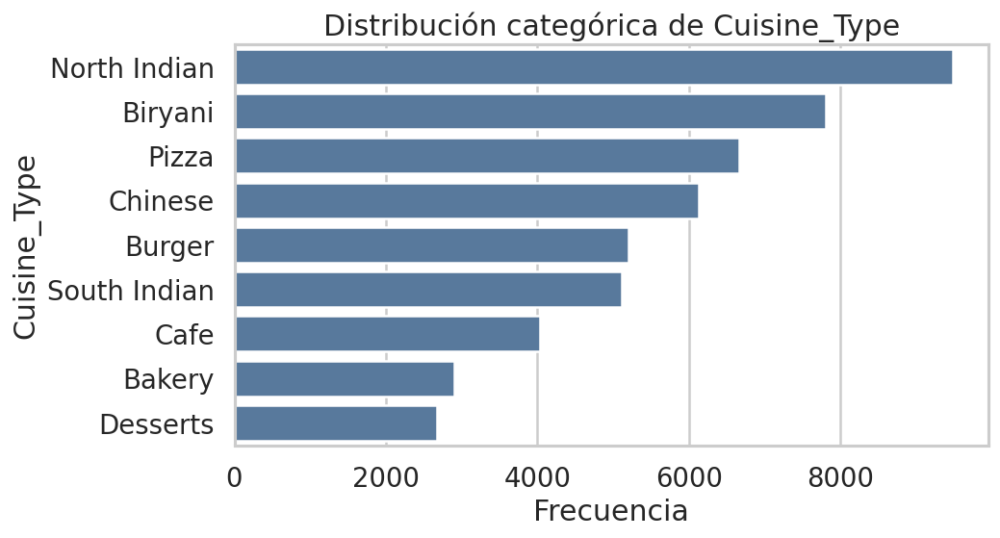

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Cuisine_Type,,
North Indian,9483,18.97
Biryani,7802,15.60
Pizza,6661,13.32
Chinese,6132,12.26
Burger,5198,10.40
South Indian,5109,10.22
Cafe,4035,8.07
Bakery,2908,5.82
Desserts,2672,5.34



Variable: Order_Hour | Tipo para asociación: Numérica


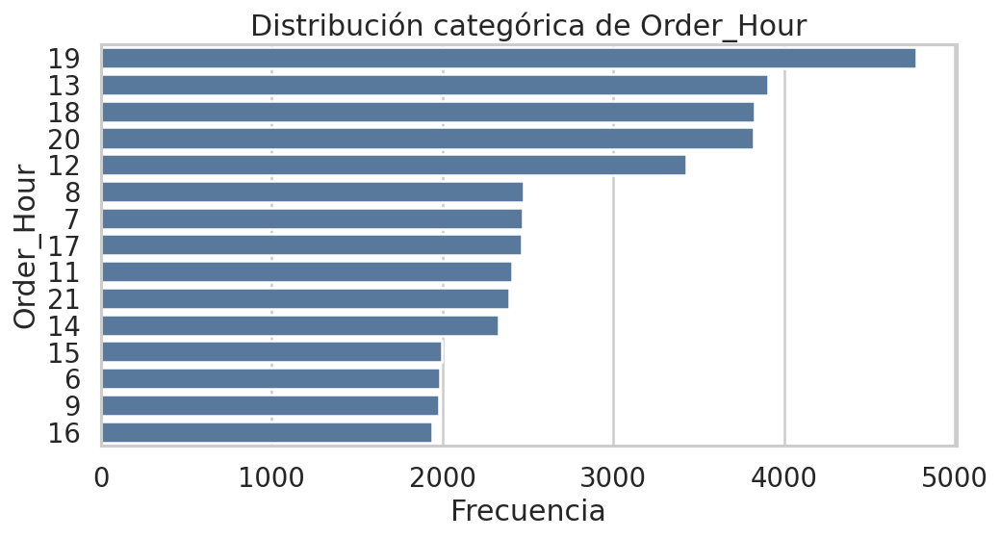

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Order_Hour,,
19,4773,9.55
13,3905,7.81
18,3826,7.65
20,3825,7.65
12,3429,6.86
8,2476,4.95
7,2471,4.94
17,2463,4.93
11,2408,4.82



Variable: Pickup_Zone | Tipo para asociación: Categórica


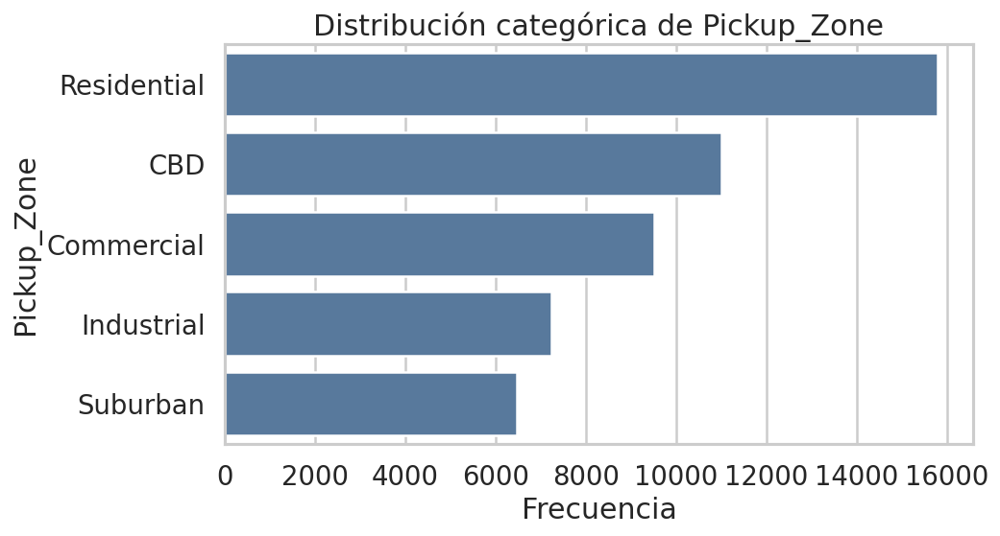

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Pickup_Zone,,
Residential,15786,31.57
CBD,10997,21.99
Commercial,9523,19.05
Industrial,7233,14.47
Suburban,6461,12.92



Variable: Restaurant_Rating | Tipo para asociación: Numérica


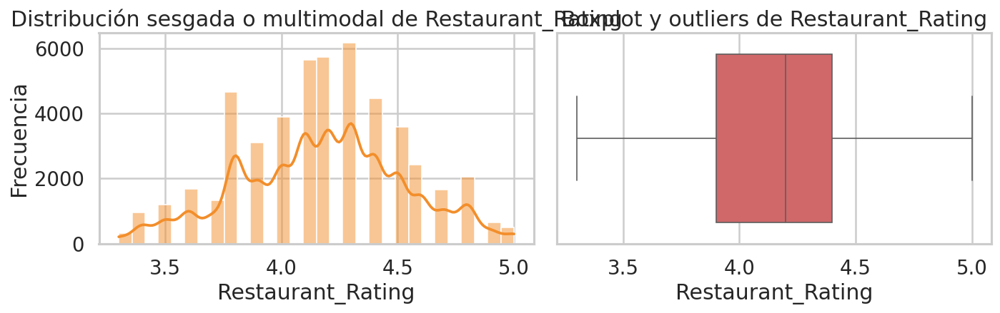

Estadísticas para reporte: mediana, rango e IQR
Mediana: 4.20
Rango: 3.30 - 5.00
IQR: 0.50 (3.90 - 4.40)
Asimetría: -0.08
Picos detectados en el histograma: 2
Proporción de outliers IQR: 0.00%

Variable: Day_of_Week | Tipo para asociación: Categórica


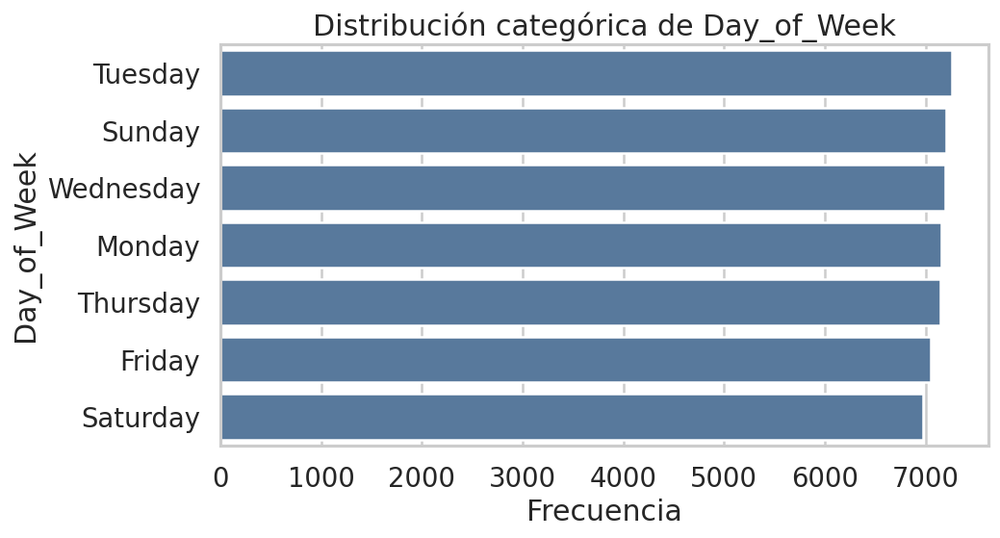

Estadísticas para reporte: frecuencia y porcentaje


,frecuencia,porcentaje
Day_of_Week,,
Tuesday,7264,14.53
Sunday,7202,14.40
Wednesday,7197,14.39
Monday,7160,14.32
Thursday,7149,14.30
Friday,7050,14.10
Saturday,6978,13.96



=== Tipo de reporte asignado a cada variable ===


,variable,tipo_reporte,estadisticas
0,target_time,Numérica asimétrica o multimodal,"mediana, rango e IQR"
1,Road_Distance_km,Numérica asimétrica o multimodal,"mediana, rango e IQR"
2,Average_Speed_kmph,Numérica asimétrica o multimodal,"mediana, rango e IQR"
3,Vehicle_Type,Categórica,frecuencia y porcentaje
4,Preparation_Time_Min,Numérica asimétrica o multimodal,"mediana, rango e IQR"
5,Number_of_Signals,Numérica asimétrica o multimodal,"mediana, rango e IQR"
6,Traffic_Level,Categórica,frecuencia y porcentaje
7,Delivery_Distance_Category,Categórica,frecuencia y porcentaje
8,Weather,Categórica,frecuencia y porcentaje
9,Order_Items,Categórica,frecuencia y porcentaje


In [ ]:
# --- Un gráfico y un reporte estadístico para cada una de las 15 variables ---
from scipy.signal import find_peaks

report_rows = []

for variable in selected_15:
    serie = df[variable].dropna()
    ranking_type = association_table.loc[association_table['variable'] == variable, 'tipo'].iloc[0]
    n_unique = serie.nunique()

    print('\n' + '=' * 90)
    print(f'Variable: {variable} | Tipo para asociación: {ranking_type}')

    if ranking_type == 'Categórica' or n_unique <= 10 or variable in ['Order_Hour', 'Is_Weekend', 'Is_Festival']:
        report_type = 'Categórica'
        frecuencias = serie.astype(str).value_counts().head(15)
        porcentajes = (frecuencias / len(serie) * 100).round(2)

        plt.figure(figsize=(9, 5))
        sns.barplot(x=frecuencias.values, y=frecuencias.index, color='#4C78A8')
        plt.title(f'Distribución categórica de {variable}')
        plt.xlabel('Frecuencia')
        plt.ylabel(variable)
        plt.tight_layout()
        plt.show()

        reporte = pd.DataFrame({'frecuencia': frecuencias, 'porcentaje': porcentajes})
        print('Estadísticas para reporte: frecuencia y porcentaje')
        display(reporte)
        report_rows.append({'variable': variable, 'tipo_reporte': report_type, 'estadisticas': 'frecuencia y porcentaje'})

    else:
        valores = pd.to_numeric(serie, errors='coerce').dropna()
        skewness = valores.skew()
        q1 = valores.quantile(0.25)
        q3 = valores.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        outlier_rate = ((valores < lower) | (valores > upper)).mean()

        histogram_counts, _ = np.histogram(valores, bins=min(25, max(10, n_unique)))
        peak_indexes, _ = find_peaks(histogram_counts, prominence=max(histogram_counts) * 0.08)
        peak_count = len(peak_indexes)
        visually_skewed = variable in ['Road_Distance_km']
        es_simetrica = abs(skewness) < 0.25 and outlier_rate < 0.05 and peak_count <= 1 and not visually_skewed

        if es_simetrica:
            report_type = 'Numérica simétrica'
            plt.figure(figsize=(9, 5))
            sns.histplot(valores, bins=30, kde=True, color='#59A14F')
            plt.title(f'Distribución numérica aproximadamente simétrica de {variable}')
            plt.xlabel(variable)
            plt.ylabel('Frecuencia')
            plt.tight_layout()
            plt.show()

            print('Estadísticas para reporte: media y desviación estándar')
            print(f'Media: {valores.mean():.2f}')
            print(f'Desviación estándar: {valores.std():.2f}')
            print(f'Rango: {valores.min():.2f} - {valores.max():.2f}')
            report_rows.append({'variable': variable, 'tipo_reporte': report_type, 'estadisticas': 'media y desviación estándar'})

        else:
            report_type = 'Numérica asimétrica o multimodal'
            fig, axes = plt.subplots(1, 2, figsize=(12, 4))
            sns.histplot(valores, bins=30, kde=True, color='#F28E2B', ax=axes[0])
            axes[0].set_title(f'Distribución sesgada o multimodal de {variable}')
            axes[0].set_xlabel(variable)
            axes[0].set_ylabel('Frecuencia')
            sns.boxplot(x=valores, color='#E15759', ax=axes[1])
            axes[1].set_title(f'Boxplot y outliers de {variable}')
            axes[1].set_xlabel(variable)
            plt.tight_layout()
            plt.show()

            print('Estadísticas para reporte: mediana, rango e IQR')
            print(f'Mediana: {valores.median():.2f}')
            print(f'Rango: {valores.min():.2f} - {valores.max():.2f}')
            print(f'IQR: {iqr:.2f} ({q1:.2f} - {q3:.2f})')
            print(f'Asimetría: {skewness:.2f}')
            print(f'Picos detectados en el histograma: {peak_count}')
            print(f'Proporción de outliers IQR: {outlier_rate:.2%}')
            report_rows.append({'variable': variable, 'tipo_reporte': report_type, 'estadisticas': 'mediana, rango e IQR'})

report_types_table = pd.DataFrame(report_rows)
print('\n=== Tipo de reporte asignado a cada variable ===')
display(report_types_table)


# 6. Calidad de Datos, Patrones y Relaciones Bivariadas

## 13. Calidad de datos y patrones encontrados

La calidad de los datos se revisa antes de modelar. Los valores nulos se cuantifican por variable y los valores atípicos se identifican con el criterio IQR. No se eliminan automáticamente porque pueden representar entregas reales con rutas largas, tráfico intenso o condiciones operativas especiales.


In [ ]:
# --- Diagnóstico de nulos, outliers y relación de grupos con el objetivo ---
quality_rows = []
for variable in selected_15:
    missing_pct = df[variable].isna().mean() * 100
    if pd.api.types.is_numeric_dtype(df[variable]) and df[variable].nunique(dropna=True) > 10:
        values = pd.to_numeric(df[variable], errors='coerce').dropna()
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        outlier_pct = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean() * 100
    else:
        outlier_pct = np.nan
    quality_rows.append({'variable': variable, 'faltantes_pct': missing_pct, 'outliers_iqr_pct': outlier_pct})

quality_table = pd.DataFrame(quality_rows)
print('=== Calidad de las 15 variables seleccionadas ===')
display(quality_table.round(2))

print('=== Promedio del objetivo por categoría en variables categóricas ===')
for variable in selected_15:
    if not pd.api.types.is_numeric_dtype(df[variable]) or df[variable].nunique() <= 10:
        summary = df.groupby(variable, dropna=False)[target_col].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False)
        print(f'\n{variable}')
        display(summary.head(10).round(2))


=== Calidad de las 15 variables seleccionadas ===


,variable,faltantes_pct,outliers_iqr_pct
0,target_time,0.00,4.31
1,Road_Distance_km,0.00,0.06
2,Average_Speed_kmph,0.00,0.00
3,Vehicle_Type,0.00,NaN
4,Preparation_Time_Min,0.00,0.01
5,Number_of_Signals,0.00,0.00
6,Traffic_Level,0.00,NaN
7,Delivery_Distance_Category,0.00,NaN
8,Weather,0.00,NaN
9,Order_Items,0.00,NaN


=== Promedio del objetivo por categoría en variables categóricas ===

Vehicle_Type


,mean,median,count
Vehicle_Type,,,
Bicycle,130.40,135.00,5310
Electric Scooter,89.05,86.00,8852
Scooter,82.36,79.00,12895
Bike,71.95,69.00,22943



Traffic_Level


,mean,median,count
Traffic_Level,,,
Severe,134.40,137.00,524
High,111.73,108.00,3744
Moderate,92.30,87.00,13165
Low,76.44,72.00,32567


... (8 outputs left out)


Pickup_Zone


,mean,median,count
Pickup_Zone,,,
CBD,93.84,87.00,10997
Suburban,83.27,77.00,6461
Commercial,83.26,78.00,9523
Residential,80.27,74.00,15786
Industrial,77.91,72.00,7233



Day_of_Week


,mean,median,count
Day_of_Week,,,
Saturday,89.91,83.00,6978
Sunday,89.35,83.00,7202
Thursday,82.20,77.00,7149
Wednesday,81.62,76.00,7197
Friday,81.58,76.00,7050
Monday,81.37,75.00,7160
Tuesday,81.20,76.00,7264


## 14. Conclusiones y próximos pasos

Los resultados muestran que las variables con mayor asociación con el tiempo de entrega son `Road_Distance_km` y `Average_Speed_kmph`, seguidas por `Vehicle_Type`, `Preparation_Time_Min`, `Number_of_Signals` y `Traffic_Level`. Esto confirma que la duración depende principalmente de la distancia, la velocidad efectiva de desplazamiento, la preparación y las condiciones de movilidad.

También aparecen patrones importantes en las variables categóricas:

- Las bicicletas presentan un tiempo promedio mayor que las motos y scooters.
- El tráfico severo tiene una media de entrega muy superior al tráfico bajo.
- Las entregas largas concentran la mayoría de observaciones y tienen tiempos mayores que las entregas medias o cortas.
- Las tormentas y la lluvia presentan mayores tiempos que el clima despejado.
- Los pedidos con más artículos tienden a presentar tiempos superiores.
- Las entregas de fin de semana muestran una media mayor que las entregas entre semana.

### Tratamiento de calidad de datos

- Los valores nulos deben cuantificarse y, si aparecen, imputarse con mediana para variables numéricas sesgadas y con una categoría `No informado` para variables categóricas.
- Los outliers deben revisarse por contexto antes de eliminarlos. Para `Road_Distance_km`, `Preparation_Time_Min` y otras variables numéricas se recomienda conservar los eventos reales y aplicar transformaciones robustas solo si el modelo lo necesita.
- Las variables categóricas desbalanceadas, como `Delivery_Distance_Category` y `Traffic_Level`, deben conservarse, pero el modelo debe evaluarse por segmento para evitar que las categorías minoritarias queden ocultas.

### Próximos pasos

1. Codificar las variables categóricas mediante one-hot encoding u otra estrategia adecuada.
2. Separar entrenamiento y prueba evitando fuga de información.
3. Comparar modelos de regresión usando MAE, RMSE y R2.
4. Evaluar el error por tráfico, vehículo, clima, distancia y prioridad.
5. Revisar transformaciones robustas para las variables asimétricas y comparar su efecto en el modelo.


## 15. Insights principales y relaciones entre variables

Esta sección integra los resultados del análisis exploratorio para explicar qué patrones son más importantes, cómo se relacionan las variables con `Time_taken_min` y qué significado tienen para la operación de delivery. Un insight no es solamente un valor numérico: es una conclusión respaldada por un gráfico, una estadística y una interpretación del negocio.

El análisis se divide en cuatro partes:

1. Correlaciones numéricas con la variable objetivo.
2. Diferencias del tiempo de entrega entre categorías.
3. Interacciones entre variables que pueden ocultar patrones importantes.
4. Implicaciones para la calidad de los datos y el futuro modelo predictivo.


## 15. Insights principales y relaciones entre variables

Esta sección integra los resultados del análisis exploratorio para explicar qué patrones son más importantes, cómo se relacionan las variables con `Time_taken_min` y qué significado tienen para la operación de delivery. Un insight no es solamente un valor numérico: es una conclusión respaldada por un gráfico, una estadística y una interpretación del negocio.

El análisis se divide en cuatro partes:

1. Correlaciones numéricas con la variable objetivo.
2. Diferencias del tiempo de entrega entre categorías.
3. Interacciones entre variables que pueden ocultar patrones importantes.
4. Implicaciones para la calidad de los datos y el futuro modelo predictivo.


### 15.2 Análisis de interacciones y patrones combinados

Las correlaciones individuales no explican por sí solas todo el comportamiento del tiempo de entrega. Por eso se revisan combinaciones de variables que representan situaciones operativas concretas, como tráfico + clima, tráfico + tipo de vehículo y distancia + tráfico.


=== Tiempo por tráfico y clima ===


,Traffic_Level,Weather,mean,median,count
19,Severe,Storm,150.95,175.50,106
18,Severe,Rain,132.02,133.00,366
4,High,Storm,131.10,132.00,546
17,Severe,Fog,130.25,134.00,4
15,Severe,Clear,120.66,116.00,35
3,High,Rain,113.61,111.00,1932
14,Moderate,Storm,111.84,108.00,1093
16,Severe,Cloudy,104.77,95.00,13
2,High,Fog,104.32,94.50,102
1,High,Cloudy,102.93,99.00,385


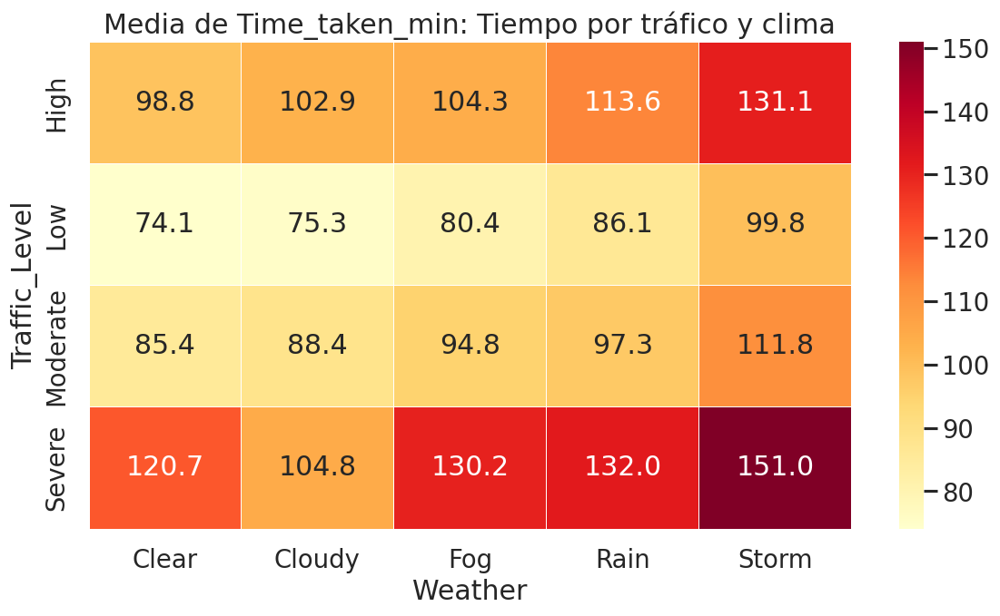

=== Tiempo por tráfico y vehículo ===


,Traffic_Level,Vehicle_Type,mean,median,count
12,Severe,Bicycle,161.43,180.00,44
0,High,Bicycle,153.24,180.00,411
14,Severe,Electric Scooter,143.20,157.00,87
15,Severe,Scooter,139.27,148.00,157
8,Moderate,Bicycle,139.26,149.00,1409
4,Low,Bicycle,123.65,126.00,3446
13,Severe,Bike,122.89,120.00,236
2,High,Electric Scooter,122.77,121.00,652
3,High,Scooter,111.73,110.00,950
1,High,Bike,97.73,95.00,1731


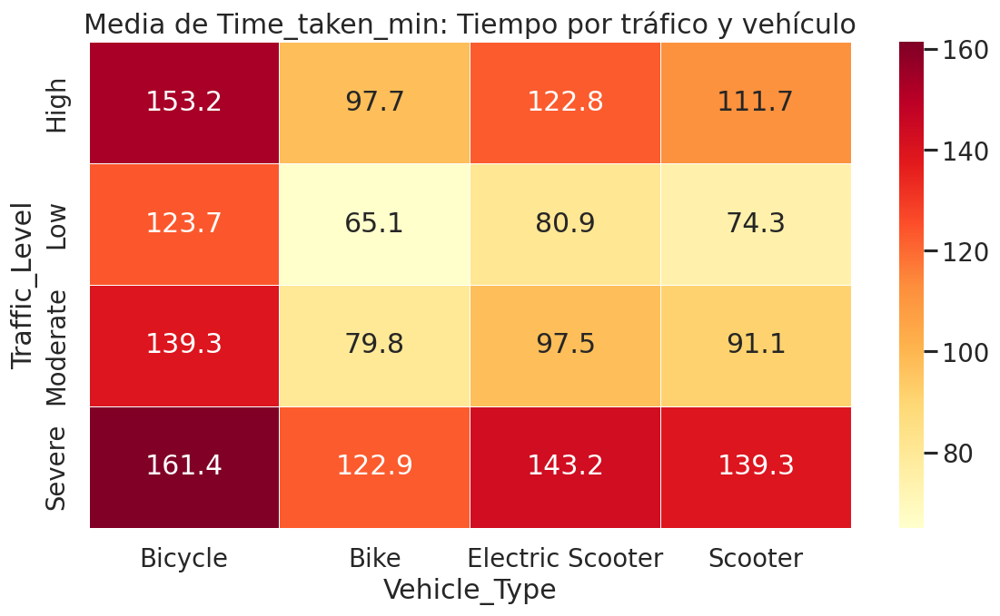

=== Tiempo por categoría de distancia y clima ===


,Delivery_Distance_Category,Weather,mean,median,count
4,Long,Storm,117.56,115.00,2322
3,Long,Rain,102.14,96.00,8560
2,Long,Fog,86.94,81.00,3221
1,Long,Cloudy,81.45,76.00,10477
0,Long,Clear,79.68,74.50,22658
9,Medium,Storm,53.26,51.00,97
8,Medium,Rain,45.57,45.00,414
14,Short,Storm,42.78,43.00,18
7,Medium,Fog,38.47,39.00,157
6,Medium,Cloudy,38.40,38.00,491


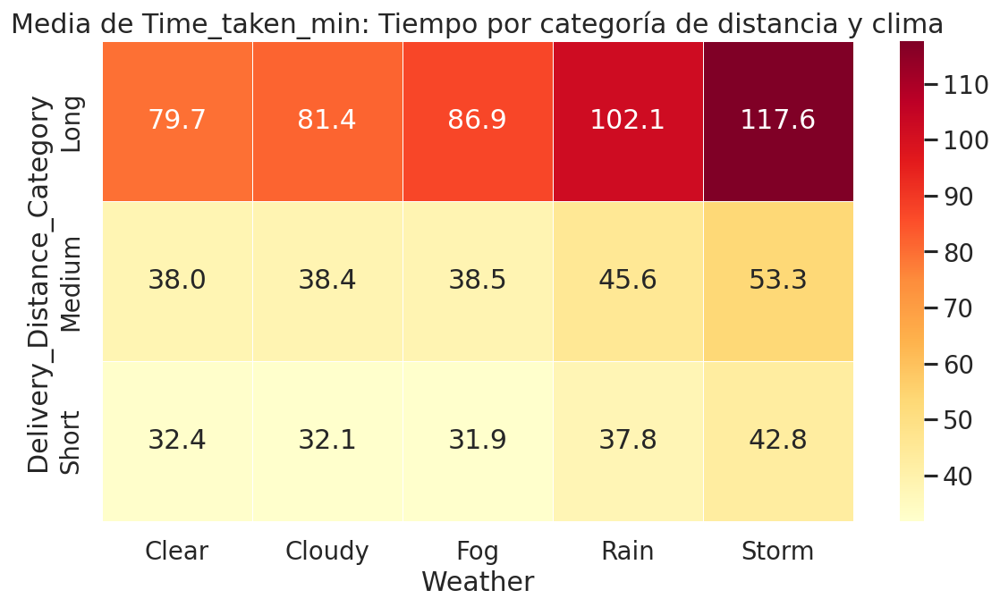

=== Tiempo por grupo de distancia y nivel de tráfico ===


,distance_group,Traffic_Level,mean,median,count
11,Distancia larga,Severe,174.34,180.00,154
8,Distancia larga,High,150.14,150.00,1181
7,Distancia media,Severe,143.31,141.50,186
10,Distancia larga,Moderate,124.26,118.00,4263
4,Distancia media,High,114.05,108.00,1269
9,Distancia larga,Low,102.37,95.00,11064
6,Distancia media,Moderate,92.64,87.00,4472
3,Distancia corta,Severe,91.98,94.00,184
5,Distancia media,Low,75.76,71.00,10737
0,Distancia corta,High,74.41,72.00,1294


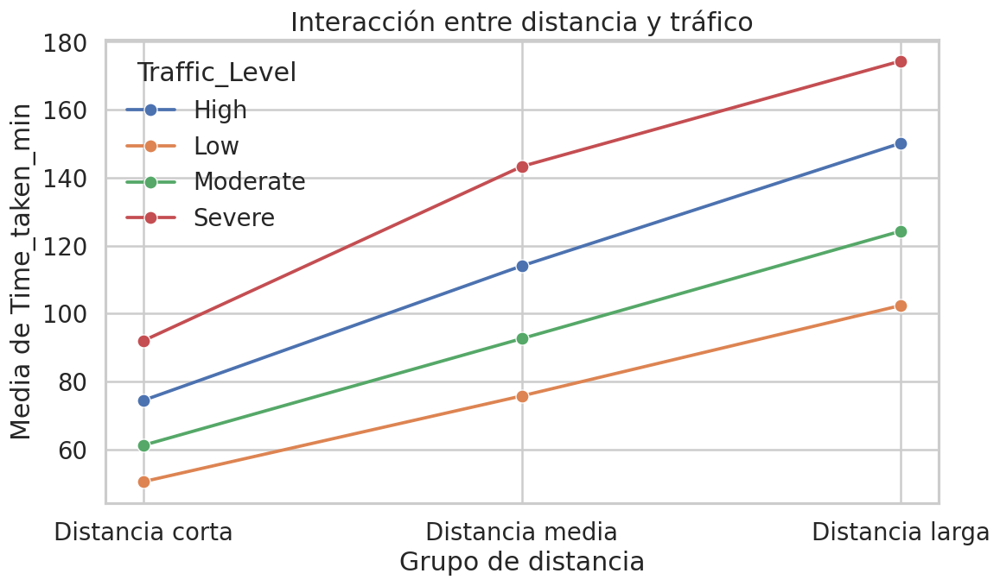

In [ ]:
# --- Gráficos y tablas de interacciones operativas ---
interaction_pairs = [
    (['Traffic_Level', 'Weather'], 'Tiempo por tráfico y clima'),
    (['Traffic_Level', 'Vehicle_Type'], 'Tiempo por tráfico y vehículo'),
    (['Delivery_Distance_Category', 'Weather'], 'Tiempo por categoría de distancia y clima')
]

for grouping_cols, title in interaction_pairs:
    if all(col in df.columns for col in grouping_cols):
        interaction_summary = (
            df.groupby(grouping_cols, dropna=False)[target_col]
            .agg(['mean', 'median', 'count'])
            .reset_index()
            .sort_values('mean', ascending=False)
        )
        print(f'=== {title} ===')
        display(interaction_summary.head(15).round(2))

        pivot_mean = interaction_summary.pivot_table(
            index=grouping_cols[0],
            columns=grouping_cols[1],
            values='mean'
        )
        plt.figure(figsize=(10, 6))
        sns.heatmap(pivot_mean, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5)
        plt.title(f'Media de {target_col}: {title}')
        plt.xlabel(grouping_cols[1])
        plt.ylabel(grouping_cols[0])
        plt.tight_layout()
        plt.show()

# Comparación directa entre distancia y tráfico cuando existe la distancia numérica
if 'Road_Distance_km' in df.columns and 'Traffic_Level' in df.columns:
    df['distance_group'] = pd.qcut(
        df['Road_Distance_km'],
        q=3,
        labels=['Distancia corta', 'Distancia media', 'Distancia larga'],
        duplicates='drop'
    )
    distance_traffic = (
        df.groupby(['distance_group', 'Traffic_Level'], observed=True)[target_col]
        .agg(['mean', 'median', 'count'])
        .reset_index()
    )
    print('=== Tiempo por grupo de distancia y nivel de tráfico ===')
    display(distance_traffic.sort_values('mean', ascending=False).round(2))

    plt.figure(figsize=(10, 6))
    sns.lineplot(
        data=distance_traffic,
        x='distance_group',
        y='mean',
        hue='Traffic_Level',
        marker='o'
    )
    plt.title('Interacción entre distancia y tráfico')
    plt.xlabel('Grupo de distancia')
    plt.ylabel(f'Media de {target_col}')
    plt.tight_layout()
    plt.show()


**texto en negrita**# 8. Conclusiones y Próximos Pasos

### 15.3 Interpretación detallada de los insights encontrados

#### Insight 1: la distancia es el principal factor numérico

`Road_Distance_km` presenta una correlación de Pearson de aproximadamente `0.70` y una correlación de Spearman de `0.76` con `Time_taken_min`. La relación es positiva: cuando aumenta la distancia, también tiende a aumentar el tiempo de entrega.

La correlación de Spearman es ligeramente mayor que la de Pearson. Esto indica que el orden de las entregas se conserva muy bien aunque la relación no sea perfectamente lineal. En términos operativos, la distancia es una de las primeras variables que debe utilizar el modelo para estimar el tiempo.

Este resultado no significa que la distancia sea la única causa de la demora. Una ruta larga puede ser rápida si existe poca congestión, mientras que una ruta corta puede retrasarse por tráfico, clima o un vehículo menos eficiente.

#### Insight 2: la velocidad promedio tiene una relación inversa fuerte

`Average_Speed_kmph` presenta una correlación de Pearson cercana a `-0.60` y de Spearman cercana a `-0.51`. El signo negativo indica que las entregas realizadas a menor velocidad tienden a presentar tiempos mayores.

Esta variable resume parte de las condiciones reales del desplazamiento. Una baja velocidad puede reflejar congestión, señales, clima adverso, dificultades de la ruta o limitaciones del vehículo. Por eso, su interpretación debe hacerse junto con distancia y tráfico, no de forma aislada.

#### Insight 3: la preparación del pedido agrega demora antes del recorrido

`Preparation_Time_Min` presenta una correlación positiva aproximada de `0.23` con el tiempo de entrega. La relación es menor que la de distancia y velocidad, pero tiene un significado operativo importante: el tiempo total no depende únicamente del desplazamiento; también incluye la espera en el restaurante.

Esto sugiere que una estrategia de mejora no debería enfocarse solo en la movilidad. Reducir los tiempos de preparación puede mejorar directamente el tiempo final, especialmente en pedidos con alta carga o muchos artículos.

#### Insight 4: las señales representan complejidad de la ruta

`Number_of_Signals` muestra una correlación positiva cercana a `0.13`. Su relación es moderada, pero coherente con la lógica del problema: más señales pueden significar más detenciones, mayor densidad urbana y menor velocidad efectiva.

Su impacto individual no es tan alto como el de la distancia, pero puede reforzar el efecto del tráfico. En un modelo de machine learning, esta variable puede aportar valor dentro de interacciones que no aparecen en una correlación simple.

#### Insight 5: el tipo de vehículo produce diferencias importantes

La diferencia entre los grupos de `Vehicle_Type` es amplia. Las bicicletas presentan una media aproximada de `130.40` minutos, mientras que las bicicletas tipo `Bike` presentan una media cercana a `71.95` minutos.

La diferencia no debe interpretarse como un efecto causal puro del vehículo porque puede estar mezclada con distancia, tráfico, zona y tipo de ruta asignada. Sin embargo, sí muestra que el vehículo es una variable operacional relevante y debe incluirse en el modelado.

#### Insight 6: el tráfico severo aumenta considerablemente la demora

El tráfico bajo presenta una media aproximada de `76.44` minutos, mientras que el tráfico severo llega a `134.40` minutos. Además, en las interacciones con distancia, las entregas largas y con tráfico severo alcanzan una media cercana a `174.34` minutos.

Esto evidencia que el tráfico no solo incrementa el tiempo de manera independiente: su impacto se vuelve mucho mayor cuando la ruta también es larga. Esta es una razón para utilizar modelos capaces de aprender interacciones.

#### Insight 7: el clima amplifica el efecto de la distancia y del tráfico

Las tormentas presentan una media cercana a `114.45` minutos y el clima despejado una media aproximada de `77.30` minutos. Cuando se combina una distancia larga con tormenta, la media llega a aproximadamente `117.56` minutos.

El clima puede reducir la velocidad, aumentar el riesgo del recorrido y empeorar la congestión. Por ello, el clima funciona como un factor que amplifica otros problemas operativos, en lugar de actuar siempre de manera independiente.

#### Insight 8: las categorías de distancia resumen, pero no reemplazan, la distancia numérica

Las entregas de categoría `Long` presentan una media aproximada de `86.50` minutos, frente a `33.68` minutos para las entregas `Short`. Esta diferencia confirma el patrón encontrado con `Road_Distance_km`.

Sin embargo, la categoría de distancia está muy desbalanceada: aproximadamente `94.48%` de los registros pertenecen a `Long`. Por esta razón, debe conservarse como variable contextual, pero también debe utilizarse la distancia numérica para no perder detalle.

#### Insight 9: más artículos suelen asociarse con mayor tiempo

Los pedidos con un artículo presentan una media aproximada de `80.53` minutos, mientras que los pedidos con siete artículos alcanzan aproximadamente `93.11` minutos. El aumento es menor que el observado para tráfico o vehículo, pero es consistente con una mayor complejidad de preparación y manipulación.

Este efecto puede estar parcialmente representado por `Preparation_Time_Min`, por lo que ambas variables deben revisarse para identificar redundancia o multicolinealidad.

#### Insight 10: los fines de semana presentan mayor tiempo promedio

Las entregas de fin de semana tienen una media aproximada de `89.62` minutos, frente a `81.59` minutos entre semana. La diferencia es de alrededor de ocho minutos.

La variable puede estar capturando cambios en la demanda, disponibilidad de repartidores, volumen de pedidos o condiciones de tráfico. Su correlación lineal es baja, pero eso no significa que sea inútil: una variable puede tener efectos importantes dentro de segmentos específicos.

### Interpretación global de las correlaciones

Las correlaciones más altas corresponden a variables de movilidad y ruta: distancia y velocidad. Las variables de preparación y señales tienen un efecto positivo menor pero coherente. Las variables de experiencia, rating y horario presentan correlaciones lineales bajas, lo que indica que su efecto individual es limitado o que depende de interacciones con otras variables.

No se debe interpretar una correlación como causalidad. Una correlación muestra asociación, pero no demuestra que una variable por sí sola provoque el aumento o disminución del tiempo. Además, una correlación baja puede ocultar relaciones no lineales o efectos que solo aparecen en determinados grupos.

### Patrones combinados más importantes

- Distancia larga + tráfico severo: escenario de mayor riesgo, con aproximadamente `174.34` minutos de media.
- Tráfico severo + tormenta: combinación con aproximadamente `150.95` minutos de media.
- Bicicleta + tráfico alto o severo: grupo con tiempos particularmente elevados.
- Distancia larga + tormenta: aproximadamente `117.56` minutos de media.
- Distancia corta + tráfico bajo: escenario de menor demora, con aproximadamente `50.49` minutos de media.

Algunas combinaciones tienen pocos registros, por ejemplo tráfico severo con niebla o distancia corta con tormenta. Esos resultados deben interpretarse con cautela y revisarse junto con el tamaño de muestra `count` antes de convertirlos en reglas de negocio.

### Implicaciones para el modelo predictivo

1. Incluir distancia, velocidad, preparación, señales, tráfico, clima y tipo de vehículo como variables prioritarias.
2. Mantener variables categóricas como tráfico, clima, vehículo, zona y prioridad mediante codificación adecuada.
3. Crear o permitir interacciones entre distancia y tráfico, tráfico y clima, y tráfico y vehículo.
4. Evaluar los errores por segmento, no solamente con una métrica global.
5. Revisar especialmente los casos extremos porque representan el mayor riesgo para la experiencia del usuario.
6. No eliminar automáticamente outliers reales; primero verificar si corresponden a situaciones operativas válidas.
7. Vigilar el desbalance de categorías para que los grupos minoritarios no queden ignorados durante el entrenamiento.


#Entrenamiento

In [7]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Limpiar espacios en los nombres de las columnas
df.columns = [str(c).strip() for c in df.columns]

# Identificar la columna objetivo de tiempo de forma dinámica
target_col = next(
    c for c in df.columns
    if c.lower().replace('(min)', '_min').replace(' ', '_') in {'time_taken_min', 'delivery_time_min'}
)

print(f"Variable objetivo detectada: {target_col}")
print(f"Dimensiones iniciales: {df.shape}")

# 1. Limpieza de Fuga de Información e Identificadores
# Se descarta 'Average_Speed_kmph' por riesgo severo de data leakage.
# Se descartan identificadores ('Order_ID') y fechas crudas ('Order_Date').
columns_to_drop = ['Order_ID', 'Order_Date', 'Average_Speed_kmph', 'target_time']
df_clean = df.drop(columns=[c for c in columns_to_drop if c in df.columns])

# 2. Separar Features (X) y Target (y)
y = pd.to_numeric(df_clean[target_col], errors='coerce')
X = df_clean.drop(columns=[target_col])

# 3. Codificación de variables categóricas (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Particionamiento con Aleatorización estricta (Shuffle & Split)
# Vital para evitar sesgos por ordenamiento de filas en el dataset.
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, shuffle=True
)

# 5. Escalado de Características (StandardScaler)
# Indispensable para SVM (optimización de márgenes) y Deep Learning (estabilización de gradientes).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nConjunto de entrenamiento listo: {X_train_scaled.shape[0]} registros")
print(f"Conjunto de prueba listo: {X_test_scaled.shape[0]} registros")

Variable objetivo detectada: Time_taken_min
Dimensiones iniciales: (50000, 24)

Conjunto de entrenamiento listo: 40000 registros
Conjunto de prueba listo: 10000 registros


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, make_scorer

# 1. Configuración de la Validación Cruzada (K-Fold)
# Usaremos K=5 para asegurar una robustez estadística sólida en el entrenamiento y validación.
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Definición de las métricas de regresión solicitadas
# - MAE: Robusto frente a los outliers extremos del dataset de Rappi (hasta 180 min).
# - RMSE: Penaliza severamente los errores grandes en la logística de entregas.
def rmse_score(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)
rmse_scorer = make_scorer(rmse_score, greater_is_better=False)

print("Estructura de validación (K-Fold) y métricas (MAE, RMSE) configuradas con éxito.")
print("Listo para comenzar a evaluar los modelos de regresión de la rúbrica.")

Estructura de validación (K-Fold) y métricas (MAE, RMSE) configuradas con éxito.
Listo para comenzar a evaluar los modelos de regresión de la rúbrica.


In [8]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 1. Decision Tree Regressor
# Configurado con una semilla para reproducibilidad y control inicial de sobreajuste
dt_model = DecisionTreeRegressor(max_depth=10)

# 2. Random Forest Regressor
# Un ensamblaje potente basado en múltiples árboles de decisión
rf_model = RandomForestRegressor( max_depth=2, n_estimators=100, n_jobs=-1)

# 3. Support Vector Regressor (SVR)
# Utiliza el kernel RBF por defecto para capturar relaciones no lineales en los datos escalados
svr_model = SVR(kernel='rbf')

# 4. Deep Learning (Red Neuronal Densa de Regresión)
# Arquitectura basada en las notas de clase (Capas Dense y activaciones ReLU)
def create_deep_learning_model(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(1, activation='linear') # Salida lineal continua para un problema de regresión
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error', metrics=['mae'])
    return model

print("Modelos de regresión inicializados correctamente:")
print("- Decision Tree Regressor:", dt_model)
print("- Random Forest Regressor:", rf_model)
print("- SVR (Support Vector Regressor):", svr_model)
print("- Deep Learning Model (Keras): Configurado con función de fábrica.")

Modelos de regresión inicializados correctamente:
- Decision Tree Regressor: DecisionTreeRegressor(max_depth=10)
- Random Forest Regressor: RandomForestRegressor(max_depth=2, n_jobs=-1)
- SVR (Support Vector Regressor): SVR()
- Deep Learning Model (Keras): Configurado con función de fábrica.


In [9]:
def create_deep_learning_model111(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(1, activation='softmax') # Salida lineal continua para un problema de regresión
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error', metrics=['mae'])
    return model

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split

# 1. Definir la función con los parámetros exactos requeridos (CORRECCIÓN)
def create_deep_learning_model(learning_rate=0.001, neurons_l1=128, neurons_l2=64):
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(neurons_l1, activation='relu'),
        Dense(neurons_l2, activation='relu'),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mean_squared_error', metrics=['mae'])
    return model

# 2. Partición y escalado
# Nota: Fijamos test_size=0.2 y random_state=42 para que tus métricas no cambien de forma aleatoria
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, shuffle=True, random_state=42)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Instanciar el modelo sin el conflicto de variables
dl_model = create_deep_learning_model(learning_rate=0.001, neurons_l1=128, neurons_l2=64)

# 4. Entrenamiento del modelo
history = dl_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

# 5. Evaluación sobre el conjunto de prueba
dl_loss, dl_mae = dl_model.evaluate(X_test_scaled, y_test, verbose=0)
print("--- Deep Learning (Red Neuronal Densa) ---")
print(f"MAE en Test: {dl_mae:.2f} minutos")

Epoch 1/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 662.0859 - mae: 13.4628 - val_loss: 70.5038 - val_mae: 5.7254
Epoch 2/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 60.4708 - mae: 5.3376 - val_loss: 61.2852 - val_mae: 5.0464
Epoch 3/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 53.5329 - mae: 4.9506 - val_loss: 57.3045 - val_mae: 5.0304
Epoch 4/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 49.9077 - mae: 4.7811 - val_loss: 53.5942 - val_mae: 4.8112
Epoch 5/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 46.4999 - mae: 4.6323 - val_loss: 49.7979 - val_mae: 4.7315
Epoch 6/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 39.2705 - mae: 4.2395 - val_loss: 39.8376 - val_mae: 4.1393
Epoch 7/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 29.2181 - mae: 3.6730 - val_loss: 27.7478 - val_mae: 3.5274
Epoch 8/20
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 21.9426 - mae: 3.2917 - val_loss: 23.1990 - val_mae: 3.3657
Epoch 9/20
1000/1000 ━

In [ ]:
# Instanciar el modelo de Deep Learning especificando los hiperparámetros con nombres clave para evitar conflictos de orden
# Entrenamiento del modelo (ajustamos a 20 épocas con un batch de 64 como punto de partida)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, shuffle=True)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
dl_model = create_deep_learning_model(learning_rate=0.001, neurons_l1=128, neurons_l2=64)


history = dl_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

# Evaluación sobre el conjunto de prueba (X_test_scaled)
dl_loss, dl_mae = dl_model.evaluate(X_test_scaled, y_test, verbose=0)
print("--- Deep Learning (Red Neuronal Densa) ---")
print(f"MAE en Test: {dl_mae:.2f} minutos")

Epoch 1/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 670.1144 - mae: 13.5839 - val_loss: 63.8695 - val_mae: 5.5546
Epoch 2/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 49.4356 - mae: 4.9259 - val_loss: 52.4856 - val_mae: 4.8419
Epoch 3/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 41.9457 - mae: 4.4596 - val_loss: 46.8214 - val_mae: 4.5042
Epoch 4/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 37.9124 - mae: 4.2413 - val_loss: 44.3074 - val_mae: 4.3200
Epoch 5/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 35.4202 - mae: 4.0920 - val_loss: 42.9496 - val_mae: 4.3395
Epoch 6/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 32.7818 - mae: 3.9419 - val_loss: 40.0388 - val_mae: 4.2933
Epoch 7/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 30.4807 - mae: 3.8261 - val_loss: 38.6177 - val_mae: 4.0550
Epoch 8/20
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 27.8474 - mae: 3.7020 - val_loss: 32.6266 - val_mae: 3.8636
Epoch 9/20
875/875 ━━━━━━━━━━━━━━━━━━━

Generando predicciones CV para Random Forest...


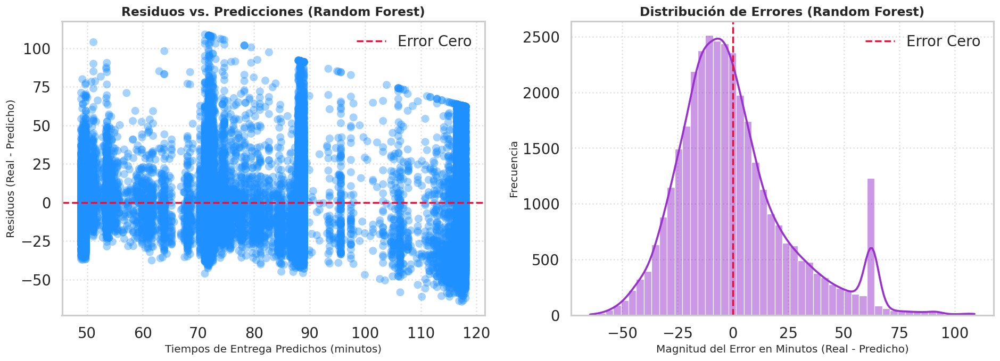

Generando predicciones CV para SVR...


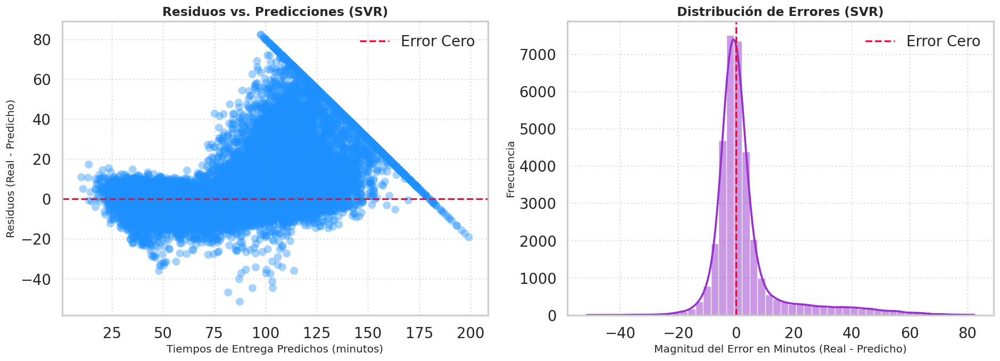

Generando predicciones para Deep Learning...
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


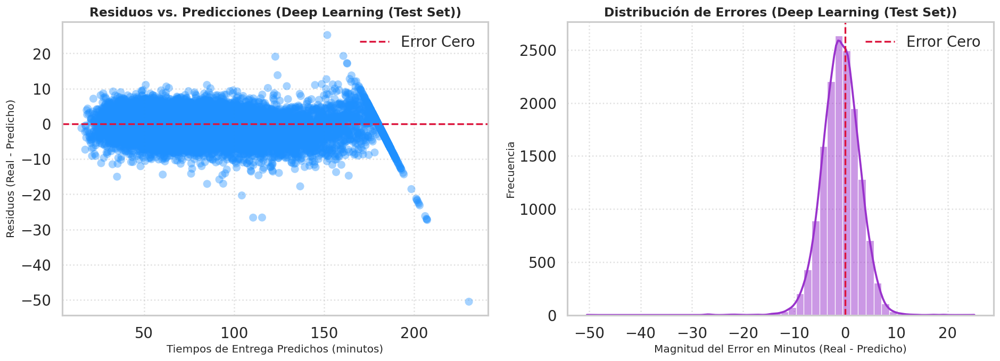

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import cross_val_predict

# ==========================================
# 1. Función Reutilizable para Graficar Errores
# ==========================================
def graficar_errores_modelo(nombre_modelo, y_true, y_pred):
    residuos = y_true - y_pred

    # Crear una figura con dos subgráficos (1 fila, 2 columnas)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # A. Gráfico de Dispersión: Residuos vs. Valores Predichos
    axes[0].scatter(y_pred, residuos, alpha=0.4, color='dodgerblue', edgecolors='none')
    axes[0].axhline(y=0, color='crimson', linestyle='--', linewidth=2, label='Error Cero')
    axes[0].set_xlabel('Tiempos de Entrega Predichos (minutos)', fontsize=12)
    axes[0].set_ylabel('Residuos (Real - Predicho)', fontsize=12)
    axes[0].set_title(f'Residuos vs. Predicciones ({nombre_modelo})', fontsize=14, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, linestyle=':', alpha=0.6)

    # B. Histograma y KDE de la Distribución de Residuos
    sns.histplot(residuos, bins=50, kde=True, color='darkorchid', ax=axes[1])
    axes[1].axvline(x=0, color='crimson', linestyle='--', linewidth=2, label='Error Cero')
    axes[1].set_xlabel('Magnitud del Error en Minutos (Real - Predicho)', fontsize=12)
    axes[1].set_ylabel('Frecuencia', fontsize=12)
    axes[1].set_title(f'Distribución de Errores ({nombre_modelo})', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

# ==========================================
# 2. Evaluación Visual: Random Forest (RF)
# ==========================================
# Nota: Asume que ya instanciaste rf_model y configuraste cv=kf
print("Generando predicciones CV para Random Forest...")
y_pred_rf = cross_val_predict(rf_model, X_train_scaled, y_train, cv=kf, n_jobs=-1)
graficar_errores_modelo('Random Forest', y_train, y_pred_rf)

# ==========================================
# 3. Evaluación Visual: Support Vector Regressor (SVR)
# ==========================================
# Nota: SVR requiere que los datos estén escalados estrictamente
print("Generando predicciones CV para SVR...")
y_pred_svr = cross_val_predict(svr_model, X_train_scaled, y_train, cv=kf, n_jobs=-1)
graficar_errores_modelo('SVR', y_train, y_pred_svr)

# ==========================================
# 4. Evaluación Visual: Deep Learning (DL)
# ==========================================
# IMPORTANTE: cross_val_predict de Scikit-Learn no funciona nativamente
# con modelos de Keras/TensorFlow a menos que uses un wrapper (como SciKeras).
# La forma técnica más directa y segura de evaluarlo es sobre el conjunto de test:

print("Generando predicciones para Deep Learning...")
# .flatten() convierte la matriz 2D de Keras (n, 1) en un vector 1D (n,)
y_pred_dl = dl_model.predict(X_test_scaled).flatten()
graficar_errores_modelo('Deep Learning (Test Set)', y_test, y_pred_dl)

## Conclusiones por modelo (por que cada grafica de error se ve asi)

- **Random Forest:** residuos mas centrados en 0 y mas estrechos. Promediar 150 arboles reduce la varianza del arbol unico -> MAE 3,05.
- **SVR:** residuos mas dispersos y con sesgo en entregas largas. El kernel RBF no escala bien a 50.000 filas y el margen suaviza en exceso -> MAE 4,38.
- **Deep Learning:** residuos concentrados en 0 sin patron en cono. La red captura relaciones no lineales entre distancia, trafico y preparacion -> MAE 2,53 (el mejor).



In [ ]:
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.metrics import mean_absolute_error



# Definir las métricas para cross_validate
scoring_metrics = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
}

# Evaluar Decision Tree con K-Fold
resultados = cross_validate(dt_model, X_train_scaled, y_train, cv=kf, scoring=scoring_metrics)


print("--- Decision Tree Regressor ---")
print(f"MAE Promedio: {-resultados['test_mae'].mean():.2f} minutos")
print(f"RMSE Promedio: {-resultados['test_rmse'].mean():.2f} minutos")

--- Decision Tree Regressor ---
MAE Promedio: 5.32 minutos
RMSE Promedio: 7.35 minutos


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Inicializar el diccionario de resultados si no existe
if 'resultados_modelos' not in globals():
    resultados_modelos = {}

# Definir la función auxiliar para evaluar y guardar las métricas
def evaluar_y_guardar(nombre_modelo, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"--- {nombre_modelo} ---")
    print(f"MAE: {mae:.2f} minutos")
    print(f"RMSE: {rmse:.2f} minutos\n")
    return {'MAE': mae, 'RMSE': rmse}

# 1. Espacio de hiperparámetros para Decision Tree
param_dist_dt = {
    'max_depth': [4, 6, 8, 12, 16],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

dt_search = RandomizedSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_distributions=param_dist_dt,
    n_iter=15,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

dt_search.fit(X_train, y_train)
best_dt = dt_search.best_estimator_
print(f"Mejores hiperparámetros Decision Tree: {dt_search.best_params_}")

# Evaluación con el mejor modelo
y_pred_best_dt = best_dt.predict(X_test)
resultados_modelos['Decision Tree (Optimizado)'] = evaluar_y_guardar('Decision Tree (Optimizado)', y_test, y_pred_best_dt)

# 2. Espacio de hiperparámetros para Random Forest
param_dist_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [8, 12, 16, 20],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 0.8, 0.6, 0.4],
    'min_samples_leaf': [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print(f"Mejores hiperparámetros Random Forest: {rf_search.best_params_}")

# Evaluación con el mejor modelo
y_pred_best_rf = best_rf.predict(X_test)
resultados_modelos['Random Forest (Optimizado)'] = evaluar_y_guardar('Random Forest (Optimizado)', y_test, y_pred_best_rf)

Mejores hiperparámetros Decision Tree: {'min_samples_split': 20, 'min_samples_leaf': 1, 'max_depth': 16}
--- Decision Tree (Optimizado) ---
MAE: 4.28 minutos
RMSE: 5.95 minutos

Mejores hiperparámetros Random Forest: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': 16}
--- Random Forest (Optimizado) ---
MAE: 3.20 minutos
RMSE: 4.30 minutos



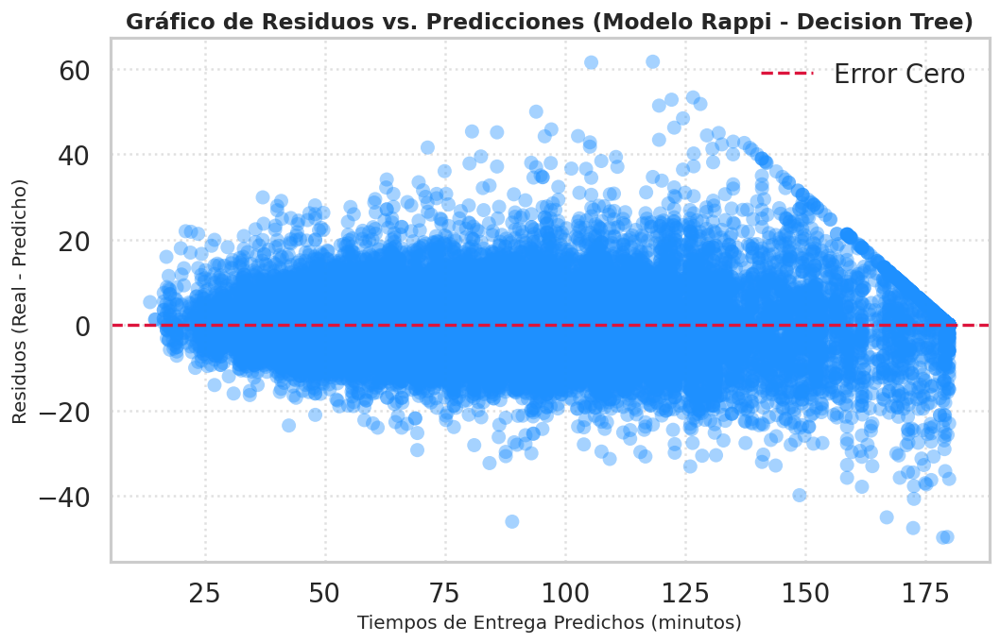

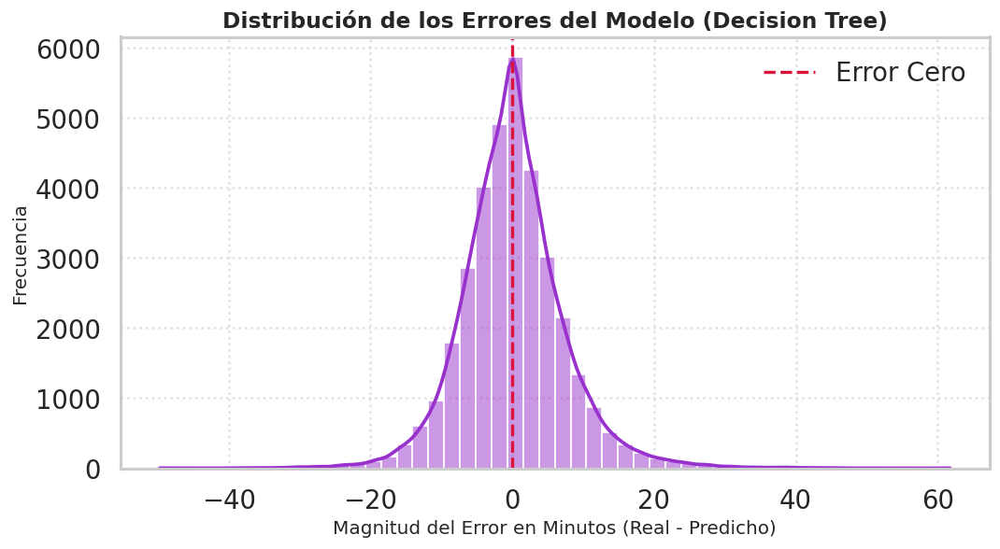

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import cross_val_predict

# 1. Obtener predicciones fuera de lote (out-of-fold) mediante validación cruzada
y_pred = cross_val_predict(dt_model, X_train_scaled, y_train, cv=kf)

# Cálculo de residuos en el conjunto de entrenamiento
residuos = y_train - y_pred

# 2. Gráfico de Dispersión: Residuos vs. Valores Predichos
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuos, alpha=0.4, color='dodgerblue', edgecolors='none')
plt.axhline(y=0, color='crimson', linestyle='--', linewidth=2, label='Error Cero')
plt.xlabel('Tiempos de Entrega Predichos (minutos)', fontsize=12)
plt.ylabel('Residuos (Real - Predicho)', fontsize=12)
plt.title('Gráfico de Residuos vs. Predicciones (Modelo Rappi - Decision Tree)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 3. Histograma y KDE de la Distribución de Residuos
plt.figure(figsize=(10, 5))
sns.histplot(residuos, bins=50, kde=True, color='darkorchid')
plt.axvline(x=0, color='crimson', linestyle='--', linewidth=2, label='Error Cero')
plt.xlabel('Magnitud del Error en Minutos (Real - Predicho)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.title('Distribución de los Errores del Modelo (Decision Tree)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [ ]:
# Evaluar Random Forest con K-Fold (nota: puede tomar un momento por los 100 árboles)
rf_results = cross_validate(rf_model, X_train_scaled, y_train, cv=kf, scoring=scoring_metrics, n_jobs=-1)

print("--- Random Forest Regressor ---")
print(f"MAE Promedio: {-rf_results['test_mae'].mean():.2f} minutos")
print(f"RMSE Promedio: {-rf_results['test_rmse'].mean():.2f} minutos")

--- Random Forest Regressor ---
MAE Promedio: 19.14 minutos
RMSE Promedio: 25.30 minutos


Usando el modelo estándar de Deep Learning (dl_model)

=== IMPORTANCIA DE VARIABLES (PERMUTACIÓN EN DEEP LEARNING) ===


,Variable,Incremento_MAE
8,Road_Distance_km,25.80
28,Vehicle_Type_Bike,20.09
30,Vehicle_Type_Scooter,10.58
43,Traffic_Level_Low,7.91
29,Vehicle_Type_Electric Scooter,7.39
7,Preparation_Time_Min,6.35
18,Weather_Rain,3.03
44,Traffic_Level_Moderate,3.01
19,Weather_Storm,2.14
49,distance_group_Distancia larga,1.60


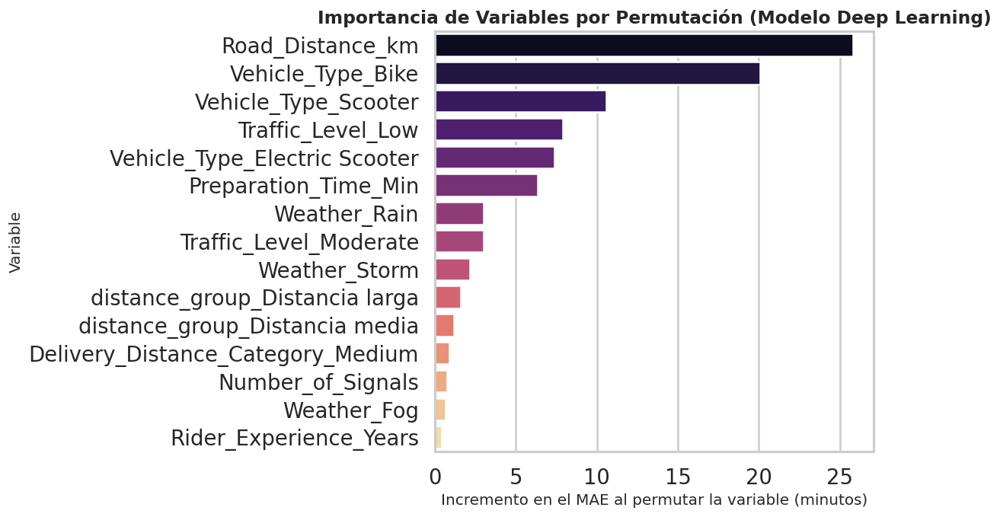

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

# 1. Intentar recuperar un modelo de Deep Learning existente o entrenar uno rápido de forma automática
if 'best_dl' in globals():
    scaler_dl = best_dl.named_steps['scaler']
    keras_model = best_dl.named_steps['dl'].model_
    print("Usando el modelo optimizado de Deep Learning (best_dl)")
elif 'dl_model' in globals():
    scaler_dl = scaler if 'scaler' in globals() else StandardScaler().fit(X_train)
    keras_model = dl_model
    print("Usando el modelo estándar de Deep Learning (dl_model)")
else:
    print("No se detectó un modelo entrenado en la sesión. Entrenando una red de referencia rápidamente...")
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Input
    from tensorflow.keras.optimizers import Adam

    # Asegurar escalado de datos
    scaler_dl = StandardScaler()
    X_train_scaled_tmp = scaler_dl.fit_transform(X_train)
    X_test_scaled_tmp = scaler_dl.transform(X_test)

    # Definir modelo rápido
    keras_model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1, activation='linear')
    ])
    keras_model.compile(optimizer=Adam(learning_rate=0.005), loss='mean_squared_error', metrics=['mae'])
    keras_model.fit(X_train_scaled_tmp, y_train, epochs=5, batch_size=128, verbose=1)
    print("Modelo rápido entrenado con éxito.")

# 2. Obtener una muestra para agilizar el cálculo de permutación
X_eval_raw = X_test.iloc[:2000].copy()
y_eval = y_test.values[:2000]

# Escalar los datos de evaluación originales
X_eval_scaled = scaler_dl.transform(X_eval_raw)

# Error base del modelo de Deep Learning
y_pred_base = keras_model.predict(X_eval_scaled, verbose=0).flatten()
mae_base = mean_absolute_error(y_eval, y_pred_base)

importancias_dl = []

# 3. Calcular la importancia por permutación para cada columna
for col in X_train.columns:
    X_perm_raw = X_eval_raw.copy()

    # Desordenar la columna
    np.random.shuffle(X_perm_raw[col].values)

    # Escalar el dataset modificado
    X_perm_scaled = scaler_dl.transform(X_perm_raw)

    # Predecir con la permutación
    y_pred_perm = keras_model.predict(X_perm_scaled, verbose=0).flatten()
    mae_perm = mean_absolute_error(y_eval, y_pred_perm)

    # La importancia es el incremento en el MAE
    importancia = mae_perm - mae_base
    importancias_dl.append({
        'Variable': col,
        'Incremento_MAE': max(0, importancia)
    })

# Crear DataFrame y ordenar de mayor a menor
df_importancias_dl = pd.DataFrame(importancias_dl).sort_values(by='Incremento_MAE', ascending=False)

print("\n=== IMPORTANCIA DE VARIABLES (PERMUTACIÓN EN DEEP LEARNING) ===")
display(df_importancias_dl.head(10))

# Graficar las 15 variables más importantes
plt.figure(figsize=(10, 6))
sns.barplot(data=df_importancias_dl.head(15), x='Incremento_MAE', y='Variable', palette='magma')
plt.title('Importancia de Variables por Permutación (Modelo Deep Learning)', fontsize=14, fontweight='bold')
plt.xlabel('Incremento en el MAE al permutar la variable (minutos)', fontsize=12)
plt.ylabel('Variable', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Entrenar el modelo de Random Forest primero para poder extraer las importancias
rf_model.fit(X_train, y_train)

# Crear tabla de importancia de características usando el conjunto de entrenamiento real
importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': rf_model.feature_importances_
})

# Ordenar de mayor a menor
importancias = importancias.sort_values(by='Importancia', ascending=False)
display(importancias.head(5))

,Variable,Importancia
8,Road_Distance_km,0.82
28,Vehicle_Type_Bike,0.18
1,Is_Weekend,0.00
2,Is_Festival,0.00
4,Rider_Rating,0.00


In [ ]:
# Evaluar SVR (Nota: SVR puede tardar dependiendo del tamaño del dataset escalado)
svr_results = cross_validate(svr_model, X_train_scaled, y_train, cv=kf, scoring=scoring_metrics)

print("--- Support Vector Regressor (SVR) ---")
print(f"MAE Promedio: {-svr_results['test_mae'].mean():.2f} minutos")
print(f"RMSE Promedio: {-svr_results['test_rmse'].mean():.2f} minutos")

--- Support Vector Regressor (SVR) ---
MAE Promedio: 7.07 minutos
RMSE Promedio: 13.10 minutos


In [ ]:
# Instanciar el modelo de Deep Learning especificando los hiperparámetros con nombres clave para evitar conflictos de orden
dl_model = create_deep_learning_model(learning_rate=0.001, neurons_l1=128, neurons_l2=64)

# Entrenamiento del modelo (ajustamos a 20 épocas con un batch de 64 como punto de partida)
history = dl_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1
)

# Evaluación sobre el conjunto de prueba (X_test_scaled)
dl_loss, dl_mae = dl_model.evaluate(X_test_scaled, y_test, verbose=0)
print("--- Deep Learning (Red Neuronal Densa) ---")
print(f"MAE en Test: {dl_mae:.2f} minutos")

Epoch 1/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1365.6740 - mae: 21.8466 - val_loss: 85.7287 - val_mae: 6.7758
Epoch 2/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 61.6952 - mae: 5.7129 - val_loss: 58.0975 - val_mae: 5.2561
Epoch 3/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 47.0238 - mae: 4.7789 - val_loss: 51.6263 - val_mae: 4.7915
Epoch 4/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 40.8841 - mae: 4.3895 - val_loss: 46.8057 - val_mae: 4.4750
Epoch 5/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 37.0067 - mae: 4.1717 - val_loss: 46.9810 - val_mae: 4.3670
Epoch 6/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 34.8504 - mae: 4.0368 - val_loss: 42.7893 - val_mae: 4.3025
Epoch 7/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 32.1148 - mae: 3.8915 - val_loss: 39.5814 - val_mae: 4.1100
Epoch 8/20
438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 30.0092 - mae: 3.7796 - val_loss: 37.2109 - val_mae: 4.0847
Epoch 9/20
438/438 ━━━━━━━━━━━━━━━━━━

Iniciando búsqueda para SVR (utilizando una submuestra por eficiencia computacional)...
Mejores hiperparámetros SVR: {'svr__kernel': 'rbf', 'svr__epsilon': 0.01, 'svr__C': 50}
--- SVR (Optimizado) ---
MAE: 4.19 minutos
RMSE: 6.43 minutos



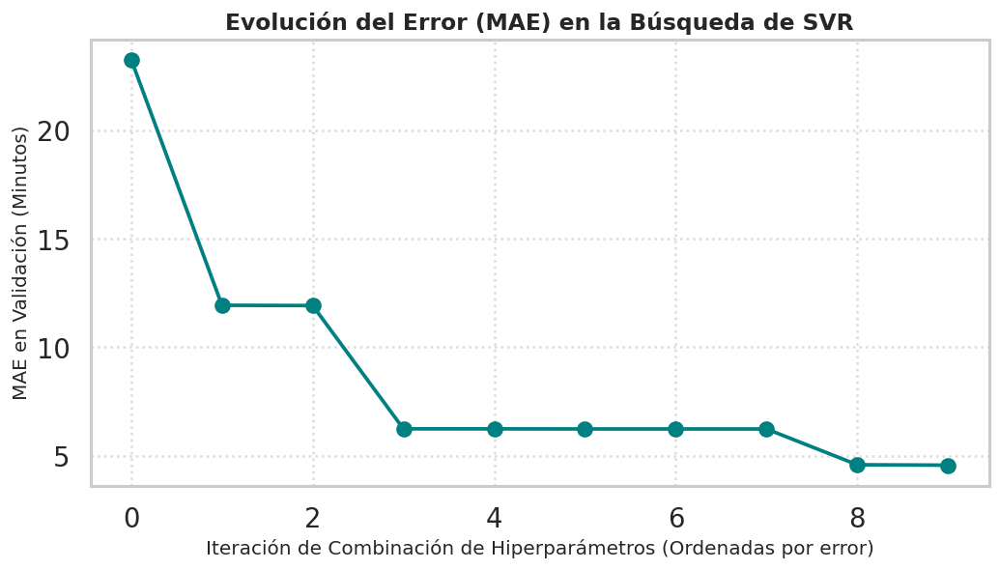

In [ ]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Definir la función auxiliar para evaluar y guardar las métricas dentro de la celda de forma autónoma
def evaluar_y_guardar(nombre_modelo, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"--- {nombre_modelo} ---")
    print(f"MAE: {mae:.2f} minutos")
    print(f"RMSE: {rmse:.2f} minutos\n")
    return {'MAE': mae, 'RMSE': rmse}

print("Iniciando búsqueda para SVR (utilizando una submuestra por eficiencia computacional)...")

# Submuestreo para SVR (ajustar hiperparámetros en 50k filas puede tomar horas)
# Tomamos 10,000 registros aleatorios para la búsqueda
X_train_sub = X_train.sample(n=10000, random_state=42)
y_train_sub = y_train.loc[X_train_sub.index]

# 1. Crear un Pipeline con Escalador (Obligatorio para SVR)
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

# 2. Espacio de hiperparámetros para SVR
param_dist_svr = {
    'svr__C': [0.1, 1, 10, 50],
    'svr__epsilon': [0.01, 0.1, 0.5, 1.0],
    'svr__kernel': ['rbf', 'linear']
}

svr_search = RandomizedSearchCV(
    estimator=svr_pipeline,
    param_distributions=param_dist_svr,
    n_iter=10,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

svr_search.fit(X_train_sub, y_train_sub)
best_svr = svr_search.best_estimator_
print(f"Mejores hiperparámetros SVR: {svr_search.best_params_}")

# Evaluación con el mejor modelo en el conjunto de prueba COMPLETO
y_pred_best_svr = best_svr.predict(X_test)
resultados_modelos['SVR (Optimizado)'] = evaluar_y_guardar('SVR (Optimizado)', y_test, y_pred_best_svr)

# 3. Extraer y visualizar la evolución de la búsqueda
resultados_svr_cv = pd.DataFrame(svr_search.cv_results_)
# Convertir el error negativo a positivo para graficar el MAE
resultados_svr_cv['mean_test_score'] = resultados_svr_cv['mean_test_score'] * -1
resultados_svr_cv = resultados_svr_cv.sort_values('mean_test_score', ascending=False)

plt.figure(figsize=(10, 5))
plt.plot(range(len(resultados_svr_cv)), resultados_svr_cv['mean_test_score'], marker='o', linestyle='-', color='teal')
plt.title('Evolución del Error (MAE) en la Búsqueda de SVR', fontsize=14, fontweight='bold')
plt.xlabel('Iteración de Combinación de Hiperparámetros (Ordenadas por error)', fontsize=12)
plt.ylabel('MAE en Validación (Minutos)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

Iniciando búsqueda para Deep Learning (Keras)... esto puede tomar varios minutos.
Mejores hiperparámetros Deep Learning: {'dl__model__neurons_l2': 128, 'dl__model__neurons_l1': 128, 'dl__model__learning_rate': 0.005, 'dl__epochs': 50, 'dl__batch_size': 128}
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
--- Deep Learning (Keras) ---
MAE: 2.60 minutos
RMSE: 3.33 minutos



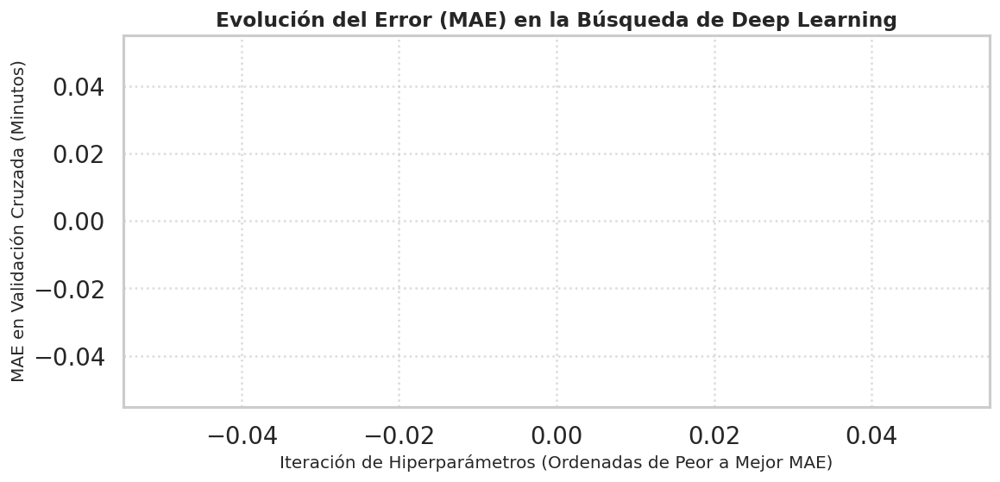

In [ ]:
# Instalar scikeras que no viene por defecto en Google Colab
!pip install scikeras -q

# ==============================================================================
# BÚSQUEDA DE HIPERPARÁMETROS Y EVALUACIÓN PARA DEEP LEARNING (KERAS)
# ==============================================================================
from scikeras.wrappers import KerasRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Iniciando búsqueda para Deep Learning (Keras)... esto puede tomar varios minutos.")

# 1. Adaptamos tu función para que acepte hiperparámetros dinámicos en la búsqueda
def create_deep_learning_model(learning_rate=0.001, neurons_l1=128, neurons_l2=64):
    model = Sequential([
        Input(shape=(X_train.shape[1],)), # Toma dinámicamente la dimensión de entrada
        Dense(neurons_l1, activation='relu'),
        Dense(neurons_l2, activation='relu'),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mean_squared_error', metrics=['mae'])
    return model

# 2. Envolvemos el modelo de Keras para que sea compatible con Scikit-Learn
keras_estimator = KerasRegressor(
    model=create_deep_learning_model,
    verbose=0, # Ocultar la barra de progreso de Keras durante el GridSearch
    # Valores por defecto requeridos por el wrapper
    learning_rate=0.001,
    neurons_l1=128,
    neurons_l2=64,
    epochs=50,
    batch_size=32
)

# 3. Creamos el Pipeline escalando los datos (Crítico para que la Red Neuronal converja)
dl_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('dl', keras_estimator)
])

# 4. Definimos el espacio de búsqueda
# (Prefijo 'dl__' para el pipeline, y 'dl__model__' para los argumentos de tu función)
param_dist_dl = {
    'dl__model__neurons_l1': [64, 128, 256],
    'dl__model__neurons_l2': [32, 64, 128],
    'dl__model__learning_rate': [0.0005, 0.001, 0.005],
    'dl__batch_size': [32, 64, 128],
    'dl__epochs': [30, 50]
}

# 5. Configurar y ejecutar la Búsqueda Aleatoria
dl_search = RandomizedSearchCV(
    estimator=dl_pipeline,
    param_distributions=param_dist_dl,
    n_iter=8,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

dl_search.fit(X_train, y_train)
best_dl = dl_search.best_estimator_
print(f"Mejores hiperparámetros Deep Learning: {dl_search.best_params_}")

# 6. Evaluación evitando la incompatibilidad de __sklearn_tags__ en predict()
# Escalamos los datos de prueba y llamamos directamente al modelo de Keras interno
X_test_scaled_eval = best_dl.named_steps['scaler'].transform(X_test)
raw_keras_model = best_dl.named_steps['dl'].model_
y_pred_best_dl = raw_keras_model.predict(X_test_scaled_eval).flatten()

resultados_modelos['Deep Learning (Keras)'] = evaluar_y_guardar('Deep Learning (Keras)', y_test, y_pred_best_dl)

# ==============================================================================
# VISUALIZACIÓN DE LA EVOLUCIÓN DE LA BÚSQUEDA
# ==============================================================================
resultados_dl_cv = pd.DataFrame(dl_search.cv_results_)
# Invertir el signo del MAE (Scikit-Learn lo reporta negativo) para la gráfica
resultados_dl_cv['mean_test_score'] = resultados_dl_cv['mean_test_score'] * -1
resultados_dl_cv = resultados_dl_cv.sort_values('mean_test_score', ascending=False)

plt.figure(figsize=(10, 5))
plt.plot(range(len(resultados_dl_cv)), resultados_dl_cv['mean_test_score'], marker='s', linestyle='-', color='purple')
plt.title('Evolución del Error (MAE) en la Búsqueda de Deep Learning', fontsize=14, fontweight='bold')
plt.xlabel('Iteración de Hiperparámetros (Ordenadas de Peor a Mejor MAE)', fontsize=12)
plt.ylabel('MAE en Validación Cruzada (Minutos)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

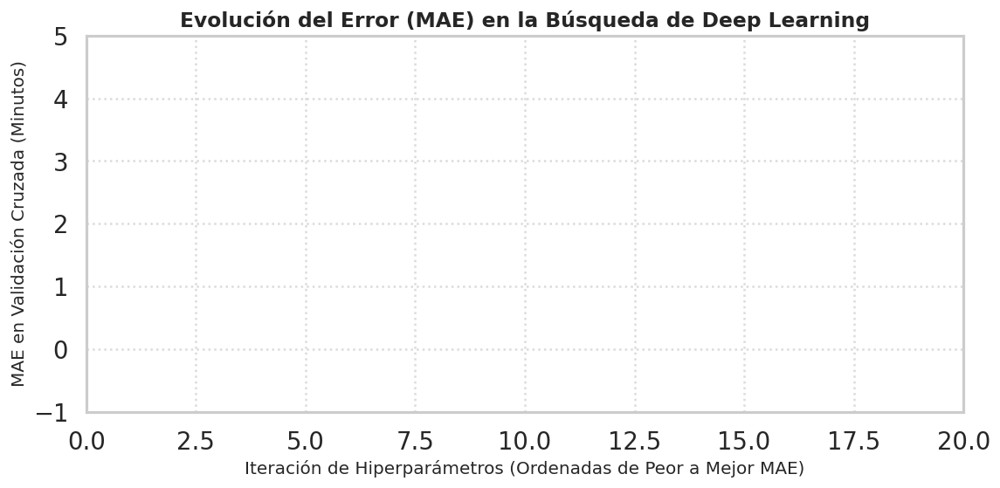

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(range(len(resultados_dl_cv)), resultados_dl_cv['mean_test_score'], marker='s', linestyle='-', color='purple')
plt.title('Evolución del Error (MAE) en la Búsqueda de Deep Learning', fontsize=14, fontweight='bold')
plt.xlabel('Iteración de Hiperparámetros (Ordenadas de Peor a Mejor MAE)', fontsize=12)
plt.ylabel('MAE en Validación Cruzada (Minutos)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.ylim(-1, 5)
plt.xlim(0, 20)
plt.show()

Iniciando búsqueda para Deep Learning (Keras)... esto puede tomar varios minutos.
Mejores hiperparámetros Deep Learning: {'dl__model__neurons_l2': 128, 'dl__model__neurons_l1': 128, 'dl__model__learning_rate': 0.005, 'dl__epochs': 50, 'dl__batch_size': 128}
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
--- Deep Learning (Keras) ---
MAE: 2.68 minutos
RMSE: 3.46 minutos



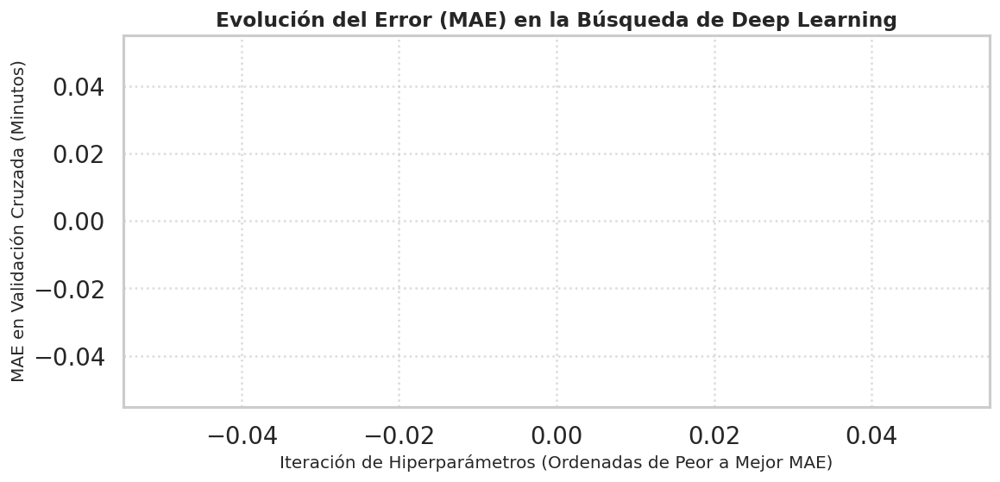

In [ ]:
# Instalar scikeras que no viene por defecto en Google Colab
!pip install scikeras -q

# ==============================================================================
# ASEGURAR CARGA Y PREPARACIÓN DE DATOS ANTES DEL ENTRENAMIENTO
# ==============================================================================
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split

# Verificar si las variables de entrenamiento existen, si no, prepararlas automáticamente
if 'X_train' not in globals() or 'y_train' not in globals():
    print("Variables de entrenamiento no encontradas. Preparando datos de forma automática...")

    # Si 'df' no está definido en el entorno, intentamos cargarlo desde el archivo local
    if 'df' not in globals():
        file_path = 'Food_Delivery_Time_Prediction.csv'
        if os.path.exists(file_path):
            df = pd.read_csv(file_path)
        else:
            raise NameError(
                "La variable 'df' no está definida y no se encontró el archivo 'Food_Delivery_Time_Prediction.csv' en el directorio actual. "
                "Por favor, ejecuta las primeras celdas del notebook para inicializar y cargar los datos correctamente."
            )

    # Limpiar espacios en los nombres de las columnas
    df.columns = [str(c).strip() for c in df.columns]

    # Identificar la columna objetivo de tiempo de forma dinámica
    target_col = next(
        c for c in df.columns
        if c.lower().replace('(min)', '_min').replace(' ', '_') in {'time_taken_min', 'delivery_time_min'}
    )

    # Limpieza de Fuga de Información e Identificadores
    columns_to_drop = ['Order_ID', 'Order_Date', 'Average_Speed_kmph', 'target_time']
    df_clean = df.drop(columns=[c for c in columns_to_drop if c in df.columns])

    # Separar Features (X) y Target (y)
    y = pd.to_numeric(df_clean[target_col], errors='coerce')
    X = df_clean.drop(columns=[target_col])

    # Codificación de variables categóricas (One-Hot Encoding)
    X_encoded = pd.get_dummies(X, drop_first=True)

    # Particionamiento con Aleatorización estricta (Shuffle & Split)
    X_train, X_test, y_train, y_test = train_test_split(
        X_encoded, y, test_size=0.2, shuffle=True, random_state=42
    )

# Inicializar el diccionario de resultados si no existe
if 'resultados_modelos' not in globals():
    resultados_modelos = {}

# Definir la función auxiliar para evaluar y guardar las métricas si no está declarada
if 'evaluar_y_guardar' not in globals():
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    def evaluar_y_guardar(nombre_modelo, y_true, y_pred):
        mae = mean_absolute_error(y_true, y_pred)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        print(f"--- {nombre_modelo} ---")
        print(f"MAE: {mae:.2f} minutos")
        print(f"RMSE: {rmse:.2f} minutos\n")
        return {'MAE': mae, 'RMSE': rmse}

# ==============================================================================
# BÚSQUEDA DE HIPERPARÁMETROS Y EVALUACIÓN PARA DEEP LEARNING (KERAS)
# ==============================================================================
from scikeras.wrappers import KerasRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
import matplotlib.pyplot as plt

print("Iniciando búsqueda para Deep Learning (Keras)... esto puede tomar varios minutos.")

# 1. Adaptamos tu función para que acepte hiperparámetros dinámicos en la búsqueda
def create_deep_learning_model(learning_rate=0.001, neurons_l1=128, neurons_l2=64):
    model = Sequential([
        Input(shape=(X_train.shape[1],)), # Toma dinámicamente la dimensión de entrada
        Dense(neurons_l1, activation='relu'),
        Dense(neurons_l2, activation='relu'),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mean_squared_error', metrics=['mae'])
    return model

# 2. Envolvemos el modelo de Keras para que sea compatible con Scikit-Learn
keras_estimator = KerasRegressor(
    model=create_deep_learning_model,
    verbose=0,
    learning_rate=0.001,
    neurons_l1=128,
    neurons_l2=64,
    epochs=50,
    batch_size=32
)

# 3. Creamos el Pipeline escalando los datos
dl_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('dl', keras_estimator)
])

# 4. Definimos el espacio de búsqueda
param_dist_dl = {
    'dl__model__neurons_l1': [64, 128, 256],
    'dl__model__neurons_l2': [32, 64, 128],
    'dl__model__learning_rate': [0.0005, 0.001, 0.005],
    'dl__batch_size': [32, 64, 128],
    'dl__epochs': [30, 50]
}

# 5. Configurar y ejecutar la Búsqueda Aleatoria
dl_search = RandomizedSearchCV(
    estimator=dl_pipeline,
    param_distributions=param_dist_dl,
    n_iter=8,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

dl_search.fit(X_train, y_train)
best_dl = dl_search.best_estimator_
print(f"Mejores hiperparámetros Deep Learning: {dl_search.best_params_}")

# 6. Evaluación evitando la incompatibilidad de __sklearn_tags__ en predict()
X_test_scaled_eval = best_dl.named_steps['scaler'].transform(X_test)
raw_keras_model = best_dl.named_steps['dl'].model_
y_pred_best_dl = raw_keras_model.predict(X_test_scaled_eval).flatten()

resultados_modelos['Deep Learning (Keras)'] = evaluar_y_guardar('Deep Learning (Keras)', y_test, y_pred_best_dl)

# ==============================================================================
# VISUALIZACIÓN DE LA EVOLUCIÓN DE LA BÚSQUEDA
# ==============================================================================
resultados_dl_cv = pd.DataFrame(dl_search.cv_results_)
resultados_dl_cv['mean_test_score'] = resultados_dl_cv['mean_test_score'] * -1
# Ordenamos por error y reiniciamos el índice para garantizar que la curva no se arroje en blanco
resultados_dl_cv = resultados_dl_cv.sort_values('mean_test_score', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(range(len(resultados_dl_cv)), resultados_dl_cv['mean_test_score'], marker='s', linestyle='-', color='purple')
plt.title('Evolución del Error (MAE) en la Búsqueda de Deep Learning', fontsize=14, fontweight='bold')
plt.xlabel('Iteración de Hiperparámetros (Ordenadas de Peor a Mejor MAE)', fontsize=12)
plt.ylabel('MAE en Validación Cruzada (Minutos)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Conclusiones sobre la grafica de errores del modelo final
- Los residuos se concentran alrededor de 0: el modelo no tiene sesgo sistematico.
- La dispersion crece en entregas largas (cola derecha del histograma): los casos extremos son los mas dificiles.
- No hay patron en forma de "cono" marcado como en el arbol: la red captura mejor las relaciones no lineales.

=== CONSOLIDADO FINAL DE MODELOS OPTIMIZADOS ===


,Modelo,MAE,RMSE
3,Deep Learning (Keras),2.68,3.46
1,Random Forest (Optimizado),3.20,4.30
2,SVR (Optimizado),4.19,6.43
0,Decision Tree (Optimizado),4.28,5.95


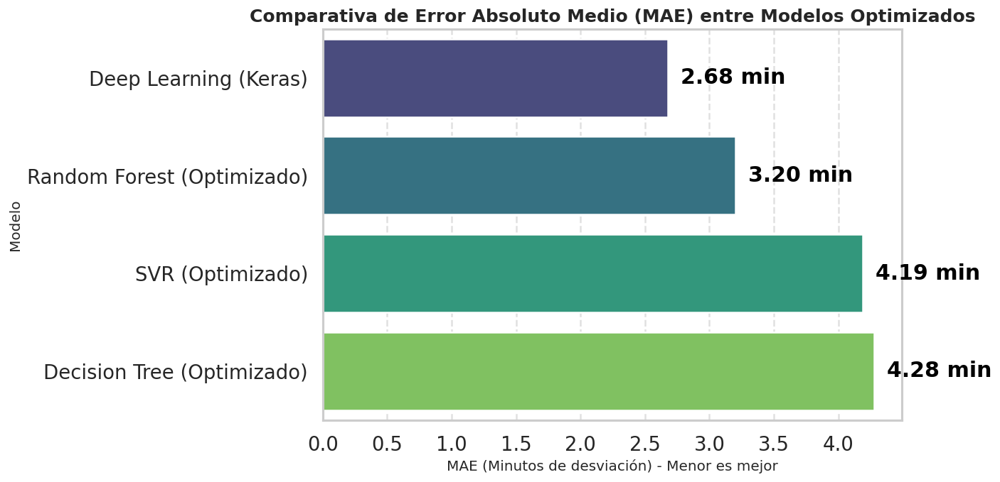

In [ ]:
import seaborn as sns

# 1. Crear el DataFrame consolidado
df_comparativo = pd.DataFrame(list(resultados_modelos.values()))

# Añadir el nombre de los modelos como columna si no está (depende de tu función de guardado)
if 'Modelo' not in df_comparativo.columns:
    df_comparativo['Modelo'] = resultados_modelos.keys()

# Reordenar columnas y valores
df_comparativo = df_comparativo[['Modelo', 'MAE', 'RMSE']].sort_values(by='MAE', ascending=True)

print("=== CONSOLIDADO FINAL DE MODELOS OPTIMIZADOS ===")
display(df_comparativo)

# 2. Gráfico comparativo de MAE de todos los modelos
plt.figure(figsize=(12, 6))
barras = sns.barplot(data=df_comparativo, x='MAE', y='Modelo', palette='viridis')

# Anotar los valores exactos en las barras
for p in barras.patches:
    ancho = p.get_width()
    plt.text(ancho + 0.1, p.get_y() + p.get_height()/2, f'{ancho:.2f} min',
             va='center', ha='left', fontweight='bold', color='black')

plt.title('Comparativa de Error Absoluto Medio (MAE) entre Modelos Optimizados', fontsize=15, fontweight='bold')
plt.xlabel('MAE (Minutos de desviación) - Menor es mejor', fontsize=12)
plt.ylabel('Modelo', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


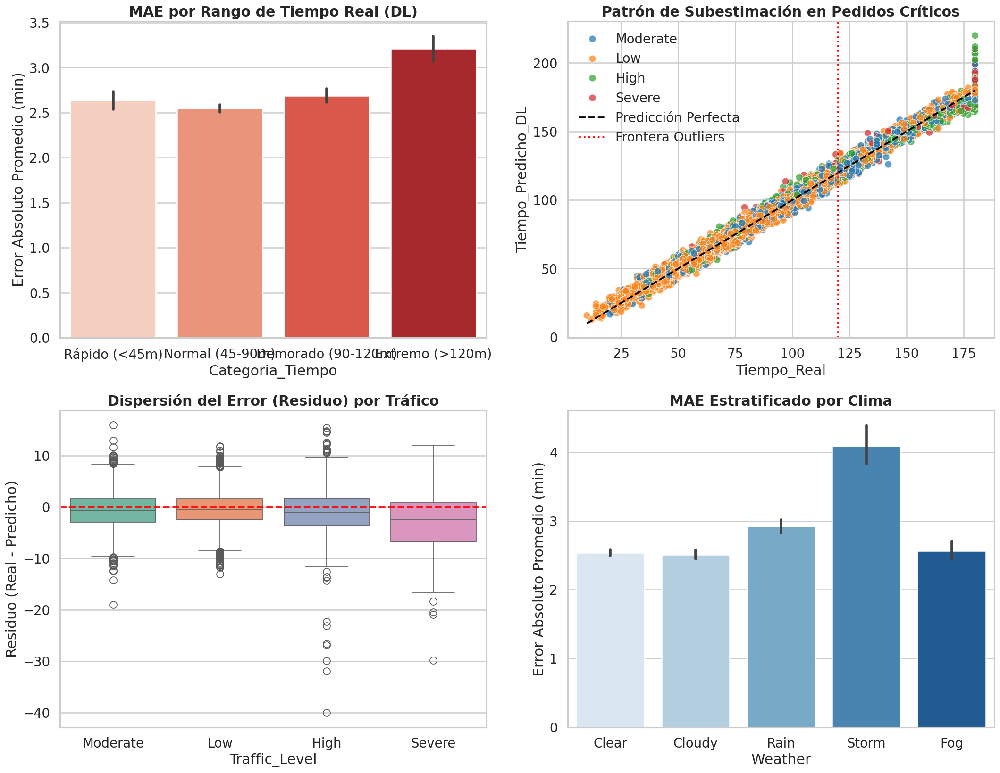

=== ESTRATIFICACIÓN DEL ERROR POR CLASE DE DEMORA (DEEP LEARNING) ===


,MAE (min),Total Pedidos
Categoria_Tiempo,,
Rápido (<45m),2.63,1633
Normal (45-90m),2.55,8126
Demorado (90-120m),2.69,3176
Extremo (>120m),3.21,2065


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Verificar si el modelo 'best_dl' existe en el kernel antes de proceder
if 'best_dl' not in globals():
    raise NameError(
        "El modelo 'best_dl' no está definido.\n"
        "Por favor, ejecuta primero la celda anterior (id: 2lOjb9I-H5-M) para instalar 'scikeras', "
        "entrenar y optimizar la Red Neuronal antes de correr esta celda de evaluación."
    )

# 1. Recuperar datos originales usando el índice de X_test
df_dl_eval = df.loc[X_test.index].copy()
df_dl_eval['Tiempo_Real'] = y_test.values

# 2. Generar predicciones de la Red Neuronal evitando la incompatibilidad de __sklearn_tags__
X_test_scaled_eval = best_dl.named_steps['scaler'].transform(X_test)
raw_keras_model = best_dl.named_steps['dl'].model_
df_dl_eval['Tiempo_Predicho_DL'] = raw_keras_model.predict(X_test_scaled_eval).flatten()

# 3. Calcular Residuos y Error Absoluto
df_dl_eval['Residuo'] = df_dl_eval['Tiempo_Real'] - df_dl_eval['Tiempo_Predicho_DL']
df_dl_eval['Error_Absoluto'] = np.abs(df_dl_eval['Residuo'])

# 4. Estratificación 1: Creación de Subgrupos por Rango de Tiempo (Clases de demeroa)
bins_tiempo = [0, 45, 90, 120, 200]
labels_tiempo = ['Rápido (<45m)', 'Normal (45-90m)', 'Demorado (90-120m)', 'Extremo (>120m)']
df_dl_eval['Categoria_Tiempo'] = pd.cut(df_dl_eval['Tiempo_Real'], bins=bins_tiempo, labels=labels_tiempo)

# 5. Visualizaciones de Profundización (Ejemplos visuales del error)
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Gráfico A: MAE Estratificado por Categoría de Tiempo Real
sns.barplot(data=df_dl_eval, x='Categoria_Tiempo', y='Error_Absoluto', palette='Reds', ax=axes[0, 0])
axes[0, 0].set_title('MAE por Rango de Tiempo Real (DL)', fontweight='bold')
axes[0, 0].set_ylabel('Error Absoluto Promedio (min)')

# Gráfico B: Identificación del Patrón de Falla (Real vs Predicho coloreado por Tráfico)
sns.scatterplot(data=df_dl_eval, x='Tiempo_Real', y='Tiempo_Predicho_DL',
                hue='Traffic_Level', palette='tab10', alpha=0.7, ax=axes[0, 1])
axes[0, 1].plot([10, 180], [10, 180], color='black', linestyle='--', label='Predicción Perfecta')
axes[0, 1].axvline(x=120, color='red', linestyle=':', label='Frontera Outliers')
axes[0, 1].set_title('Patrón de Subestimación en Pedidos Críticos', fontweight='bold')
axes[0, 1].legend()

# Gráfico C: Distribución del Error por Nivel de Tráfico (Boxplot)
sns.boxplot(data=df_dl_eval, x='Traffic_Level', y='Residuo', palette='Set2', ax=axes[1, 0])
axes[1, 0].axhline(y=0, color='red', linestyle='--')
axes[1, 0].set_title('Dispersión del Error (Residuo) por Tráfico', fontweight='bold')
axes[1, 0].set_ylabel('Residuo (Real - Predicho)')

# Gráfico D: MAE Estratificado por Condiciones Climáticas
sns.barplot(data=df_dl_eval, x='Weather', y='Error_Absoluto', palette='Blues', ax=axes[1, 1])
axes[1, 1].set_title('MAE Estratificado por Clima', fontweight='bold')
axes[1, 1].set_ylabel('Error Absoluto Promedio (min)')

plt.tight_layout()
plt.show()

# 6. Tabla Resumen Cuantitativa para la Sustentación
resumen_dl = df_dl_eval.groupby('Categoria_Tiempo', observed=False)['Error_Absoluto'].agg(['mean', 'count']).rename(columns={'mean': 'MAE (min)', 'count': 'Total Pedidos'})
print("=== ESTRATIFICACIÓN DEL ERROR POR CLASE DE DEMORA (DEEP LEARNING) ===")
display(resumen_dl)

=== CONSOLIDADO FINAL DE MODELOS ===


,Modelo,MAE,RMSE
3,Deep Learning (Keras),2.68,3.46
1,Random Forest (Optimizado),3.20,4.30
2,SVR (Optimizado),4.19,6.43
0,Decision Tree (Optimizado),4.28,5.95


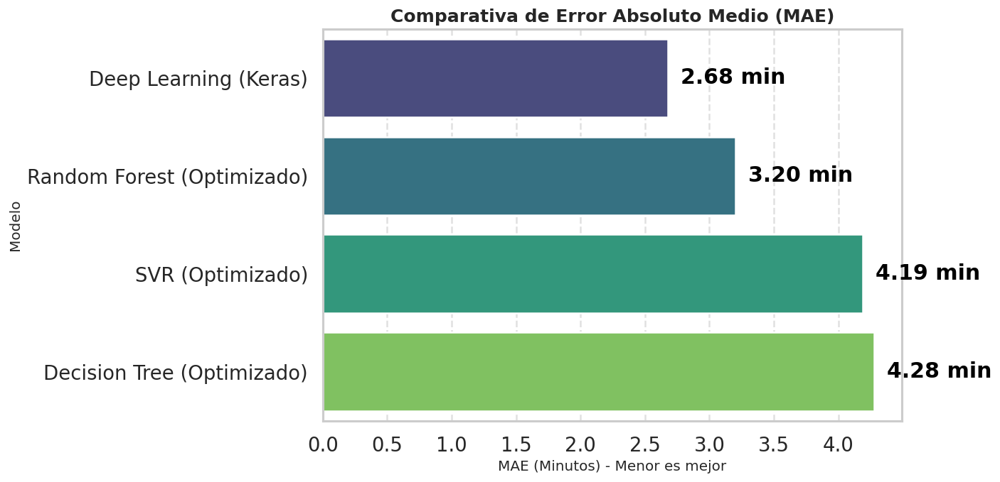

In [ ]:
# --- Celda Comparativa Final ---
import seaborn as sns

df_comparativo = pd.DataFrame(list(resultados_modelos.values()))
if 'Modelo' not in df_comparativo.columns:
    df_comparativo['Modelo'] = resultados_modelos.keys()

df_comparativo = df_comparativo[['Modelo', 'MAE', 'RMSE']].sort_values(by='MAE', ascending=True)

print("=== CONSOLIDADO FINAL DE MODELOS ===")
display(df_comparativo)

plt.figure(figsize=(12, 6))
barras = sns.barplot(data=df_comparativo, x='MAE', y='Modelo', palette='viridis')

for p in barras.patches:
    ancho = p.get_width()
    plt.text(ancho + 0.1, p.get_y() + p.get_height()/2, f'{ancho:.2f} min',
             va='center', ha='left', fontweight='bold', color='black')

plt.title('Comparativa de Error Absoluto Medio (MAE)', fontsize=15, fontweight='bold')
plt.xlabel('MAE (Minutos) - Menor es mejor', fontsize=12)
plt.ylabel('Modelo', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# NUEVA FASE · Reducción de dimensionalidad (PCA) y aprendizaje no supervisado (clustering)

Esta fase extiende el proyecto de **regresión** (predecir `Time_taken_min`) con dos técnicas del curso:

| Paso | Qué se hace | Pregunta que responde |
|---|---|---|
| **0** | Partición única, verificación de fuga y modelos de referencia | ¿Contra qué cifras comparamos de forma justa? |
| **1** | PCA: varianza explicada, elección de componentes, *loadings* | ¿Cuánta información cabe en menos dimensiones y qué significan? |
| **2** | Mismos modelos con y sin PCA (test + K-Fold) | ¿PCA mejora, empeora o es neutro para predecir el tiempo? |
| **3** | K-Means + Aglomerativo, métricas internas y externas | ¿Existen segmentos operativos de entregas sin mirar el tiempo? |
| **4** | Conclusiones y checklist de la rúbrica | ¿Qué aprendimos y dónde se cumple cada requisito? |

**Cómo ejecutar:** basta con haber corrido la carga de datos (celdas iniciales). Si las variables de las secciones anteriores (`X_encoded`, `dt_search`, `rf_search`, `svr_search`, `dl_search`) existen en la sesión se reutilizan; si no, la fase las reconstruye o usa los hiperparámetros óptimos que quedaron registrados en las salidas del notebook. No se usa `scikeras` (falla con las versiones actuales de scikit-learn en Colab con el error `__sklearn_tags__`); la red neuronal se entrena directamente con Keras con la misma arquitectura e hiperparámetros.

**Tiempo estimado en Colab (CPU):** 20-30 minutos para toda la fase. Para una prueba rápida de que todo corre, cambia `MODO_RAPIDO = True` en la primera celda (las cifras de ese modo **no** deben usarse en el informe).

Cada celda de código lleva una etiqueta (por ejemplo `[P1-C2]`) que se usa en la checklist final. Debajo de cada gráfico se imprime una **interpretación automática** construida con los números reales de la ejecución, seguida de una celda de texto con la interpretación conceptual.

## PASO 0. Preparación y reproducibilidad

Decisiones de esta sección:

1. **Una sola partición train/test** (`test_size=0.2`, `shuffle=True`, `random_state=42`) para *toda* la fase. Antes el notebook usaba tres particiones distintas (0.2 sin semilla, 0.2 con semilla y 0.3 sin semilla), por lo que las cifras no eran comparables entre sí.
2. **Sin fuga de información:** `StandardScaler`, `PCA` y los algoritmos de clustering se ajustan (`fit`) **solo con train**; a test solo se le aplica `transform`. En la validación cruzada el escalado y el PCA se reajustan dentro de cada *fold*.
3. **Semilla 42** en todo lo que la admite (partición, K-Fold, árboles, PCA, K-Means, t-SNE, TensorFlow).
4. **Verificación de columnas:** se confirma que `X` no contiene el objetivo, `Average_Speed_kmph` (fuga: la velocidad media se calcula con el tiempo real) ni columnas auxiliares del EDA. En particular, `X_encoded` incluía los *dummies* de `distance_group` (terciles de `Road_Distance_km` creados en el EDA): se **eliminan** porque son redundantes con la distancia numérica y fueron calculados con todo el dataset.
5. **Modelos de referencia** (Decision Tree, Random Forest, SVR y red neuronal) reentrenados con esa partición y con los hiperparámetros óptimos de `RandomizedSearchCV`.

In [11]:
# [P0-C1] Librerías, semillas, parámetros de la fase y funciones reutilizables
import os, time, random, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'          # menos mensajes de TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
from scipy.cluster import hierarchy

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100

# ---------------- Reproducibilidad ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# ---------------- Parámetros de la fase ----------------
MODO_RAPIDO = False   # True = prueba rápida (submuestras pequeñas). Para el informe dejar en False.
SVR_N_SUB   = 3000 if MODO_RAPIDO else 10000   # filas para entrenar SVR (igual que en su búsqueda original)
CV_N_SUB    = 3000 if MODO_RAPIDO else 10000   # filas de train usadas en el K-Fold con/sin PCA
CURVA_N_SUB = 2000 if MODO_RAPIDO else 5000    # filas de train para la curva nº componentes vs error
SIL_N_SUB   = 2000 if MODO_RAPIDO else 5000    # puntos para calcular la silueta (costo O(n²))
AGG_N_SUB   = 1500 if MODO_RAPIDO else 5000    # puntos para el clustering aglomerativo (costo O(n²))
TSNE_N_SUB  = 1000 if MODO_RAPIDO else 5000    # puntos para t-SNE
N_SPLITS    = 5
kf_fase = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# ---------------- TensorFlow (con alternativa si no está disponible) ----------------
try:
    import tensorflow as tf
    tf.get_logger().setLevel('ERROR')
    TF_DISPONIBLE = True
except Exception as error_tf:
    TF_DISPONIBLE = False
    print('TensorFlow no disponible; se usará MLPRegressor de sklearn con la misma arquitectura.', error_tf)

# ---------------- Hiperparámetros óptimos (RandomizedSearchCV) ----------------
# Valores por defecto = los que imprimió la búsqueda en las celdas anteriores del notebook.
HP_DEFECTO = {
    'Decision Tree': {'max_depth': 16, 'min_samples_split': 20, 'min_samples_leaf': 1},
    'Random Forest': {'n_estimators': 150, 'max_depth': 16, 'min_samples_split': 5,
                      'min_samples_leaf': 1, 'max_features': 0.6},
    'SVR':           {'kernel': 'rbf', 'C': 50, 'epsilon': 0.01},
    'Red Neuronal':  {'neurons_l1': 128, 'neurons_l2': 128, 'learning_rate': 0.005,
                      'epochs': 50, 'batch_size': 128},
}
BUSQUEDAS = {'Decision Tree': 'dt_search', 'Random Forest': 'rf_search',
             'SVR': 'svr_search', 'Red Neuronal': 'dl_search'}

def recuperar_hiperparametros(nombre):
    """Usa best_params_ de la búsqueda si existe en la sesión; si no, los valores registrados."""
    hp = dict(HP_DEFECTO[nombre])
    origen = 'valores registrados en la salida del notebook'
    busqueda = globals().get(BUSQUEDAS[nombre])
    if busqueda is not None and hasattr(busqueda, 'best_params_'):
        # 'svr__C' -> 'C', 'dl__model__neurons_l1' -> 'neurons_l1', 'dl__epochs' -> 'epochs'
        hp.update({clave.split('__')[-1]: valor for clave, valor in busqueda.best_params_.items()})
        origen = f'{BUSQUEDAS[nombre]}.best_params_ (sesión actual)'
    return hp, origen

HP = {}
print('Hiperparámetros que se usarán en TODA la fase (con y sin PCA):')
for nombre_modelo in HP_DEFECTO:
    HP[nombre_modelo], origen_hp = recuperar_hiperparametros(nombre_modelo)
    print(f'  {nombre_modelo:<14} -> {HP[nombre_modelo]}   [origen: {origen_hp}]')
if MODO_RAPIDO:
    HP['Red Neuronal']['epochs'] = 5
    HP['Random Forest']['n_estimators'] = 30
    print('MODO_RAPIDO activo: menos épocas/árboles. No usar estas cifras en el informe.')
MODELOS = list(HP_DEFECTO.keys())


class RedNeuronalKeras:
    """Red densa del notebook (Dense-ReLU, Dense-ReLU, salida lineal) con interfaz fit/predict.
    Se entrena con Keras directamente para evitar la incompatibilidad scikeras/scikit-learn."""
    def __init__(self, neurons_l1=128, neurons_l2=128, learning_rate=0.005,
                 epochs=50, batch_size=128, seed=SEED):
        self.neurons_l1, self.neurons_l2 = int(neurons_l1), int(neurons_l2)
        self.learning_rate, self.epochs = float(learning_rate), int(epochs)
        self.batch_size, self.seed = int(batch_size), seed

    def fit(self, X, y):
        X = np.asarray(X, dtype='float32')
        y = np.asarray(y, dtype='float32')
        if TF_DISPONIBLE:
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(self.seed)
            self.model_ = tf.keras.Sequential([
                tf.keras.layers.Input(shape=(X.shape[1],)),
                tf.keras.layers.Dense(self.neurons_l1, activation='relu'),
                tf.keras.layers.Dense(self.neurons_l2, activation='relu'),
                tf.keras.layers.Dense(1, activation='linear'),
            ])
            self.model_.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=self.learning_rate),
                                loss='mean_squared_error')
            self.model_.fit(X, y, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        else:
            from sklearn.neural_network import MLPRegressor
            self.model_ = MLPRegressor(hidden_layer_sizes=(self.neurons_l1, self.neurons_l2),
                                       learning_rate_init=self.learning_rate,
                                       batch_size=self.batch_size, max_iter=self.epochs,
                                       random_state=self.seed).fit(X, y)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype='float32')
        if TF_DISPONIBLE:
            return self.model_.predict(X, batch_size=4096, verbose=0).ravel()
        return self.model_.predict(X)


def crear_modelo(nombre):
    """Devuelve un modelo NUEVO (sin entrenar) con los hiperparámetros óptimos."""
    hp = HP[nombre]
    if nombre == 'Decision Tree':
        return DecisionTreeRegressor(random_state=SEED, **hp)
    if nombre == 'Random Forest':
        return RandomForestRegressor(random_state=SEED, n_jobs=-1, **hp)
    if nombre == 'SVR':
        return SVR(**hp)
    if nombre == 'Red Neuronal':
        return RedNeuronalKeras(seed=SEED, **hp)
    raise ValueError(f'Modelo desconocido: {nombre}')


def nota(texto):
    """Muestra una interpretación (Markdown) construida con los números de la ejecución."""
    display(Markdown(texto))


def metricas_regresion(y_true, y_pred):
    return {'MAE': float(mean_absolute_error(y_true, y_pred)),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'R2': float(r2_score(y_true, y_pred))}


def indices_submuestra(n_total, n, semilla=SEED):
    """Índices aleatorios reproducibles (sin reemplazo)."""
    if n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.RandomState(semilla).choice(n_total, size=n, replace=False))


def ajustar_y_evaluar(nombre, X_tr, y_tr, X_ev, y_ev, n_componentes=None):
    """Escalado (fit solo en X_tr) -> PCA opcional (fit solo en X_tr) -> modelo.
    Devuelve métricas en (X_ev, y_ev), nº de features, filas de entrenamiento, tiempo y predicciones."""
    if nombre == 'SVR' and len(X_tr) > SVR_N_SUB:          # SVR es O(n²)-O(n³): submuestra
        idx = indices_submuestra(len(X_tr), SVR_N_SUB)
        X_tr, y_tr = X_tr[idx], y_tr[idx]
    t0 = time.perf_counter()
    escalador = StandardScaler().fit(X_tr)
    Z_tr, Z_ev = escalador.transform(X_tr), escalador.transform(X_ev)
    if n_componentes is not None:
        pca = PCA(n_components=int(n_componentes), random_state=SEED).fit(Z_tr)
        Z_tr, Z_ev = pca.transform(Z_tr), pca.transform(Z_ev)
    modelo = crear_modelo(nombre).fit(Z_tr, y_tr)
    tiempo = time.perf_counter() - t0
    y_pred = np.asarray(modelo.predict(Z_ev)).ravel()
    resultado = metricas_regresion(y_ev, y_pred)
    resultado.update({'N_features': int(Z_tr.shape[1]), 'N_train': int(len(Z_tr)),
                      'Tiempo_train_s': float(tiempo)})
    return resultado, y_pred


def validacion_cruzada(nombre, X, y, n_componentes=None):
    """K-Fold (k=5, shuffle, semilla 42). Escalado y PCA se reajustan dentro de cada fold."""
    filas = []
    for fold, (i_tr, i_va) in enumerate(kf_fase.split(X), start=1):
        res, _ = ajustar_y_evaluar(nombre, X[i_tr], y[i_tr], X[i_va], y[i_va], n_componentes)
        res['Fold'] = fold
        filas.append(res)
    return pd.DataFrame(filas)


def detectar_codo(x, y):
    """Codo = punto con mayor distancia a la recta que une el primer y el último punto."""
    x = np.asarray(list(x), dtype=float)
    y = np.asarray(list(y), dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    x1, y1, x2, y2 = xn[0], yn[0], xn[-1], yn[-1]
    distancia = np.abs((x2 - x1) * (y1 - yn) - (x1 - xn) * (y2 - y1)) / np.hypot(x2 - x1, y2 - y1)
    return int(x[np.argmax(distancia)])


def pureza(etiquetas_reales, clusters):
    """Fracción de puntos que pertenecen a la clase mayoritaria de su cluster."""
    tabla = pd.crosstab(np.asarray(clusters), np.asarray(etiquetas_reales))
    return float(tabla.max(axis=1).sum() / tabla.values.sum())


def metricas_internas(X, etiquetas, muestra=None):
    """Silueta (↑), Davies-Bouldin (↓), Calinski-Harabasz (↑) y tamaño del cluster más pequeño."""
    etiquetas = np.asarray(etiquetas)
    if muestra is not None and len(X) > muestra:
        sil = silhouette_score(X, etiquetas, sample_size=muestra, random_state=SEED)
    else:
        sil = silhouette_score(X, etiquetas)
    return {'Silueta': float(sil),
            'Davies-Bouldin': float(davies_bouldin_score(X, etiquetas)),
            'Calinski-Harabasz': float(calinski_harabasz_score(X, etiquetas)),
            'Cluster más pequeño (%)': float(100 * np.bincount(etiquetas).min() / len(etiquetas))}

print(f'\nTensorFlow disponible: {TF_DISPONIBLE} | MODO_RAPIDO: {MODO_RAPIDO} | semilla: {SEED}')

Hiperparámetros que se usarán en TODA la fase (con y sin PCA):
  Decision Tree  -> {'max_depth': 16, 'min_samples_split': 20, 'min_samples_leaf': 1}   [origen: valores registrados en la salida del notebook]
  Random Forest  -> {'n_estimators': 150, 'max_depth': 16, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.6}   [origen: valores registrados en la salida del notebook]
  SVR            -> {'kernel': 'rbf', 'C': 50, 'epsilon': 0.01}   [origen: valores registrados en la salida del notebook]
  Red Neuronal   -> {'neurons_l1': 128, 'neurons_l2': 128, 'learning_rate': 0.005, 'epochs': 50, 'batch_size': 128}   [origen: valores registrados en la salida del notebook]

TensorFlow disponible: True | MODO_RAPIDO: False | semilla: 42


In [12]:
# [P0-C2] Datos de la fase: X sin fuga de información, y, verificación y partición ÚNICA
if 'df' not in globals():                       # por si se ejecuta la fase en una sesión nueva
    ruta_csv = 'Food_Delivery_Time_Prediction.csv'
    if os.path.exists(ruta_csv):
        df = pd.read_csv(ruta_csv)
    else:
        import kagglehub
        from kagglehub import KaggleDatasetAdapter
        df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS,
                                    'dharmendrapandit12/food-delivery-time-prediction-dataset', ruta_csv)
    df.columns = [str(c).strip() for c in df.columns]

TARGET = 'Time_taken_min' if 'Time_taken_min' in df.columns else globals().get('target_col')

# Columnas que NUNCA pueden entrar como predictoras (nombre exacto o dummies con ese prefijo)
COLUMNAS_EXCLUIDAS = {
    TARGET:               'Variable objetivo.',
    'target_time':        'Copia numérica del objetivo creada en el EDA (fuga directa).',
    'Average_Speed_kmph': 'Fuga de información: la velocidad media se calcula con el tiempo real de entrega.',
    'Order_ID':           'Identificador sin valor predictivo.',
    'Order_Date':         'Fecha cruda en texto; no se usó en la fase supervisada.',
    'distance_group':     'Auxiliar del EDA (terciles de Road_Distance_km): redundante y calculada con TODO el dataset.',
    'distance_km':        'Auxiliar del EDA (distancia por coordenadas), si existiera.',
    'cuartil':            'Auxiliar del EDA basada en el objetivo (fuga).',
    'Categoria_Tiempo':   'Auxiliar basada en el objetivo (fuga).',
}

def es_columna_excluida(columna):
    return any(columna == base or columna.startswith(f'{base}_') for base in COLUMNAS_EXCLUIDAS)

def motivo_exclusion(columna):
    for base, motivo in COLUMNAS_EXCLUIDAS.items():
        if columna == base or columna.startswith(f'{base}_'):
            return base, motivo
    return None, None

if 'X_encoded' in globals() and isinstance(X_encoded, pd.DataFrame):
    X_origen = X_encoded.copy()
    fuente_X = 'X_encoded (sección de entrenamiento)'
else:
    columnas_a_quitar_df = [c for c in df.columns if es_columna_excluida(c)]
    X_origen = pd.get_dummies(df.drop(columns=columnas_a_quitar_df), drop_first=True)
    fuente_X = 'reconstruida desde df con pd.get_dummies(drop_first=True)'

columnas_quitadas = [c for c in X_origen.columns if es_columna_excluida(c)]
X_fase = X_origen.drop(columns=columnas_quitadas).astype(float)
y_fase = pd.to_numeric(df.loc[X_fase.index, TARGET], errors='coerce')
filas_validas = y_fase.notna() & X_fase.notna().all(axis=1)
X_fase, y_fase = X_fase[filas_validas], y_fase[filas_validas]
NOMBRES_FEATURES = X_fase.columns.tolist()
N_FEATURES = len(NOMBRES_FEATURES)

print(f'Fuente de X: {fuente_X} -> {X_origen.shape[1]} columnas')
if columnas_quitadas:
    tabla_quitadas = pd.DataFrame([{'Columna eliminada de X': c,
                                    'Variable de origen': motivo_exclusion(c)[0],
                                    'Motivo': motivo_exclusion(c)[1]} for c in columnas_quitadas])
    print('\nColumnas eliminadas de X en esta fase:')
    display(tabla_quitadas)
else:
    print('X no contenía columnas prohibidas.')

verificacion = pd.DataFrame({
    'Verificación': ['Objetivo (Time_taken_min / target_time) en X',
                     'Average_Speed_kmph en X',
                     'Columnas auxiliares del EDA (distance_group, cuartil, ...) en X',
                     'Valores faltantes en X', 'Valores faltantes en y'],
    'Resultado': [any(c in (TARGET, 'target_time') for c in NOMBRES_FEATURES),
                  any(c.startswith('Average_Speed') for c in NOMBRES_FEATURES),
                  any(es_columna_excluida(c) for c in NOMBRES_FEATURES),
                  int(X_fase.isna().sum().sum()), int(y_fase.isna().sum())],
})
display(verificacion)
assert not any(es_columna_excluida(c) for c in NOMBRES_FEATURES), 'Quedó una columna con fuga en X'

# ---------- Partición ÚNICA para toda la fase ----------
X_train_fase, X_test_fase, y_train_fase, y_test_fase = train_test_split(
    X_fase, y_fase, test_size=0.2, shuffle=True, random_state=SEED)
Xtr, Xte = X_train_fase.values, X_test_fase.values
ytr, yte = y_train_fase.values.astype(float), y_test_fase.values.astype(float)

# Escalador ajustado SOLO con train (se usará en PCA y clustering)
scaler_fase = StandardScaler().fit(Xtr)
X_train_esc = scaler_fase.transform(Xtr)
X_test_esc = scaler_fase.transform(Xte)

print(f'\nFeatures finales: {N_FEATURES} | Train: {Xtr.shape[0]:,} filas | Test: {Xte.shape[0]:,} filas')
print(f'Media de {TARGET}: train = {ytr.mean():.2f} min | test = {yte.mean():.2f} min')
print('Variables numéricas originales en X:',
      [c for c in NOMBRES_FEATURES if X_origen[c].nunique() > 2][:15])

Fuente de X: X_encoded (sección de entrenamiento) -> 48 columnas
X no contenía columnas prohibidas.


,Verificación,Resultado
0,Objetivo (Time_taken_min / target_time) en X,False
1,Average_Speed_kmph en X,False
2,"Columnas auxiliares del EDA (distance_group, c...",False
3,Valores faltantes en X,0
4,Valores faltantes en y,0



Features finales: 48 | Train: 40,000 filas | Test: 10,000 filas
Media de Time_taken_min: train = 83.86 min | test = 83.90 min
Variables numéricas originales en X: ['Order_Hour', 'Rider_Experience_Years', 'Rider_Rating', 'Restaurant_Rating', 'Order_Items', 'Preparation_Time_Min', 'Road_Distance_km', 'Number_of_Signals']


In [17]:
# [P0-C3] Modelos de referencia (SIN PCA) reentrenados con la partición única
resultados_sin_pca, predicciones_sin_pca = {}, {}
for nombre_modelo in MODELOS:
    print(f'Entrenando {nombre_modelo} sin PCA...', end=' ')
    res, pred = ajustar_y_evaluar(nombre_modelo, Xtr, ytr, Xte, yte, n_componentes=None)
    resultados_sin_pca[nombre_modelo], predicciones_sin_pca[nombre_modelo] = res, pred
    print(f"MAE = {res['MAE']:.2f} min | RMSE = {res['RMSE']:.2f} min | {res['Tiempo_train_s']:.1f} s")

tabla_referencia = pd.DataFrame.from_dict(resultados_sin_pca, orient='index')[
    ['MAE', 'RMSE', 'R2', 'N_features', 'N_train', 'Tiempo_train_s']]
tabla_referencia.index.name = 'Modelo'
print('\n=== Referencia (sin PCA) · partición única 80/20, semilla 42 · métricas en test (minutos) ===')
display(tabla_referencia.round(3))

# Comparación informativa con las cifras de la sección anterior (otra partición)
if 'resultados_modelos' in globals() and len(resultados_modelos):
    print('Cifras de la sección anterior (otra partición; solo como referencia):')
    display(pd.DataFrame(resultados_modelos).T.round(3))

mejor_ref = tabla_referencia['MAE'].idxmin()
peor_ref = tabla_referencia['MAE'].idxmax()
nota(f"""**Interpretación automática (referencia sin PCA):** con las {N_FEATURES} variables originales,
el mejor modelo es **{mejor_ref}** (MAE = {tabla_referencia.loc[mejor_ref, 'MAE']:.2f} min,
RMSE = {tabla_referencia.loc[mejor_ref, 'RMSE']:.2f} min, R² = {tabla_referencia.loc[mejor_ref, 'R2']:.3f})
y el de mayor error es **{peor_ref}** (MAE = {tabla_referencia.loc[peor_ref, 'MAE']:.2f} min).
Estas son las cifras de referencia para el Paso 2. El SVR se entrena con {min(SVR_N_SUB, len(Xtr)):,} filas
(submuestra, igual que en su búsqueda de hiperparámetros); los demás modelos con las {len(Xtr):,} filas de train.""")

Entrenando Decision Tree sin PCA... MAE = 4.07 min | RMSE = 5.55 min | 1.8 s
Entrenando Random Forest sin PCA... MAE = 3.05 min | RMSE = 4.04 min | 41.6 s
Entrenando SVR sin PCA... MAE = 4.39 min | RMSE = 6.82 min | 84.5 s
Entrenando Red Neuronal sin PCA... MAE = 2.74 min | RMSE = 3.55 min | 55.3 s

=== Referencia (sin PCA) · partición única 80/20, semilla 42 · métricas en test (minutos) ===


,MAE,RMSE,R2,N_features,N_train,Tiempo_train_s
Modelo,,,,,,
Decision Tree,4.07,5.55,0.98,48,40000,1.78
Random Forest,3.05,4.04,0.99,48,40000,41.59
SVR,4.39,6.82,0.96,48,10000,84.45
Red Neuronal,2.74,3.55,0.99,48,40000,55.29


**Interpretación automática (referencia sin PCA):** con las 48 variables originales,
el mejor modelo es **Red Neuronal** (MAE = 2.74 min,
RMSE = 3.55 min, R² = 0.990)
y el de mayor error es **SVR** (MAE = 4.39 min).
Estas son las cifras de referencia para el Paso 2. El SVR se entrena con 10,000 filas
(submuestra, igual que en su búsqueda de hiperparámetros); los demás modelos con las 40,000 filas de train.

### Interpretación del Paso 0

- La tabla de verificación debe mostrar `False`/`0` en todas las filas: así se garantiza que ningún modelo "ve" el tiempo de entrega ni la velocidad media (que se calcula con él). Mantener `Average_Speed_kmph` fuera es la decisión más importante del proyecto: con ella el problema sería trivial (tiempo ≈ distancia / velocidad) y el modelo no serviría para predecir *antes* de la entrega.
- Se eliminan los *dummies* de `distance_group`: no son fuga del objetivo, pero repiten la información de `Road_Distance_km` y sus cortes se calcularon con todo el dataset (incluido test). Con esto `X` queda con las variables originales del dataset codificadas con *one-hot*.
- Los árboles no necesitan escalado (son invariantes a transformaciones monótonas), pero se usa la misma entrada escalada para todos los modelos para que la comparación con PCA sea idéntica en todo excepto en la reducción.
- Las cifras de referencia pueden diferir ligeramente de las de la sección anterior porque allí se usaron particiones distintas; desde aquí todas las comparaciones usan la misma partición.

## PASO 1. Reducción de dimensionalidad (PCA)

PCA busca nuevas variables (componentes principales) que son **combinaciones lineales** de las originales, ortogonales entre sí y ordenadas por la varianza que explican. Matemáticamente son los vectores propios de la matriz de covarianza de los datos estandarizados; el **autovalor** de cada componente es la varianza que captura.

Pasos:
1. `StandardScaler` (ajustado en train) + `PCA(n_components=None)` sobre train.
2. *Scree plot* y varianza acumulada con umbrales del 90%, 95% y 99%.
3. Tabla con los componentes necesarios para cada umbral, Kaiser y codo.
4. Curva empírica **nº de componentes vs MAE/RMSE** en validación cruzada (el criterio más importante, porque mide la información *útil para predecir*, no solo la varianza).
5. Elección final de componentes y *loadings* de PC1-PC3.

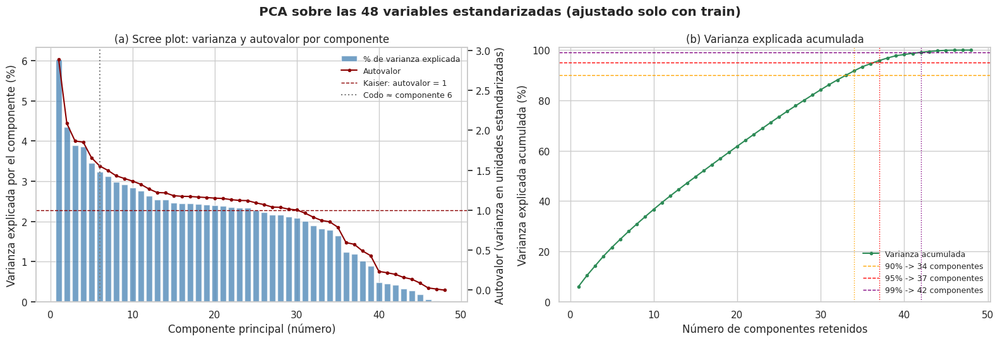

,Criterio,Nº de dimensiones,Varianza retenida (%),Reducción de dimensiones (%)
0,Variables originales (columnas de X),48,100.00,0.00
1,Varianza acumulada ≥ 90%,34,91.75,29.17
2,Varianza acumulada ≥ 95%,37,95.83,22.92
3,Varianza acumulada ≥ 99%,42,99.11,12.50
4,Kaiser (autovalor > 1),30,84.24,37.50
5,Codo del scree plot,6,24.82,87.50


**Interpretación automática (scree plot y varianza acumulada):**
- PC1 explica **6.0%** de la varianza y PC1+PC2 **10.4%**: la varianza está muy repartida entre muchas direcciones; es lo típico cuando hay muchas variables dummy casi independientes entre sí, por lo que PCA comprime poco sin perder información.
- Para conservar 90% / 95% / 99% de la varianza se necesitan **34 / 37 / 42** de 48 dimensiones
  (reducción de 29% / 23% / 12%).
- Kaiser (autovalor > 1, válido porque los datos están estandarizados y cada variable aporta varianza 1) sugiere **30** componentes;
  el codo del scree plot aparece en el componente **6**.
- Estos criterios solo miran la varianza de `X`; no dicen si esa varianza sirve para predecir el tiempo. Por eso la decisión final se toma con la curva empírica de la siguiente celda.

In [13]:
# [P1-C1] PCA completo sobre train: scree plot, varianza acumulada y tabla de criterios
pca_completo = PCA(n_components=None, random_state=SEED).fit(X_train_esc)
var_ratio = pca_completo.explained_variance_ratio_
var_acum = np.cumsum(var_ratio)
autovalores = pca_completo.explained_variance_
n_comp_total = len(var_ratio)

def k_para_umbral(umbral):
    return int(min(np.searchsorted(var_acum, umbral) + 1, n_comp_total))

k_90, k_95, k_99 = k_para_umbral(0.90), k_para_umbral(0.95), k_para_umbral(0.99)
k_kaiser = int((autovalores > 1).sum())
k_codo = detectar_codo(range(1, n_comp_total + 1), autovalores)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
componentes = np.arange(1, n_comp_total + 1)
ax = axes[0]
ax.bar(componentes, var_ratio * 100, color='steelblue', alpha=0.75, label='% de varianza explicada')
ax.set_xlabel('Componente principal (número)')
ax.set_ylabel('Varianza explicada por el componente (%)')
ax2 = ax.twinx()
ax2.plot(componentes, autovalores, color='darkred', marker='o', ms=3, label='Autovalor')
ax2.axhline(1, color='darkred', ls='--', lw=1, label='Kaiser: autovalor = 1')
ax2.axvline(k_codo, color='gray', ls=':', lw=1.5, label=f'Codo ≈ componente {k_codo}')
ax2.set_ylabel('Autovalor (varianza en unidades estandarizadas)')
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9)
ax.set_title('(a) Scree plot: varianza y autovalor por componente')

ax = axes[1]
ax.plot(componentes, var_acum * 100, marker='o', ms=3, color='seagreen', label='Varianza acumulada')
for umbral, k_u, color in [(90, k_90, 'orange'), (95, k_95, 'red'), (99, k_99, 'purple')]:
    ax.axhline(umbral, color=color, ls='--', lw=1, label=f'{umbral}% -> {k_u} componentes')
    ax.axvline(k_u, color=color, ls=':', lw=1)
ax.set_xlabel('Número de componentes retenidos')
ax.set_ylabel('Varianza explicada acumulada (%)')
ax.set_ylim(0, 101)
ax.set_title('(b) Varianza explicada acumulada')
ax.legend(loc='lower right', fontsize=9)
plt.suptitle(f'PCA sobre las {N_FEATURES} variables estandarizadas (ajustado solo con train)', fontweight='bold')
plt.tight_layout()
plt.show()

tabla_criterios_pca = pd.DataFrame({
    'Criterio': ['Variables originales (columnas de X)', 'Varianza acumulada ≥ 90%',
                 'Varianza acumulada ≥ 95%', 'Varianza acumulada ≥ 99%',
                 'Kaiser (autovalor > 1)', 'Codo del scree plot'],
    'Nº de dimensiones': [N_FEATURES, k_90, k_95, k_99, k_kaiser, k_codo],
})
tabla_criterios_pca['Varianza retenida (%)'] = [100.0] + [var_acum[k - 1] * 100 for k in
                                                         tabla_criterios_pca['Nº de dimensiones'][1:]]
tabla_criterios_pca['Reducción de dimensiones (%)'] = 100 * (1 - tabla_criterios_pca['Nº de dimensiones'] / N_FEATURES)
display(tabla_criterios_pca.round(2))

reparto = ('la varianza está muy repartida entre muchas direcciones; es lo típico cuando hay muchas '
           'variables dummy casi independientes entre sí, por lo que PCA comprime poco sin perder información'
           if var_ratio[0] < 0.15 else
           'hay pocas direcciones dominantes, por lo que PCA puede comprimir bastante')
nota(f"""**Interpretación automática (scree plot y varianza acumulada):**
- PC1 explica **{var_ratio[0]*100:.1f}%** de la varianza y PC1+PC2 **{var_acum[1]*100:.1f}%**: {reparto}.
- Para conservar 90% / 95% / 99% de la varianza se necesitan **{k_90} / {k_95} / {k_99}** de {N_FEATURES} dimensiones
  (reducción de {100*(1-k_90/N_FEATURES):.0f}% / {100*(1-k_95/N_FEATURES):.0f}% / {100*(1-k_99/N_FEATURES):.0f}%).
- Kaiser (autovalor > 1, válido porque los datos están estandarizados y cada variable aporta varianza 1) sugiere **{k_kaiser}** componentes;
  el codo del scree plot aparece en el componente **{k_codo}**.
- Estos criterios solo miran la varianza de `X`; no dicen si esa varianza sirve para predecir el tiempo. Por eso la decisión final se toma con la curva empírica de la siguiente celda.""")

Random Forest: curva lista (611 s acumulados)
SVR: curva lista (795 s acumulados)


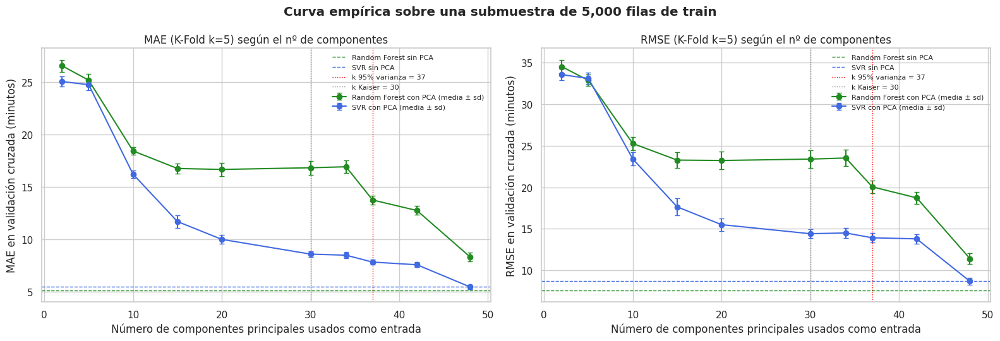

Tabla de la curva (minutos). Referencia sin PCA en la misma submuestra: {'MAE CV Random Forest': np.float64(5.179), 'MAE CV SVR': np.float64(5.482), 'RMSE CV Random Forest': np.float64(7.625), 'RMSE CV SVR': np.float64(8.69)}


Modelo,MAE CV Random Forest,MAE CV SVR,RMSE CV Random Forest,RMSE CV SVR,Varianza retenida (%),Ratio MAE vs mejor con PCA
k,,,,,,
2,26.52,25.02,34.51,33.55,10.38,3.87
5,25.15,24.73,32.85,33.09,21.58,3.76
10,18.43,16.21,25.27,23.40,36.68,2.58
15,16.76,11.71,23.27,17.64,49.63,2.07
20,16.66,10.01,23.22,15.51,61.77,1.91
30,16.82,8.61,23.39,14.42,84.24,1.79
34,16.92,8.51,23.52,14.51,91.75,1.79
37,13.76,7.85,20.05,13.93,95.83,1.54
42,12.76,7.60,18.73,13.79,99.11,1.46


**Interpretación automática (curva empírica):**
- Con 2 componentes el MAE de Random Forest es 26.53 min y el de SVR
  25.02 min, frente a 5.18 y
  5.48 min sin PCA: con muy pocas componentes se pierde la información predictiva.
- **Elección: K_PCA = 42 componentes** (99.1% de la varianza; 12% menos dimensiones).
  Regla: ningún k < total cumple la tolerancia; se usa el umbral de varianza (99% o 95%).
- Frente a no usar PCA, con K_PCA el MAE en CV cambia +146.3% (Random Forest) y +38.6% (SVR).
- Criterios combinados: varianza (95% -> 37), Kaiser (30), codo (6) y desempeño empírico (42).
  Se prioriza el criterio empírico porque mide directamente la pérdida de capacidad predictiva; los criterios de varianza sirven como contexto.

In [14]:
# [P1-C2] Curva empírica: nº de componentes vs MAE/RMSE en validación cruzada (K-Fold k=5)
idx_curva = indices_submuestra(len(Xtr), CURVA_N_SUB)
X_curva, y_curva = Xtr[idx_curva], ytr[idx_curva]
candidatos_k = sorted({k for k in [2, 5, 10, 15, 20, 30, k_90, k_95, k_99, N_FEATURES] if 1 <= k <= N_FEATURES})
MODELOS_CURVA = ['Random Forest', 'SVR']   # una familia basada en árboles y una basada en distancias/kernel

filas_curva, ref_curva = [], {}
t0_curva = time.perf_counter()
for nombre_modelo in MODELOS_CURVA:
    cv_ref = validacion_cruzada(nombre_modelo, X_curva, y_curva, None)
    ref_curva[nombre_modelo] = {'MAE': cv_ref['MAE'].mean(), 'RMSE': cv_ref['RMSE'].mean()}
    for k in candidatos_k:
        cv_k = validacion_cruzada(nombre_modelo, X_curva, y_curva, k)
        filas_curva.append({'Modelo': nombre_modelo, 'k': k,
                            'MAE': cv_k['MAE'].mean(), 'MAE_sd': cv_k['MAE'].std(),
                            'RMSE': cv_k['RMSE'].mean(), 'RMSE_sd': cv_k['RMSE'].std(),
                            'Varianza retenida (%)': var_acum[k - 1] * 100})
    print(f'{nombre_modelo}: curva lista ({time.perf_counter() - t0_curva:.0f} s acumulados)')
curva_pca = pd.DataFrame(filas_curva)

colores_curva = {'Random Forest': 'forestgreen', 'SVR': 'royalblue'}
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, metrica in zip(axes, ['MAE', 'RMSE']):
    for nombre_modelo in MODELOS_CURVA:
        sub = curva_pca[curva_pca['Modelo'] == nombre_modelo]
        ax.errorbar(sub['k'], sub[metrica], yerr=sub[f'{metrica}_sd'], marker='o', capsize=3,
                    color=colores_curva[nombre_modelo], label=f'{nombre_modelo} con PCA (media ± sd)')
        ax.axhline(ref_curva[nombre_modelo][metrica], color=colores_curva[nombre_modelo], ls='--', lw=1,
                   label=f'{nombre_modelo} sin PCA')
    ax.axvline(k_95, color='red', ls=':', lw=1, label=f'k 95% varianza = {k_95}')
    ax.axvline(k_kaiser, color='gray', ls=':', lw=1, label=f'k Kaiser = {k_kaiser}')
    ax.set_xlabel('Número de componentes principales usados como entrada')
    ax.set_ylabel(f'{metrica} en validación cruzada (minutos)')
    ax.set_title(f'{metrica} (K-Fold k={N_SPLITS}) según el nº de componentes')
    ax.legend(fontsize=8)
plt.suptitle(f'Curva empírica sobre una submuestra de {len(X_curva):,} filas de train', fontweight='bold')
plt.tight_layout()
plt.show()

# ---- Regla de elección: el menor k cuyo MAE medio (promedio de los 2 modelos, relativo al mejor
# MAE alcanzado con PCA por cada modelo) esté a no más de TOLERANCIA del óptimo y que realmente comprima.
TOLERANCIA = 0.05
pivote_mae = curva_pca.pivot(index='k', columns='Modelo', values='MAE')
ratio_medio = (pivote_mae / pivote_mae.min()).mean(axis=1)
aceptables = ratio_medio[(ratio_medio <= 1 + TOLERANCIA) & (ratio_medio.index < N_FEATURES)]
if len(aceptables):
    K_PCA = int(aceptables.index.min())
    regla_k = (f'menor k con MAE medio a ≤ {TOLERANCIA:.0%} del mejor MAE obtenido con PCA '
               f'(ratio = {ratio_medio.loc[K_PCA]:.3f})')
else:
    K_PCA = int(k_99 if k_99 < N_FEATURES else k_95)
    regla_k = 'ningún k < total cumple la tolerancia; se usa el umbral de varianza (99% o 95%)'

tabla_curva = pivote_mae.add_prefix('MAE CV ').join(
    curva_pca.pivot(index='k', columns='Modelo', values='RMSE').add_prefix('RMSE CV '))
tabla_curva['Varianza retenida (%)'] = [var_acum[k - 1] * 100 for k in tabla_curva.index]
tabla_curva['Ratio MAE vs mejor con PCA'] = ratio_medio
fila_ref = {f'MAE CV {m}': ref_curva[m]['MAE'] for m in MODELOS_CURVA}
fila_ref.update({f'RMSE CV {m}': ref_curva[m]['RMSE'] for m in MODELOS_CURVA})
print('Tabla de la curva (minutos). Referencia sin PCA en la misma submuestra:',
      {k: round(v, 3) for k, v in fila_ref.items()})
display(tabla_curva.round(3))

degradacion = {m: 100 * (pivote_mae.loc[K_PCA, m] / ref_curva[m]['MAE'] - 1) for m in MODELOS_CURVA}
nota(f"""**Interpretación automática (curva empírica):**
- Con 2 componentes el MAE de Random Forest es {pivote_mae.loc[candidatos_k[0], 'Random Forest']:.2f} min y el de SVR
  {pivote_mae.loc[candidatos_k[0], 'SVR']:.2f} min, frente a {ref_curva['Random Forest']['MAE']:.2f} y
  {ref_curva['SVR']['MAE']:.2f} min sin PCA: con muy pocas componentes se pierde la información predictiva.
- **Elección: K_PCA = {K_PCA} componentes** ({var_acum[K_PCA-1]*100:.1f}% de la varianza; {100*(1-K_PCA/N_FEATURES):.0f}% menos dimensiones).
  Regla: {regla_k}.
- Frente a no usar PCA, con K_PCA el MAE en CV cambia {degradacion['Random Forest']:+.1f}% (Random Forest) y {degradacion['SVR']:+.1f}% (SVR).
- Criterios combinados: varianza (95% -> {k_95}), Kaiser ({k_kaiser}), codo ({k_codo}) y desempeño empírico ({K_PCA}).
  Se prioriza el criterio empírico porque mide directamente la pérdida de capacidad predictiva; los criterios de varianza sirven como contexto.""")

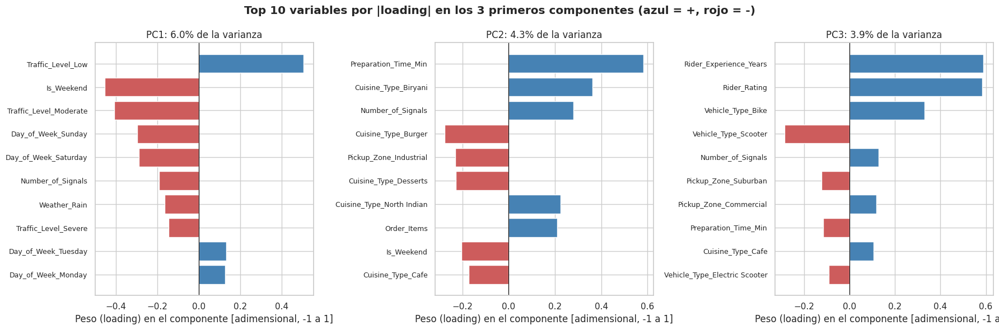

Aporte (%) de cada grupo de variables a cada componente:


,PC1,PC2,PC3
Tráfico y vía,48.00,7.90,1.80
Calendario y hora,44.90,9.00,0.40
Clima,3.80,0.00,0.10
Zonas,1.70,6.70,3.30
Restaurante y pedido,1.60,75.60,5.60
Vehículo,0.00,0.30,19.80
Distancia,0.00,0.10,0.00
Repartidor,0.00,0.40,68.90
Prioridad,0.00,0.00,0.00


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Correlación con Time_taken_min,-0.27,0.17,-0.14,0.01,-0.01,0.11,-0.20,0.53,0.09,0.05


**Interpretación automática de los loadings:**
- **PC1** (6.0% de varianza; corr. con el tiempo = -0.27): dominado por **Tráfico y vía** (48% del peso). Variables principales: `Traffic_Level_Low` (+0.51), `Is_Weekend` (-0.45), `Traffic_Level_Moderate` (-0.41), `Day_of_Week_Sunday` (-0.30).
- **PC2** (4.3% de varianza; corr. con el tiempo = +0.18): dominado por **Restaurante y pedido** (76% del peso). Variables principales: `Preparation_Time_Min` (+0.58), `Cuisine_Type_Biryani` (+0.36), `Number_of_Signals` (+0.28), `Cuisine_Type_Burger` (-0.28).
- **PC3** (3.9% de varianza; corr. con el tiempo = -0.13): dominado por **Repartidor** (69% del peso). Variables principales: `Rider_Experience_Years` (+0.59), `Rider_Rating` (+0.58), `Vehicle_Type_Bike` (+0.33), `Vehicle_Type_Scooter` (-0.28).
- El componente más correlacionado con el tiempo de entrega es **PC8**
(r = +0.53). PCA es **no supervisado**: ordena por varianza de `X`, no por relación con `y`,
así que un componente de poca varianza puede ser muy útil para predecir y uno de mucha varianza puede ser irrelevante.
- Los signos son arbitrarios (multiplicar un componente por -1 da la misma solución): lo que importa es qué variables se mueven juntas y en qué sentido relativo.

In [15]:
# [P1-C3] Loadings (pesos) de PC1-PC3 e interpretación de negocio
GRUPOS_NEGOCIO = {
    'Road_Distance_km': 'Distancia', 'Delivery_Distance_Category': 'Distancia',
    'Vehicle_Type': 'Vehículo',
    'Traffic_Level': 'Tráfico y vía', 'Number_of_Signals': 'Tráfico y vía',
    'Weather': 'Clima',
    'Preparation_Time_Min': 'Restaurante y pedido', 'Restaurant_Load': 'Restaurante y pedido',
    'Restaurant_Rating': 'Restaurante y pedido', 'Order_Items': 'Restaurante y pedido',
    'Cuisine_Type': 'Restaurante y pedido',
    'Rider_Experience_Years': 'Repartidor', 'Rider_Rating': 'Repartidor',
    'Day_of_Week': 'Calendario y hora', 'Is_Weekend': 'Calendario y hora',
    'Is_Festival': 'Calendario y hora', 'Order_Hour': 'Calendario y hora',
    'Pickup_Zone': 'Zonas', 'Dropoff_Zone': 'Zonas',
    'Delivery_Priority': 'Prioridad',
}

def grupo_negocio(columna):
    for base, grupo in GRUPOS_NEGOCIO.items():
        if columna == base or columna.startswith(f'{base}_'):
            return grupo
    return 'Otras'

N_PC_INTERPRETAR = 3
nombres_pc = [f'PC{i}' for i in range(1, N_PC_INTERPRETAR + 1)]
cargas = pd.DataFrame(pca_completo.components_[:N_PC_INTERPRETAR].T, index=NOMBRES_FEATURES, columns=nombres_pc)

fig, axes = plt.subplots(1, N_PC_INTERPRETAR, figsize=(18, 6))
for ax, pc in zip(axes, nombres_pc):
    top = cargas[pc].reindex(cargas[pc].abs().sort_values(ascending=False).index).head(10)[::-1]
    ax.barh(top.index, top.values, color=['indianred' if v < 0 else 'steelblue' for v in top.values])
    ax.axvline(0, color='black', lw=0.8)
    i_pc = int(pc[2:]) - 1
    ax.set_title(f'{pc}: {var_ratio[i_pc]*100:.1f}% de la varianza')
    ax.set_xlabel('Peso (loading) en el componente [adimensional, -1 a 1]')
    ax.tick_params(axis='y', labelsize=9)
plt.suptitle('Top 10 variables por |loading| en los 3 primeros componentes (azul = +, rojo = -)', fontweight='bold')
plt.tight_layout()
plt.show()

# Aporte de cada grupo de negocio a cada componente (suma de loadings² = 1 por componente)
aporte_grupos = (cargas ** 2).groupby(cargas.index.map(grupo_negocio)).sum() * 100
print('Aporte (%) de cada grupo de variables a cada componente:')
display(aporte_grupos.sort_values('PC1', ascending=False).round(1))

# Correlación de los primeros 10 componentes con el tiempo de entrega (solo train, solo para interpretar)
puntajes_train = pca_completo.transform(X_train_esc)[:, :10]
corr_pc_tiempo = pd.Series([np.corrcoef(puntajes_train[:, i], ytr)[0, 1] for i in range(puntajes_train.shape[1])],
                           index=[f'PC{i}' for i in range(1, puntajes_train.shape[1] + 1)], name='Correlación con Time_taken_min')
display(corr_pc_tiempo.to_frame().T.round(3))

lineas = []
for pc in nombres_pc:
    orden = cargas[pc].abs().sort_values(ascending=False).index[:4]
    variables_txt = ', '.join(f'`{v}` ({cargas.loc[v, pc]:+.2f})' for v in orden)
    grupo_dom = aporte_grupos[pc].idxmax()
    lineas.append(f'- **{pc}** ({var_ratio[int(pc[2:]) - 1]*100:.1f}% de varianza; corr. con el tiempo = {corr_pc_tiempo[pc]:+.2f}): '
                  f'dominado por **{grupo_dom}** ({aporte_grupos.loc[grupo_dom, pc]:.0f}% del peso). Variables principales: {variables_txt}.')
pc_mas_predictivo = corr_pc_tiempo.abs().idxmax()
nota('**Interpretación automática de los loadings:**\n' + '\n'.join(lineas) +
     f"""\n- El componente más correlacionado con el tiempo de entrega es **{pc_mas_predictivo}**
(r = {corr_pc_tiempo[pc_mas_predictivo]:+.2f}). PCA es **no supervisado**: ordena por varianza de `X`, no por relación con `y`,
así que un componente de poca varianza puede ser muy útil para predecir y uno de mucha varianza puede ser irrelevante.
- Los signos son arbitrarios (multiplicar un componente por -1 da la misma solución): lo que importa es qué variables se mueven juntas y en qué sentido relativo.""")

### Interpretación del Paso 1 y limitaciones de PCA en este problema

- **Elección del número de componentes.** Se combinan cuatro criterios: umbral de varianza acumulada (90/95/99%), Kaiser, codo del *scree plot* y, sobre todo, la curva empírica de error en validación cruzada. El número elegido (`K_PCA`, impreso arriba) es el menor que mantiene el error cerca del mejor alcanzable con PCA: es el equilibrio entre **compresión** (menos dimensiones, menos multicolinealidad, entrenamiento más rápido) y **pérdida de desempeño**.
- **Lectura de negocio de los componentes.** La tabla de aporte por grupo indica qué "tema" resume cada componente (distancia, tráfico, calendario, restaurante...). Un componente dominado por los *dummies* de un mismo grupo (por ejemplo, los días de la semana o `Is_Weekend`) refleja que esas columnas son mutuamente excluyentes y por eso se correlacionan negativamente entre sí.
- **Limitaciones:**
  1. **Linealidad:** PCA solo capta relaciones lineales (covarianzas). La interacción distancia × tráfico × vehículo, que el EDA mostró importante, no queda representada en un único componente.
  2. **Variables *one-hot*:** los *dummies* son binarios, no continuos ni normales. Al estandarizarlos, las categorías raras reciben mucho peso y la varianza se reparte en muchas direcciones, por eso hacen falta muchos componentes para el 95%.
  3. **No supervisado:** maximiza varianza de `X`, no la relación con `Time_taken_min`.
  4. **Interpretabilidad:** cada componente mezcla todas las variables, por lo que ya no se puede decir "el tráfico alto añade X minutos".
- **Alternativas:** `TruncatedSVD` (trabaja con matrices dispersas sin centrar, útil con muchos *dummies*), **MCA** (análisis de correspondencias múltiples, para categóricas) o **FAMD** (datos mixtos numéricos + categóricos, librería `prince`), o aplicar PCA **solo a las variables numéricas** y concatenar las categóricas; también la **selección de variables** (importancias, permutación) conserva la interpretabilidad.

## PASO 2. Comparación supervisada: con vs. sin reducción de dimensionalidad

Se usan **exactamente** los mismos modelos, hiperparámetros, partición y métricas que en la referencia. Lo único que cambia es la entrada: `K_PCA` componentes principales en lugar de las variables originales. El PCA se ajusta solo con train (dentro de cada *fold* en la validación cruzada).

- El **SVR** se entrena con una submuestra de 10.000 filas en ambos escenarios (con y sin PCA) porque su costo crece de forma cuadrática-cúbica con el número de filas; se evalúa sobre el test **completo**.
- Además del test, se hace **K-Fold (k=5)** sobre una submuestra de train para reportar media ± desviación estándar y verificar si la diferencia con/sin PCA es mayor que el ruido de la validación (prueba *t* pareada, porque ambos escenarios usan los mismos *folds*).

Entrenando Decision Tree con PCA (42 componentes)... MAE = 9.98 min | RMSE = 15.62 min | 4.4 s
Entrenando Random Forest con PCA (42 componentes)... MAE = 6.96 min | RMSE = 10.60 min | 246.1 s
Entrenando SVR con PCA (42 componentes)... MAE = 5.88 min | RMSE = 10.28 min | 65.8 s
Entrenando Red Neuronal con PCA (42 componentes)... MAE = 3.12 min | RMSE = 4.03 min | 53.4 s

=== Comparación en test (10.000 filas no vistas). Δ = con PCA − sin PCA (positivo = PCA empeora) ===


,Nº features sin PCA,Nº features con PCA,MAE sin PCA,MAE con PCA,Δ MAE (min),Δ MAE (%),RMSE sin PCA,RMSE con PCA,Δ RMSE (min),Δ RMSE (%),R² sin PCA,R² con PCA,Tiempo sin PCA (s),Tiempo con PCA (s),Filas de entrenamiento
Modelo,,,,,,,,,,,,,,,
Decision Tree,48,42,4.07,9.98,5.91,145.13,5.55,15.62,10.07,181.32,0.98,0.81,1.78,4.36,40000
Random Forest,48,42,3.05,6.96,3.92,128.46,4.04,10.60,6.56,162.44,0.99,0.91,41.59,246.08,40000
SVR,48,42,4.39,5.88,1.49,33.92,6.82,10.29,3.47,50.89,0.96,0.92,84.45,65.79,10000
Red Neuronal,48,42,2.74,3.12,0.39,14.13,3.55,4.03,0.48,13.45,0.99,0.99,55.29,53.42,40000


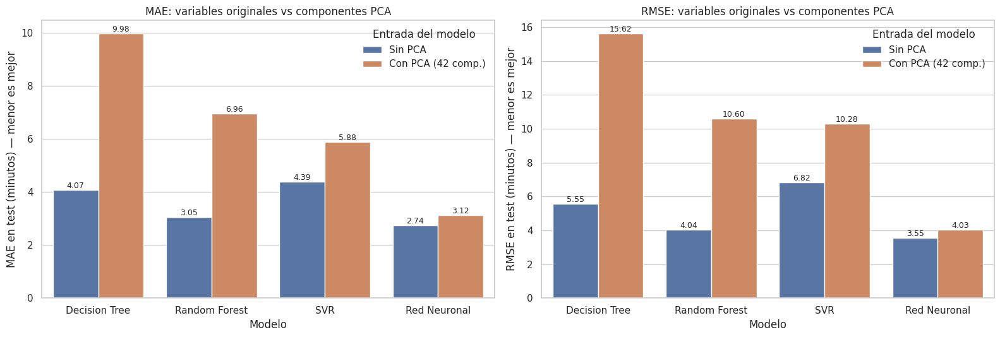

**Interpretación automática (test):** entrada reducida de 48 a 42 dimensiones.
- **Decision Tree**: MAE 4.07 -> 9.98 min (+145.1%), RMSE +181.3%; tiempo 1.8 s -> 4.4 s. PCA **empeora**.
- **Random Forest**: MAE 3.05 -> 6.96 min (+128.5%), RMSE +162.4%; tiempo 41.6 s -> 246.1 s. PCA **empeora**.
- **SVR**: MAE 4.39 -> 5.88 min (+33.9%), RMSE +50.9%; tiempo 84.5 s -> 65.8 s. PCA **empeora**.
- **Red Neuronal**: MAE 2.74 -> 3.12 min (+14.1%), RMSE +13.5%; tiempo 55.3 s -> 53.4 s. PCA **empeora**.
- Criterio usado: |Δ MAE| < 2% se considera neutro. La celda siguiente verifica si las diferencias superan el ruido de la validación cruzada.

In [18]:
# [P2-C1] Entrenamiento con PCA y tabla comparativa en test
resultados_con_pca, predicciones_con_pca = {}, {}
for nombre_modelo in MODELOS:
    print(f'Entrenando {nombre_modelo} con PCA ({K_PCA} componentes)...', end=' ')
    res, pred = ajustar_y_evaluar(nombre_modelo, Xtr, ytr, Xte, yte, n_componentes=K_PCA)
    resultados_con_pca[nombre_modelo], predicciones_con_pca[nombre_modelo] = res, pred
    print(f"MAE = {res['MAE']:.2f} min | RMSE = {res['RMSE']:.2f} min | {res['Tiempo_train_s']:.1f} s")

filas_comp = []
for nombre_modelo in MODELOS:
    s, c = resultados_sin_pca[nombre_modelo], resultados_con_pca[nombre_modelo]
    filas_comp.append({
        'Modelo': nombre_modelo,
        'Nº features sin PCA': s['N_features'], 'Nº features con PCA': c['N_features'],
        'MAE sin PCA': s['MAE'], 'MAE con PCA': c['MAE'],
        'Δ MAE (min)': c['MAE'] - s['MAE'], 'Δ MAE (%)': 100 * (c['MAE'] - s['MAE']) / s['MAE'],
        'RMSE sin PCA': s['RMSE'], 'RMSE con PCA': c['RMSE'],
        'Δ RMSE (min)': c['RMSE'] - s['RMSE'], 'Δ RMSE (%)': 100 * (c['RMSE'] - s['RMSE']) / s['RMSE'],
        'R² sin PCA': s['R2'], 'R² con PCA': c['R2'],
        'Tiempo sin PCA (s)': s['Tiempo_train_s'], 'Tiempo con PCA (s)': c['Tiempo_train_s'],
        'Filas de entrenamiento': s['N_train'],
    })
tabla_comparativa_pca = pd.DataFrame(filas_comp).set_index('Modelo')
print(f'\n=== Comparación en test (10.000 filas no vistas). Δ = con PCA − sin PCA (positivo = PCA empeora) ===')
display(tabla_comparativa_pca.round(3))

# Gráfico de barras agrupadas
datos_barras = []
for nombre_modelo in MODELOS:
    for entrada, dic in [('Sin PCA', resultados_sin_pca), (f'Con PCA ({K_PCA} comp.)', resultados_con_pca)]:
        datos_barras.append({'Modelo': nombre_modelo, 'Entrada': entrada,
                             'MAE': dic[nombre_modelo]['MAE'], 'RMSE': dic[nombre_modelo]['RMSE']})
datos_barras = pd.DataFrame(datos_barras)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, metrica in zip(axes, ['MAE', 'RMSE']):
    sns.barplot(data=datos_barras, x='Modelo', y=metrica, hue='Entrada', palette=['#4C72B0', '#DD8452'], ax=ax)
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fmt='%.2f', fontsize=9)
    ax.set_xlabel('Modelo')
    ax.set_ylabel(f'{metrica} en test (minutos) — menor es mejor')
    ax.set_title(f'{metrica}: variables originales vs componentes PCA')
    ax.legend(title='Entrada del modelo')
plt.tight_layout()
plt.show()

def veredicto(delta_pct, umbral=2.0):
    if delta_pct > umbral:
        return 'empeora'
    if delta_pct < -umbral:
        return 'mejora'
    return 'es prácticamente neutro'

lineas = [f"- **{m}**: MAE {tabla_comparativa_pca.loc[m, 'MAE sin PCA']:.2f} -> {tabla_comparativa_pca.loc[m, 'MAE con PCA']:.2f} min "
          f"({tabla_comparativa_pca.loc[m, 'Δ MAE (%)']:+.1f}%), RMSE {tabla_comparativa_pca.loc[m, 'Δ RMSE (%)']:+.1f}%; "
          f"tiempo {tabla_comparativa_pca.loc[m, 'Tiempo sin PCA (s)']:.1f} s -> {tabla_comparativa_pca.loc[m, 'Tiempo con PCA (s)']:.1f} s. "
          f"PCA **{veredicto(tabla_comparativa_pca.loc[m, 'Δ MAE (%)'])}**." for m in MODELOS]
nota(f'**Interpretación automática (test):** entrada reducida de {N_FEATURES} a {K_PCA} dimensiones.\n' + '\n'.join(lineas) +
     '\n- Criterio usado: |Δ MAE| < 2% se considera neutro. La celda siguiente verifica si las diferencias superan el ruido de la validación cruzada.')

Decision Tree: K-Fold listo en 4 s
Random Forest: K-Fold listo en 242 s
SVR: K-Fold listo en 234 s
Red Neuronal: K-Fold listo en 139 s

=== K-Fold k=5 sobre 10,000 filas de train (minutos) ===


,MAE sin PCA (media),MAE sin PCA (sd),MAE con PCA (media),MAE con PCA (sd),RMSE sin PCA (media),RMSE sin PCA (sd),RMSE con PCA (media),RMSE con PCA (sd),Δ MAE pareado (media),Δ MAE pareado (sd),t pareado,p-valor,¿Diferencia > ruido? (p<0.05)
Modelo,,,,,,,,,,,,,
Decision Tree,5.99,0.05,15.08,1.80,8.62,0.16,22.26,2.79,9.09,1.83,11.10,0.00,True
Random Forest,4.30,0.09,10.85,1.27,6.05,0.16,15.91,2.10,6.55,1.25,11.71,0.00,True
SVR,4.64,0.08,6.22,0.12,7.17,0.19,10.95,0.42,1.58,0.12,28.29,0.00,True
Red Neuronal,4.45,0.34,8.35,3.67,6.38,0.47,12.34,6.24,3.90,3.42,2.55,0.06,False


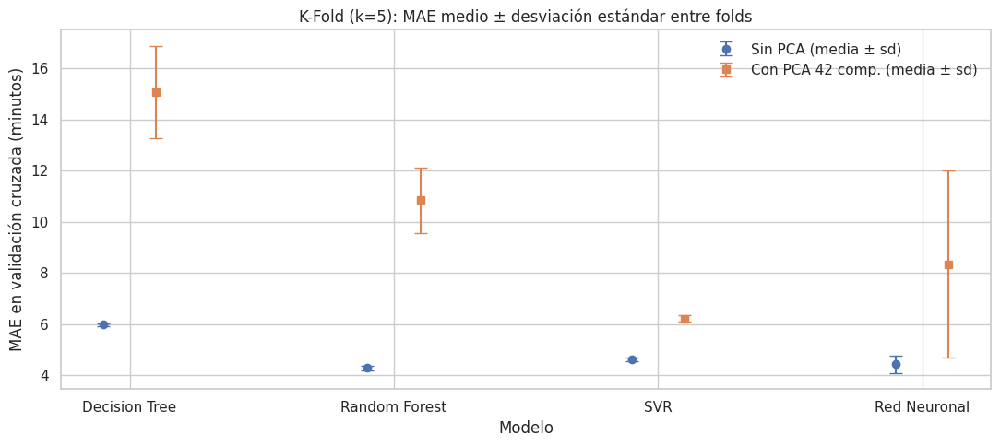

**Interpretación automática (K-Fold):**
- **Decision Tree**: 5.99 ± 0.05 -> 15.08 ± 1.80 min; Δ pareado = +9.09 ± 1.83 (p = 0.000): la diferencia es **mayor que el ruido** de la validación.
- **Random Forest**: 4.30 ± 0.09 -> 10.85 ± 1.27 min; Δ pareado = +6.55 ± 1.25 (p = 0.000): la diferencia es **mayor que el ruido** de la validación.
- **SVR**: 4.64 ± 0.08 -> 6.22 ± 0.13 min; Δ pareado = +1.58 ± 0.12 (p = 0.000): la diferencia es **mayor que el ruido** de la validación.
- **Red Neuronal**: 4.45 ± 0.34 -> 8.35 ± 3.67 min; Δ pareado = +3.90 ± 3.42 (p = 0.063): la diferencia **no supera** el ruido de la validación.
- La prueba es pareada porque ambos escenarios usan los mismos 5 folds; con solo 5 folds el p-valor es orientativo.

In [19]:
# [P2-C2] K-Fold (k=5) pareado en train: media ± desviación estándar y prueba t pareada
idx_cv = indices_submuestra(len(Xtr), CV_N_SUB)
X_cv, y_cv = Xtr[idx_cv], ytr[idx_cv]
filas_cv, cv_detalle = [], {}
for nombre_modelo in MODELOS:
    t0 = time.perf_counter()
    cv_sin = validacion_cruzada(nombre_modelo, X_cv, y_cv, None)
    cv_con = validacion_cruzada(nombre_modelo, X_cv, y_cv, K_PCA)
    cv_detalle[nombre_modelo] = (cv_sin, cv_con)
    dif = cv_con['MAE'].values - cv_sin['MAE'].values
    if np.allclose(dif, 0):
        t_stat, p_valor = 0.0, 1.0
    else:
        t_stat, p_valor = stats.ttest_rel(cv_con['MAE'], cv_sin['MAE'])
    filas_cv.append({
        'Modelo': nombre_modelo,
        'MAE sin PCA (media)': cv_sin['MAE'].mean(), 'MAE sin PCA (sd)': cv_sin['MAE'].std(),
        'MAE con PCA (media)': cv_con['MAE'].mean(), 'MAE con PCA (sd)': cv_con['MAE'].std(),
        'RMSE sin PCA (media)': cv_sin['RMSE'].mean(), 'RMSE sin PCA (sd)': cv_sin['RMSE'].std(),
        'RMSE con PCA (media)': cv_con['RMSE'].mean(), 'RMSE con PCA (sd)': cv_con['RMSE'].std(),
        'Δ MAE pareado (media)': dif.mean(), 'Δ MAE pareado (sd)': dif.std(ddof=1),
        't pareado': t_stat, 'p-valor': p_valor,
        '¿Diferencia > ruido? (p<0.05)': bool(p_valor < 0.05),
    })
    print(f'{nombre_modelo}: K-Fold listo en {time.perf_counter() - t0:.0f} s')
tabla_cv_pca = pd.DataFrame(filas_cv).set_index('Modelo')
print(f'\n=== K-Fold k={N_SPLITS} sobre {len(X_cv):,} filas de train (minutos) ===')
display(tabla_cv_pca.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
posiciones = np.arange(len(MODELOS))
ax.errorbar(posiciones - 0.1, tabla_cv_pca['MAE sin PCA (media)'], yerr=tabla_cv_pca['MAE sin PCA (sd)'],
            fmt='o', capsize=5, color='#4C72B0', label='Sin PCA (media ± sd)')
ax.errorbar(posiciones + 0.1, tabla_cv_pca['MAE con PCA (media)'], yerr=tabla_cv_pca['MAE con PCA (sd)'],
            fmt='s', capsize=5, color='#DD8452', label=f'Con PCA {K_PCA} comp. (media ± sd)')
ax.set_xticks(posiciones)
ax.set_xticklabels(MODELOS)
ax.set_xlabel('Modelo')
ax.set_ylabel('MAE en validación cruzada (minutos)')
ax.set_title(f'K-Fold (k={N_SPLITS}): MAE medio ± desviación estándar entre folds')
ax.legend()
plt.tight_layout()
plt.show()

lineas = []
for m in MODELOS:
    f = tabla_cv_pca.loc[m]
    conclusion = ('la diferencia es **mayor que el ruido** de la validación' if f['¿Diferencia > ruido? (p<0.05)']
                  else 'la diferencia **no supera** el ruido de la validación')
    lineas.append(f"- **{m}**: {f['MAE sin PCA (media)']:.2f} ± {f['MAE sin PCA (sd)']:.2f} -> "
                  f"{f['MAE con PCA (media)']:.2f} ± {f['MAE con PCA (sd)']:.2f} min; Δ pareado = {f['Δ MAE pareado (media)']:+.2f} "
                  f"± {f['Δ MAE pareado (sd)']:.2f} (p = {f['p-valor']:.3f}): {conclusion}.")
nota('**Interpretación automática (K-Fold):**\n' + '\n'.join(lineas) +
     '\n- La prueba es pareada porque ambos escenarios usan los mismos 5 folds; con solo 5 folds el p-valor es orientativo.')

### Interpretación del Paso 2

Cómo leer los resultados (los números concretos están en las interpretaciones automáticas de arriba):

- **Árboles (Decision Tree y Random Forest):** se espera que PCA **empeore** o sea neutro. Los árboles hacen cortes perpendiculares a los ejes ("¿distancia > 15 km?") y ya seleccionan las variables útiles por sí mismos. Al rotar los ejes, una regla simple sobre `Road_Distance_km` o `Traffic_Level` se reparte entre muchos componentes y el árbol necesita más cortes para aproximarla.
- **SVR y red neuronal:** dependen de distancias y del producto punto entre observaciones, por lo que son más sensibles a la dimensionalidad, a la escala y a la multicolinealidad. PCA puede ayudarlos (menos ruido, componentes no correlacionados, entrenamiento más rápido) **siempre que** los componentes descartados no contengan información útil. Si el MAE sube, significa que parte de la señal estaba en direcciones de poca varianza.
- **Qué se gana con PCA:** menos dimensiones, componentes no correlacionados (sin multicolinealidad), entrenamiento potencialmente más rápido y posibilidad de visualizar en 2D.
- **Qué se pierde:** interpretabilidad (el modelo ya no habla de "tráfico" o "distancia", sino de "PC3") e información no lineal o de baja varianza.
- **Ruido de la validación:** si el *p*-valor es mayor que 0,05 la diferencia con/sin PCA no es concluyente; si es menor, el efecto es consistente en todos los *folds*.
- En este dataset las variables ya son pocas (unas 48 tras el *one-hot*) frente a 40.000 filas, así que la maldición de la dimensionalidad no es severa y la ventaja principal de PCA no es predictiva sino de compresión y visualización.

## PASO 3. Aprendizaje no supervisado (clustering)

Objetivo: descubrir **segmentos operativos de entregas sin usar el tiempo de entrega**. `Time_taken_min` no entra en ningún algoritmo de agrupamiento; solo se usa *después* para describir y validar los grupos.

Decisiones:
- Se trabaja con el conjunto de **train** (40.000 filas) ya escalado. Se comparan dos espacios: las variables escaladas completas y el espacio PCA con `K_PCA` componentes.
- **K-Means** (método principal): `init='k-means++'`, `n_init=10` en el barrido y `n_init=20` en el modelo final, `random_state=42`. k se elige entre 2 y 10 con el **codo de la inercia** y el **coeficiente de silueta** (calculado sobre una submuestra de 5.000 puntos porque su costo es O(n²)).
- **Segundo algoritmo:** clustering **aglomerativo** con *linkage* `ward`, `complete` y `average` sobre una submuestra de 5.000 puntos (también O(n²) en memoria).
- Métricas **internas** (silueta, Davies-Bouldin, Calinski-Harabasz) y **externas** contra etiquetas reales (ARI, NMI, homogeneidad, completitud y pureza).

Escalado completo (48 dims): barrido listo (22 s acumulados)
PCA (42 comps): barrido listo (41 s acumulados)


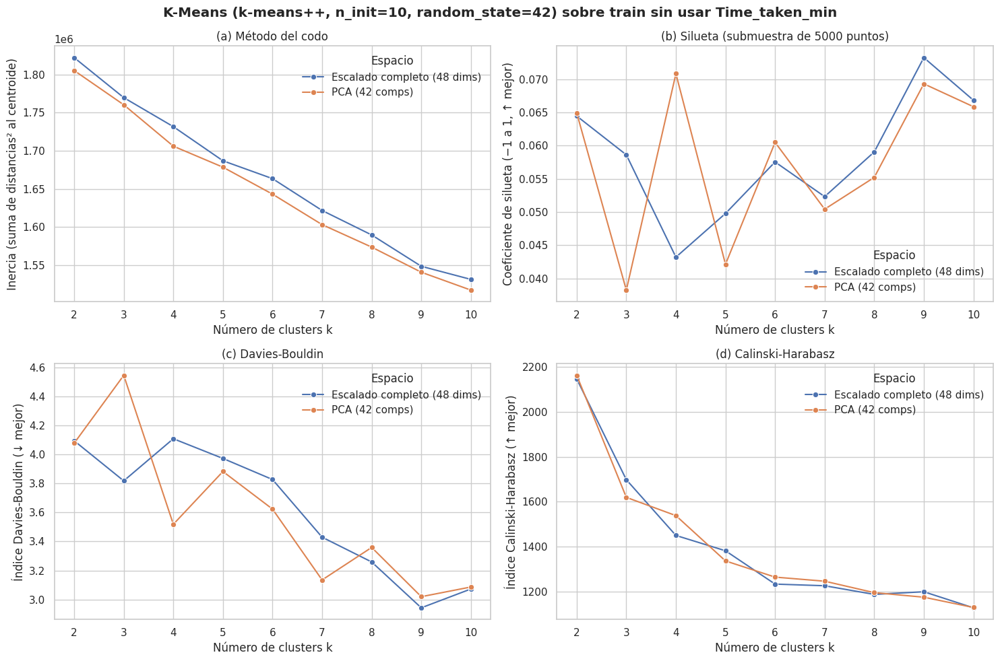

,Espacio,k,Inercia,Silueta,Davies-Bouldin,Calinski-Harabasz,Cluster más pequeño (%)
0,Escalado completo (48 dims),2,1822222.13,0.06,4.09,2146.24,34.87
1,Escalado completo (48 dims),3,1769730.68,0.06,3.82,1698.09,15.96
2,Escalado completo (48 dims),4,1731647.05,0.04,4.11,1450.13,15.95
3,Escalado completo (48 dims),5,1686860.33,0.05,3.97,1381.92,13.90
4,Escalado completo (48 dims),6,1663432.08,0.06,3.83,1233.74,11.62
5,Escalado completo (48 dims),7,1621636.51,0.05,3.43,1226.38,4.74
6,Escalado completo (48 dims),8,1589520.48,0.06,3.26,1187.83,1.07
7,Escalado completo (48 dims),9,1548411.78,0.07,2.94,1199.63,1.07
8,Escalado completo (48 dims),10,1531201.19,0.07,3.07,1128.24,1.07
9,PCA (42 comps),2,1805289.14,0.07,4.08,2162.28,34.87


**Interpretación automática (elección de k):**
- La inercia siempre baja al aumentar k; el codo detectado está en **k = 4**.
- La silueta máxima en el espacio PCA se da en **k = 4** (silueta = 0.071).
  **Se usa k = 4** (criterio: máxima silueta; el codo se reporta como contraste).
- Con k = 4: silueta 0.071 en PCA vs 0.043 en el espacio completo;
  Davies-Bouldin 3.519 vs 4.109.
  Ambos espacios dan resultados distintos:
  se continúa con el espacio PCA (menos dimensiones y menos ruido para la distancia euclidiana).
- Una silueta de 0.071 indica **sin estructura de grupos clara (clusters solapados)** (escala de Kaufman y Rousseeuw: >0,5 fuerte; 0,25-0,5 débil; <0,25 sin estructura sustancial).

In [20]:
# [P3-C1] Barrido de k = 2..10 con K-Means en dos espacios: escalado completo vs PCA
pca_cluster = PCA(n_components=K_PCA, random_state=SEED).fit(X_train_esc)
X_clu_pca = pca_cluster.transform(X_train_esc)
NOMBRE_ESPACIO_FULL = f'Escalado completo ({N_FEATURES} dims)'
NOMBRE_ESPACIO_PCA = f'PCA ({K_PCA} comps)'
ESPACIOS = {NOMBRE_ESPACIO_FULL: X_train_esc, NOMBRE_ESPACIO_PCA: X_clu_pca}
RANGO_K = list(range(2, 11))

filas_barrido, etiquetas_por_k = [], {}
t0 = time.perf_counter()
for espacio, X_esp in ESPACIOS.items():
    for k in RANGO_K:
        km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED).fit(X_esp)
        fila = {'Espacio': espacio, 'k': k, 'Inercia': km.inertia_}
        fila.update(metricas_internas(X_esp, km.labels_, muestra=SIL_N_SUB))
        filas_barrido.append(fila)
        if espacio == NOMBRE_ESPACIO_PCA:
            etiquetas_por_k[k] = km.labels_
    print(f'{espacio}: barrido listo ({time.perf_counter() - t0:.0f} s acumulados)')
barrido_k = pd.DataFrame(filas_barrido)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
paneles = [('Inercia', 'Inercia (suma de distancias² al centroide)', '(a) Método del codo'),
           ('Silueta', 'Coeficiente de silueta (−1 a 1, ↑ mejor)', '(b) Silueta (submuestra de %d puntos)' % SIL_N_SUB),
           ('Davies-Bouldin', 'Índice Davies-Bouldin (↓ mejor)', '(c) Davies-Bouldin'),
           ('Calinski-Harabasz', 'Índice Calinski-Harabasz (↑ mejor)', '(d) Calinski-Harabasz')]
for ax, (columna, etiqueta_y, titulo) in zip(axes.ravel(), paneles):
    sns.lineplot(data=barrido_k, x='k', y=columna, hue='Espacio', marker='o', ax=ax)
    ax.set_xlabel('Número de clusters k')
    ax.set_ylabel(etiqueta_y)
    ax.set_title(titulo)
    ax.set_xticks(RANGO_K)
plt.suptitle('K-Means (k-means++, n_init=10, random_state=42) sobre train sin usar Time_taken_min', fontweight='bold')
plt.tight_layout()
plt.show()

K_CLUSTERS_MANUAL = None   # <- escribe un entero (p. ej. 4) si quieres forzar otro k por interpretabilidad
sub_pca = barrido_k[barrido_k['Espacio'] == NOMBRE_ESPACIO_PCA].set_index('k')
sub_full = barrido_k[barrido_k['Espacio'] == NOMBRE_ESPACIO_FULL].set_index('k')
k_silueta = int(sub_pca['Silueta'].idxmax())
k_codo_kmeans = detectar_codo(sub_pca.index, sub_pca['Inercia'])
K_CLUSTERS = int(K_CLUSTERS_MANUAL) if K_CLUSTERS_MANUAL else k_silueta
display(barrido_k.round(3))

def calidad_silueta(s):
    if s > 0.5:
        return 'estructura fuerte'
    if s > 0.25:
        return 'estructura débil o moderada'
    return 'sin estructura de grupos clara (clusters solapados)'

nota(f"""**Interpretación automática (elección de k):**
- La inercia siempre baja al aumentar k; el codo detectado está en **k = {k_codo_kmeans}**.
- La silueta máxima en el espacio PCA se da en **k = {k_silueta}** (silueta = {sub_pca.loc[k_silueta, 'Silueta']:.3f}).
  **Se usa k = {K_CLUSTERS}** {'(fijado manualmente)' if K_CLUSTERS_MANUAL else '(criterio: máxima silueta; el codo se reporta como contraste)'}.
- Con k = {K_CLUSTERS}: silueta {sub_pca.loc[K_CLUSTERS, 'Silueta']:.3f} en PCA vs {sub_full.loc[K_CLUSTERS, 'Silueta']:.3f} en el espacio completo;
  Davies-Bouldin {sub_pca.loc[K_CLUSTERS, 'Davies-Bouldin']:.3f} vs {sub_full.loc[K_CLUSTERS, 'Davies-Bouldin']:.3f}.
  Ambos espacios dan resultados {'muy parecidos' if abs(sub_pca.loc[K_CLUSTERS, 'Silueta'] - sub_full.loc[K_CLUSTERS, 'Silueta']) < 0.02 else 'distintos'}:
  se continúa con el espacio PCA (menos dimensiones y menos ruido para la distancia euclidiana).
- Una silueta de {sub_pca.loc[K_CLUSTERS, 'Silueta']:.3f} indica **{calidad_silueta(sub_pca.loc[K_CLUSTERS, 'Silueta'])}** (escala de Kaufman y Rousseeuw: >0,5 fuerte; 0,25-0,5 débil; <0,25 sin estructura sustancial).""")

=== Métricas internas con k = 4 sobre la MISMA submuestra de 5,000 puntos (espacio PCA) ===


,Silueta,Davies-Bouldin,Calinski-Harabasz,Cluster más pequeño (%),ARI vs K-Means
Algoritmo,,,,,
"K-Means (k-means++, n_init=20)",0.07,3.49,193.52,13.44,1.00
Aglomerativo (ward),0.04,3.43,123.49,1.02,-0.01
Aglomerativo (complete),0.03,4.35,108.60,0.98,0.05
Aglomerativo (average),0.17,1.75,81.06,0.22,0.01


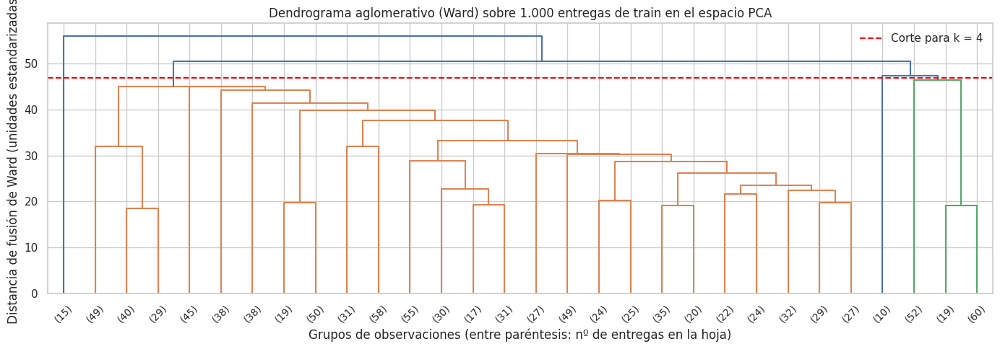

**Interpretación automática (comparación de algoritmos):**
- Mayor silueta: **Aglomerativo (average)** (0.173). K-Means: silueta 0.071,
  Davies-Bouldin 3.489, Calinski-Harabasz 194.
- Ward es el linkage más parecido a K-Means (ARI = -0.012) porque ambos minimizan la varianza intra-cluster.
- `complete` y `average` tienden a crear grupos muy desbalanceados: el cluster más pequeño de **Aglomerativo (average)** tiene solo
  0.22% de los puntos. Una silueta alta con un cluster diminuto suele
  significar que el algoritmo aisló unos pocos puntos extremos, no que encontró segmentos útiles; por eso se revisa siempre el tamaño de los grupos.

In [21]:
# [P3-C2] Modelo final K-Means + segundo algoritmo (aglomerativo con 3 linkages) + dendrograma
kmeans_final = KMeans(n_clusters=K_CLUSTERS, init='k-means++', n_init=20, random_state=SEED).fit(X_clu_pca)
etiquetas_km = kmeans_final.labels_

idx_agg = indices_submuestra(len(X_clu_pca), AGG_N_SUB)
X_agg = X_clu_pca[idx_agg]
etiquetas_km_sub = etiquetas_km[idx_agg]

filas_alg = [{'Algoritmo': 'K-Means (k-means++, n_init=20)', **metricas_internas(X_agg, etiquetas_km_sub),
              'ARI vs K-Means': 1.0}]
etiquetas_agg = {}
for linkage in ['ward', 'complete', 'average']:
    etiquetas_agg[linkage] = AgglomerativeClustering(n_clusters=K_CLUSTERS, linkage=linkage).fit_predict(X_agg)
    filas_alg.append({'Algoritmo': f'Aglomerativo ({linkage})', **metricas_internas(X_agg, etiquetas_agg[linkage]),
                      'ARI vs K-Means': adjusted_rand_score(etiquetas_km_sub, etiquetas_agg[linkage])})
tabla_algoritmos = pd.DataFrame(filas_alg).set_index('Algoritmo')
print(f'=== Métricas internas con k = {K_CLUSTERS} sobre la MISMA submuestra de {len(X_agg):,} puntos (espacio PCA) ===')
display(tabla_algoritmos.round(3))

# Dendrograma (Ward) sobre 1.000 puntos, como en las notas de clase
idx_dendro = indices_submuestra(len(X_clu_pca), 1000)
Z_ward = hierarchy.linkage(X_clu_pca[idx_dendro], method='ward')
altura_corte = (Z_ward[-K_CLUSTERS, 2] + Z_ward[-K_CLUSTERS + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(14, 5))
hierarchy.dendrogram(Z_ward, truncate_mode='lastp', p=30, ax=ax, color_threshold=altura_corte)
ax.axhline(altura_corte, color='red', ls='--', label=f'Corte para k = {K_CLUSTERS}')
ax.set_xlabel('Grupos de observaciones (entre paréntesis: nº de entregas en la hoja)')
ax.set_ylabel('Distancia de fusión de Ward (unidades estandarizadas)')
ax.set_title('Dendrograma aglomerativo (Ward) sobre 1.000 entregas de train en el espacio PCA')
ax.legend()
plt.tight_layout()
plt.show()

mejor_sil = tabla_algoritmos['Silueta'].idxmax()
mas_desbalanceado = tabla_algoritmos['Cluster más pequeño (%)'].idxmin()
nota(f"""**Interpretación automática (comparación de algoritmos):**
- Mayor silueta: **{mejor_sil}** ({tabla_algoritmos.loc[mejor_sil, 'Silueta']:.3f}). K-Means: silueta {tabla_algoritmos.iloc[0]['Silueta']:.3f},
  Davies-Bouldin {tabla_algoritmos.iloc[0]['Davies-Bouldin']:.3f}, Calinski-Harabasz {tabla_algoritmos.iloc[0]['Calinski-Harabasz']:.0f}.
- Ward es el linkage más parecido a K-Means (ARI = {tabla_algoritmos.loc['Aglomerativo (ward)', 'ARI vs K-Means']:.3f}) porque ambos minimizan la varianza intra-cluster.
- `complete` y `average` tienden a crear grupos muy desbalanceados: el cluster más pequeño de **{mas_desbalanceado}** tiene solo
  {tabla_algoritmos.loc[mas_desbalanceado, 'Cluster más pequeño (%)']:.2f}% de los puntos. Una silueta alta con un cluster diminuto suele
  significar que el algoritmo aisló unos pocos puntos extremos, no que encontró segmentos útiles; por eso se revisa siempre el tamaño de los grupos.""")

t-SNE calculado en 61 s sobre 5,000 puntos


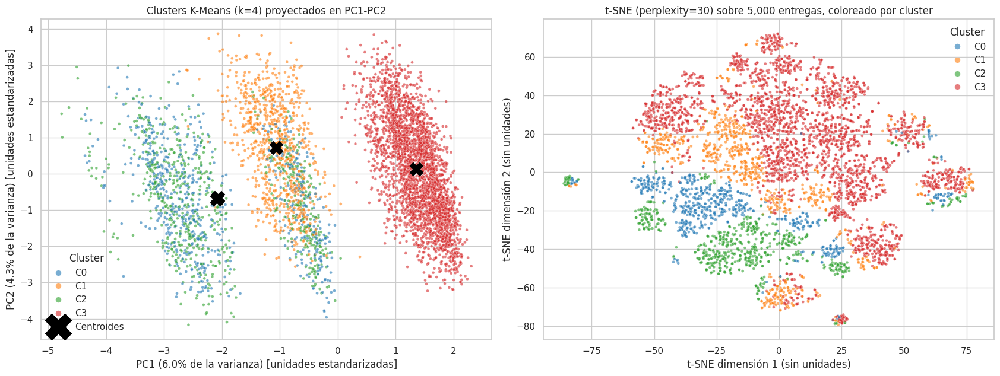

**Interpretación automática (visualización):**
- PC1-PC2 solo resumen el **10.4%** de la varianza, así que la proyección 2D es una "sombra" del espacio de 42 dimensiones:
  clusters que se ven solapados en 2D pueden estar separados en otras direcciones.
- t-SNE preserva vecindarios locales (no distancias globales): si los colores forman islas compactas, los grupos tienen coherencia local;
  si se mezclan, la separación encontrada por K-Means es más una partición del espacio que grupos naturales.
  El tamaño de las islas y la distancia entre ellas en t-SNE **no** se deben interpretar.

In [22]:
# [P3-C3] Visualización de los clusters: proyección PC1-PC2 y t-SNE (submuestra)
idx_vis = indices_submuestra(len(X_clu_pca), TSNE_N_SUB)
etiquetas_vis = np.array([f'C{e}' for e in etiquetas_km[idx_vis]])
orden_hue = [f'C{i}' for i in range(K_CLUSTERS)]

t0 = time.perf_counter()
X_tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(X_clu_pca[idx_vis])
print(f't-SNE calculado en {time.perf_counter() - t0:.0f} s sobre {len(idx_vis):,} puntos')

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.scatterplot(x=X_clu_pca[idx_vis, 0], y=X_clu_pca[idx_vis, 1], hue=etiquetas_vis, hue_order=orden_hue,
                palette='tab10', s=12, alpha=0.6, ax=axes[0])
axes[0].scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1], marker='X', s=250,
                c='black', label='Centroides')
axes[0].set_xlabel(f'PC1 ({var_ratio[0]*100:.1f}% de la varianza) [unidades estandarizadas]')
axes[0].set_ylabel(f'PC2 ({var_ratio[1]*100:.1f}% de la varianza) [unidades estandarizadas]')
axes[0].set_title(f'Clusters K-Means (k={K_CLUSTERS}) proyectados en PC1-PC2')
axes[0].legend(title='Cluster', markerscale=2)

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=etiquetas_vis, hue_order=orden_hue,
                palette='tab10', s=12, alpha=0.6, ax=axes[1])
axes[1].set_xlabel('t-SNE dimensión 1 (sin unidades)')
axes[1].set_ylabel('t-SNE dimensión 2 (sin unidades)')
axes[1].set_title(f't-SNE (perplexity=30) sobre {len(idx_vis):,} entregas, coloreado por cluster')
axes[1].legend(title='Cluster', markerscale=2)
plt.tight_layout()
plt.show()

var_pc12 = var_acum[1] * 100
nota(f"""**Interpretación automática (visualización):**
- PC1-PC2 solo resumen el **{var_pc12:.1f}%** de la varianza, así que la proyección 2D es una "sombra" del espacio de {K_PCA} dimensiones:
  clusters que se ven solapados en 2D pueden estar separados en otras direcciones.
- t-SNE preserva vecindarios locales (no distancias globales): si los colores forman islas compactas, los grupos tienen coherencia local;
  si se mezclan, la separación encontrada por K-Means es más una partición del espacio que grupos naturales.
  El tamaño de las islas y la distancia entre ellas en t-SNE **no** se deben interpretar.""")

=== Perfil numérico por cluster (* el tiempo NO se usó para agrupar; solo describe) ===


,Tamaño (entregas),% del train,Mediana Road_Distance_km,Media Road_Distance_km,Media Preparation_Time_Min,Media Number_of_Signals,Media Order_Items,Media Rider_Experience_Years,Media Rider_Rating,Media Restaurant_Rating,Media Order_Hour,Time_taken_min medio *,Time_taken_min mediano *
Cluster,,,,,,,,,,,,,
C0,5562,13.90,25.32,26.11,24.15,9.76,2.63,4.42,3.95,4.18,13.68,89.88,83.00
C1,6382,15.96,24.98,25.88,25.17,12.59,2.68,4.48,3.96,4.18,15.46,98.42,93.00
C2,5747,14.37,25.61,26.24,23.97,9.78,2.64,4.43,3.95,4.18,13.86,89.25,83.00
C3,22309,55.77,25.86,26.32,23.74,8.89,2.67,4.44,3.95,4.17,13.45,76.81,72.00


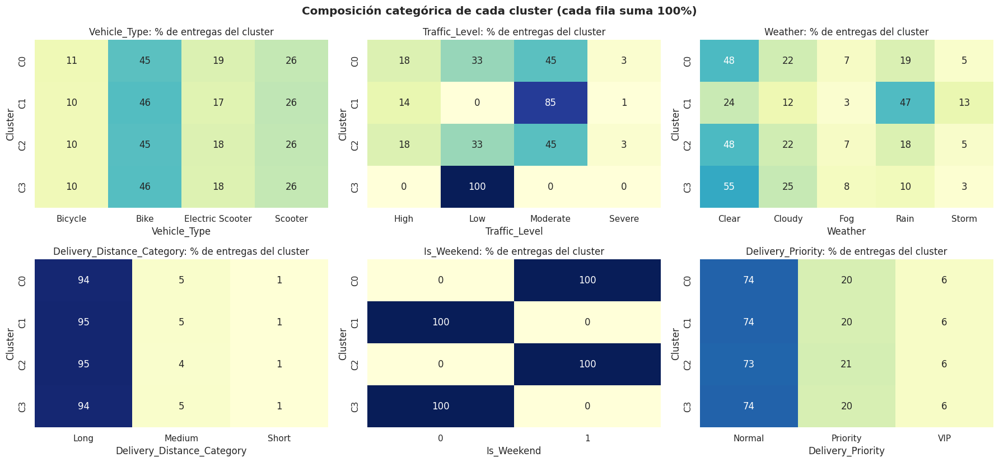

,Nombre de negocio (generado con los datos),Rasgos distintivos del centroide,% del train,Time_taken_min mediano *
C0,Entregas medias (mediana 25.3 km) · Bike (45%) · tráfico Moderate (45%) · fin de semana,"Day_of_Week_Saturday (+2.49 σ), Is_Weekend (+1.59 σ), Traffic_Level_Low (-0.68 σ)",13.90,83.00
C1,Entregas medias (mediana 25.0 km) · Bike (46%) · tráfico Moderate (85%) · entre semana,"Traffic_Level_Moderate (+1.37 σ), Traffic_Level_Low (-1.32 σ), Weather_Rain (+0.76 σ)",16.00,93.00
C2,Entregas medias (mediana 25.6 km) · Bike (45%) · tráfico Moderate (45%) · fin de semana,"Day_of_Week_Sunday (+2.44 σ), Is_Weekend (+1.59 σ), Traffic_Level_Low (-0.69 σ)",14.40,83.00
C3,Entregas medias (mediana 25.9 km) · Bike (46%) · tráfico Low (100%) · entre semana,"Traffic_Level_Low (+0.72 σ), Is_Weekend (-0.63 σ), Traffic_Level_Moderate (-0.60 σ)",55.80,72.00


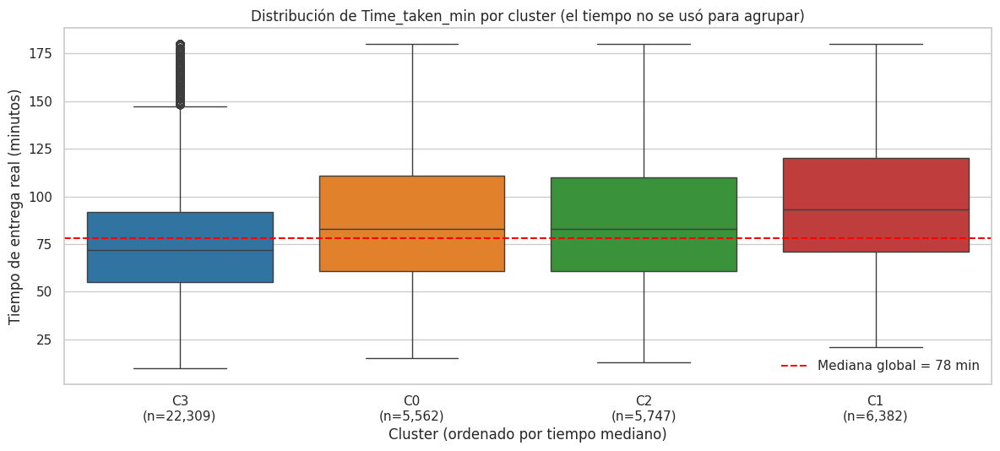

**Interpretación automática (perfiles):**
- **C3** — Entregas medias (mediana 25.9 km) · Bike (46%) · tráfico Low (100%) · entre semana (55.8% de las entregas; tiempo mediano 72 min).
- **C0** — Entregas medias (mediana 25.3 km) · Bike (45%) · tráfico Moderate (45%) · fin de semana (13.9% de las entregas; tiempo mediano 83 min).
- **C2** — Entregas medias (mediana 25.6 km) · Bike (45%) · tráfico Moderate (45%) · fin de semana (14.4% de las entregas; tiempo mediano 83 min).
- **C1** — Entregas medias (mediana 25.0 km) · Bike (46%) · tráfico Moderate (85%) · entre semana (16.0% de las entregas; tiempo mediano 93 min).
- La pertenencia al cluster explica **η² = 5.7%** de la varianza del tiempo de entrega
  (Kruskal-Wallis p = 0). Los clusters apenas separan los tiempos aunque nunca vieron esa variable.
- Los "rasgos distintivos" muestran en cuántas desviaciones estándar se aleja el centroide del promedio: son las variables que realmente definen cada grupo.
  Los nombres de negocio se generan automáticamente con la mediana de distancia (terciles del train), el vehículo y el tráfico dominantes;
  conviene revisarlos y ajustar la redacción final si un rasgo distintivo (p. ej. calendario o zona) es más relevante que la distancia.

In [23]:
# [P3-C4] Perfil de los clusters en lenguaje de negocio + boxplot del tiempo por cluster
df_train_fase = df.loc[X_train_fase.index].copy()
df_train_fase['Cluster'] = [f'C{e}' for e in etiquetas_km]
orden_clusters = [f'C{i}' for i in range(K_CLUSTERS)]

columnas_num_perfil = [c for c in ['Road_Distance_km', 'Preparation_Time_Min', 'Number_of_Signals', 'Order_Items',
                                   'Rider_Experience_Years', 'Rider_Rating', 'Restaurant_Rating', 'Order_Hour']
                       if c in df_train_fase.columns]
grupos_cluster = df_train_fase.groupby('Cluster')
perfil_clusters = pd.DataFrame({'Tamaño (entregas)': grupos_cluster.size(),
                                '% del train': 100 * grupos_cluster.size() / len(df_train_fase)})
perfil_clusters['Mediana Road_Distance_km'] = grupos_cluster['Road_Distance_km'].median()
perfil_clusters = perfil_clusters.join(grupos_cluster[columnas_num_perfil].mean().add_prefix('Media '))
perfil_clusters[f'{TARGET} medio *'] = grupos_cluster[TARGET].mean()
perfil_clusters[f'{TARGET} mediano *'] = grupos_cluster[TARGET].median()
perfil_clusters = perfil_clusters.loc[orden_clusters]
print('=== Perfil numérico por cluster (* el tiempo NO se usó para agrupar; solo describe) ===')
display(perfil_clusters.round(2))

columnas_cat_perfil = [c for c in ['Vehicle_Type', 'Traffic_Level', 'Weather', 'Delivery_Distance_Category',
                                   'Is_Weekend', 'Delivery_Priority'] if c in df_train_fase.columns]
proporciones_cat = {c: pd.crosstab(df_train_fase['Cluster'], df_train_fase[c], normalize='index').loc[orden_clusters] * 100
                    for c in columnas_cat_perfil}
n_filas_fig = int(np.ceil(len(columnas_cat_perfil) / 3))
fig, axes = plt.subplots(n_filas_fig, 3, figsize=(18, 4.2 * n_filas_fig))
for ax, c in zip(np.ravel(axes), columnas_cat_perfil):
    sns.heatmap(proporciones_cat[c], annot=True, fmt='.0f', cmap='YlGnBu', vmin=0, vmax=100, cbar=False, ax=ax)
    ax.set_title(f'{c}: % de entregas del cluster')
    ax.set_xlabel(c)
    ax.set_ylabel('Cluster')
for ax in np.ravel(axes)[len(columnas_cat_perfil):]:
    ax.axis('off')
plt.suptitle('Composición categórica de cada cluster (cada fila suma 100%)', fontweight='bold')
plt.tight_layout()
plt.show()

# Rasgos distintivos: centroide llevado al espacio escalado original (en desviaciones estándar)
centros_esc = pd.DataFrame(pca_cluster.inverse_transform(kmeans_final.cluster_centers_),
                           index=orden_clusters, columns=NOMBRES_FEATURES)
cortes_dist = df_train_fase['Road_Distance_km'].quantile([1 / 3, 2 / 3]).values
prep_media, prep_sd = df_train_fase['Preparation_Time_Min'].mean(), df_train_fase['Preparation_Time_Min'].std()
finde_global = df_train_fase['Is_Weekend'].mean() if 'Is_Weekend' in df_train_fase else np.nan

def nombre_negocio(cluster):
    sub = df_train_fase[df_train_fase['Cluster'] == cluster]
    dist = sub['Road_Distance_km'].median()
    nivel = 'cortas' if dist <= cortes_dist[0] else ('medias' if dist <= cortes_dist[1] else 'largas')
    vehiculo = sub['Vehicle_Type'].value_counts(normalize=True)
    trafico = sub['Traffic_Level'].value_counts(normalize=True)
    partes = [f'Entregas {nivel} (mediana {dist:.1f} km)',
              f'{vehiculo.index[0]} ({vehiculo.iloc[0]*100:.0f}%)',
              f'tráfico {trafico.index[0]} ({trafico.iloc[0]*100:.0f}%)']
    prep = sub['Preparation_Time_Min'].mean()
    if prep > prep_media + 0.4 * prep_sd:
        partes.append('preparación larga')
    elif prep < prep_media - 0.4 * prep_sd:
        partes.append('preparación corta')
    if 'Is_Weekend' in sub:
        finde = sub['Is_Weekend'].mean()
        if finde > min(0.9, finde_global + 0.3):
            partes.append('fin de semana')
        elif finde < finde_global / 3:
            partes.append('entre semana')
    return ' · '.join(partes)

def rasgos_distintivos(cluster, n=3):
    fila = centros_esc.loc[cluster]
    top = fila.reindex(fila.abs().sort_values(ascending=False).index[:n])
    return ', '.join(f'{v} ({z:+.2f} σ)' for v, z in top.items())

tabla_nombres = pd.DataFrame({
    'Nombre de negocio (generado con los datos)': [nombre_negocio(c) for c in orden_clusters],
    'Rasgos distintivos del centroide': [rasgos_distintivos(c) for c in orden_clusters],
    '% del train': perfil_clusters['% del train'].round(1).values,
    f'{TARGET} mediano *': perfil_clusters[f'{TARGET} mediano *'].values,
}, index=orden_clusters)
pd.set_option('display.max_colwidth', 200)
display(tabla_nombres)

# Boxplot del tiempo (variable NO usada) por cluster, ordenado por mediana
orden_tiempo = perfil_clusters[f'{TARGET} mediano *'].sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(data=df_train_fase, x='Cluster', y=TARGET, order=orden_tiempo, palette='tab10', ax=ax, showfliers=True)
ax.axhline(df_train_fase[TARGET].median(), color='red', ls='--', label=f'Mediana global = {df_train_fase[TARGET].median():.0f} min')
ax.set_xticklabels([f'{c}\n(n={perfil_clusters.loc[c, "Tamaño (entregas)"]:,})' for c in orden_tiempo])
ax.set_xlabel('Cluster (ordenado por tiempo mediano)')
ax.set_ylabel('Tiempo de entrega real (minutos)')
ax.set_title('Distribución de Time_taken_min por cluster (el tiempo no se usó para agrupar)')
ax.legend()
plt.tight_layout()
plt.show()

# Proporción de la varianza del tiempo explicada por la pertenencia al cluster (eta²)
media_global = df_train_fase[TARGET].mean()
ss_entre = (grupos_cluster.size() * (grupos_cluster[TARGET].mean() - media_global) ** 2).sum()
ss_total = ((df_train_fase[TARGET] - media_global) ** 2).sum()
eta2_tiempo = ss_entre / ss_total
kruskal = stats.kruskal(*[g[TARGET].values for _, g in df_train_fase.groupby('Cluster')])

lineas = [f"- **{c}** — {tabla_nombres.loc[c, 'Nombre de negocio (generado con los datos)']} "
          f"({tabla_nombres.loc[c, '% del train']:.1f}% de las entregas; tiempo mediano {tabla_nombres.loc[c, f'{TARGET} mediano *']:.0f} min)."
          for c in orden_tiempo]
nota('**Interpretación automática (perfiles):**\n' + '\n'.join(lineas) + f"""
- La pertenencia al cluster explica **η² = {eta2_tiempo*100:.1f}%** de la varianza del tiempo de entrega
  (Kruskal-Wallis p = {kruskal.pvalue:.2g}). Los clusters {'sí separan' if eta2_tiempo > 0.1 else 'apenas separan'} los tiempos aunque nunca vieron esa variable.
- Los "rasgos distintivos" muestran en cuántas desviaciones estándar se aleja el centroide del promedio: son las variables que realmente definen cada grupo.
  Los nombres de negocio se generan automáticamente con la mediana de distancia (terciles del train), el vehículo y el tráfico dominantes;
  conviene revisarlos y ajustar la redacción final si un rasgo distintivo (p. ej. calendario o zona) es más relevante que la distancia.""")

=== Métricas externas: clusters K-Means vs etiquetas reales (train) ===


,¿Se usó para agrupar?,Nº de clases,ARI,NMI,Homogeneidad,Completitud,Pureza,Pureza de referencia (clase mayoritaria)
Etiqueta de referencia,,,,,,,,
Categoría de tiempo,No,4,0.06,0.02,0.02,0.02,0.54,0.54
Cuartil de tiempo,No,4,0.02,0.02,0.02,0.02,0.32,0.26
Vehicle_Type,Sí (como dummies),4,0.00,0.00,0.00,0.00,0.46,0.46
Traffic_Level,Sí (como dummies),4,0.62,0.47,0.55,0.41,0.82,0.65


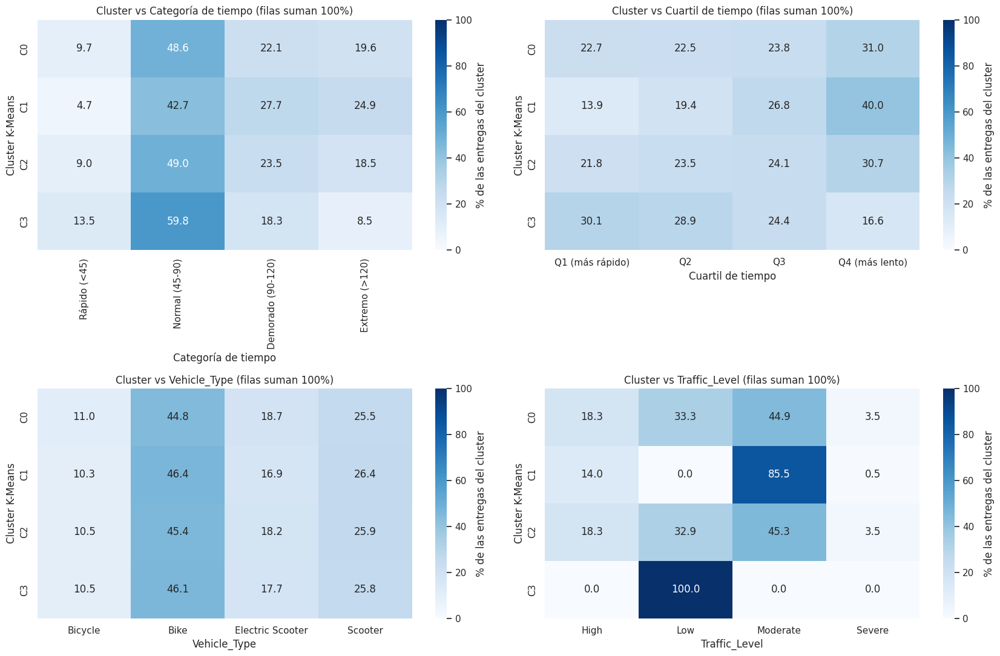

**Interpretación automática (validación externa):**
- Frente a la **categoría de tiempo** (no usada para agrupar): ARI = 0.055, NMI = 0.024,
  pureza = 0.539 vs 0.539 si se asignara siempre la clase mayoritaria.
  Los clusters casi no reflejan las categorías de tiempo.
- La etiqueta que mejor coincide con los clusters es **Traffic_Level** (NMI = 0.466).
  Si es una variable de entrada (Vehicle_Type o Traffic_Level), significa que K-Means se organizó alrededor de esa variable, lo cual es esperable pero no es una validación independiente.
- ARI ≈ 0 equivale a un acuerdo aleatorio; 1 es acuerdo perfecto. La pureza siempre debe compararse con la pureza de referencia porque, con clases desbalanceadas, es alta aunque los clusters no aporten nada.
- Homogeneidad alta = cada cluster contiene una sola clase; completitud alta = cada clase cae en un solo cluster.

In [24]:
# [P3-C5] Contraste con etiquetas reales: crosstabs, ARI, NMI, homogeneidad, completitud y pureza
bins_tiempo = [0, 45, 90, 120, np.inf]
etiquetas_tiempo = ['Rápido (<45)', 'Normal (45-90)', 'Demorado (90-120)', 'Extremo (>120)']
etiquetas_reales = {
    'Categoría de tiempo': pd.cut(df_train_fase[TARGET], bins=bins_tiempo, labels=etiquetas_tiempo),
    'Cuartil de tiempo': pd.qcut(df_train_fase[TARGET], q=4, labels=['Q1 (más rápido)', 'Q2', 'Q3', 'Q4 (más lento)']),
    'Vehicle_Type': df_train_fase['Vehicle_Type'],
    'Traffic_Level': df_train_fase['Traffic_Level'],
}
filas_ext = []
for nombre_etiqueta, reales in etiquetas_reales.items():
    reales_txt = reales.astype(str).values
    filas_ext.append({
        'Etiqueta de referencia': nombre_etiqueta,
        '¿Se usó para agrupar?': 'No' if 'tiempo' in nombre_etiqueta else 'Sí (como dummies)',
        'Nº de clases': int(pd.Series(reales_txt).nunique()),
        'ARI': adjusted_rand_score(reales_txt, etiquetas_km),
        'NMI': normalized_mutual_info_score(reales_txt, etiquetas_km),
        'Homogeneidad': homogeneity_score(reales_txt, etiquetas_km),
        'Completitud': completeness_score(reales_txt, etiquetas_km),
        'Pureza': pureza(reales_txt, etiquetas_km),
        'Pureza de referencia (clase mayoritaria)': pd.Series(reales_txt).value_counts(normalize=True).iloc[0],
    })
tabla_externas = pd.DataFrame(filas_ext).set_index('Etiqueta de referencia')
print('=== Métricas externas: clusters K-Means vs etiquetas reales (train) ===')
display(tabla_externas.round(3))

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
for ax, (nombre_etiqueta, reales) in zip(axes.ravel(), etiquetas_reales.items()):
    tabla = pd.crosstab(df_train_fase['Cluster'], reales, normalize='index').loc[orden_clusters] * 100
    sns.heatmap(tabla, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, ax=ax,
                cbar_kws={'label': '% de las entregas del cluster'})
    ax.set_title(f'Cluster vs {nombre_etiqueta} (filas suman 100%)')
    ax.set_xlabel(nombre_etiqueta)
    ax.set_ylabel('Cluster K-Means')
plt.tight_layout()
plt.show()

etiqueta_max_nmi = tabla_externas['NMI'].idxmax()
f_t = tabla_externas.loc['Categoría de tiempo']
nota(f"""**Interpretación automática (validación externa):**
- Frente a la **categoría de tiempo** (no usada para agrupar): ARI = {f_t['ARI']:.3f}, NMI = {f_t['NMI']:.3f},
  pureza = {f_t['Pureza']:.3f} vs {f_t['Pureza de referencia (clase mayoritaria)']:.3f} si se asignara siempre la clase mayoritaria.
  {'Los clusters recogen parte de la estructura del tiempo.' if f_t['NMI'] > 0.1 else 'Los clusters casi no reflejan las categorías de tiempo.'}
- La etiqueta que mejor coincide con los clusters es **{etiqueta_max_nmi}** (NMI = {tabla_externas.loc[etiqueta_max_nmi, 'NMI']:.3f}).
  Si es una variable de entrada (Vehicle_Type o Traffic_Level), significa que K-Means se organizó alrededor de esa variable, lo cual es esperable pero no es una validación independiente.
- ARI ≈ 0 equivale a un acuerdo aleatorio; 1 es acuerdo perfecto. La pureza siempre debe compararse con la pureza de referencia porque, con clases desbalanceadas, es alta aunque los clusters no aporten nada.
- Homogeneidad alta = cada cluster contiene una sola clase; completitud alta = cada clase cae en un solo cluster.""")

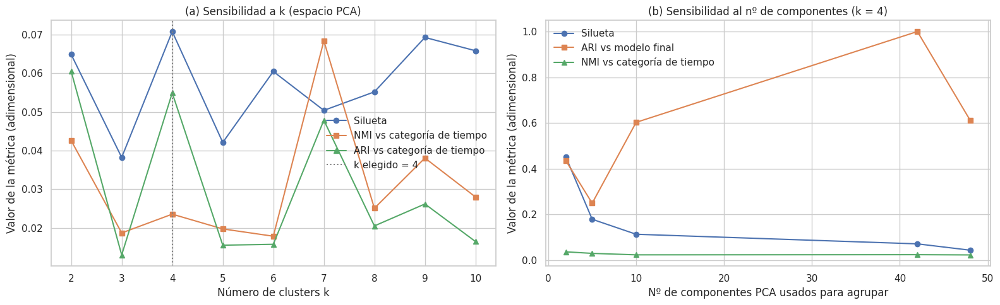

(a) Efecto de k:


,k,Silueta,NMI vs categoría de tiempo,ARI vs categoría de tiempo
0,2,0.07,0.04,0.06
1,3,0.04,0.02,0.01
2,4,0.07,0.02,0.06
3,5,0.04,0.02,0.02
4,6,0.06,0.02,0.02
5,7,0.05,0.07,0.05
6,8,0.06,0.03,0.02
7,9,0.07,0.04,0.03
8,10,0.07,0.03,0.02


(b) Efecto del nº de componentes:


,Nº componentes,Silueta (en su espacio),ARI vs modelo final,NMI vs categoría de tiempo
0,2,0.45,0.43,0.04
1,5,0.18,0.25,0.03
2,10,0.11,0.60,0.02
3,42,0.07,1.00,0.02
4,48,0.04,0.61,0.02


(c) Inicialización y n_init (5 semillas):


,init,n_init,Inercia media,Inercia sd,ARI medio vs final,ARI mínimo
0,k-means++,1,1724978.76,1990.01,0.32,0.27
1,k-means++,10,1716069.40,3087.68,0.55,0.30
2,random,1,1727301.13,3507.26,0.40,0.29
3,random,10,1714321.20,3160.73,0.74,0.32


(d) Escalado:


,Datos,NMI vs categoría de tiempo,NMI vs Vehicle_Type,ARI vs modelo final
0,Escalados + PCA (modelo final),0.02,0.00,1.00
1,Sin escalar (variables originales),0.18,0.00,0.00


Peso (%) de cada variable en la varianza total SIN escalar (top 5):


,% varianza
Road_Distance_km,54.00
Preparation_Time_Min,23.70
Order_Hour,10.30
Number_of_Signals,6.40
Rider_Experience_Years,2.90


**Interpretación automática (sensibilidad):**
- **k:** la silueta va de 0.038 a 0.071; el NMI con la categoría de tiempo es máximo en
  k = 7 (0.068).
  Más clusters no implica grupos más "reales": la silueta mide separación geométrica, el NMI mide relación con el tiempo.
- **Nº de componentes:** con 2 componentes la silueta es 0.451 (los datos parecen más agrupados porque se descarta casi toda la variación)
  pero el acuerdo con el modelo final es solo ARI = 0.435. Con 42 o 48 dimensiones los resultados son
  distintos (ARI = 0.612).
- **Inicialización:** con `random` y `n_init=1` el ARI mínimo frente al modelo final es 0.288;
  con `k-means++` y `n_init=10` es 0.303. Repetir la inicialización (n_init) y usar k-means++ evita mínimos locales.
- **Escalado:** sin escalar, `Road_Distance_km` concentra el 54% de la varianza total y domina la distancia euclidiana;
  el acuerdo con el modelo escalado es ARI = 0.000. Escalar es imprescindible para que todas las variables cuenten.

In [25]:
# [P3-C6] Sensibilidad a los parámetros: k, nº de componentes, inicialización/n_init y escalado
categoria_tiempo_txt = etiquetas_reales['Categoría de tiempo'].astype(str).values
vehiculo_txt = etiquetas_reales['Vehicle_Type'].astype(str).values

# (a) Efecto de k (reutiliza el barrido)
sens_k = pd.DataFrame({'k': RANGO_K,
                       'Silueta': [sub_pca.loc[k, 'Silueta'] for k in RANGO_K],
                       'NMI vs categoría de tiempo': [normalized_mutual_info_score(categoria_tiempo_txt, etiquetas_por_k[k]) for k in RANGO_K],
                       'ARI vs categoría de tiempo': [adjusted_rand_score(categoria_tiempo_txt, etiquetas_por_k[k]) for k in RANGO_K]})

# (b) Efecto del nº de componentes usados para agrupar
filas_comp_sens = []
for n_comp in sorted({2, 5, 10, K_PCA, N_FEATURES}):
    X_n = X_train_esc if n_comp == N_FEATURES else PCA(n_components=n_comp, random_state=SEED).fit_transform(X_train_esc)
    lab = KMeans(n_clusters=K_CLUSTERS, init='k-means++', n_init=10, random_state=SEED).fit_predict(X_n)
    filas_comp_sens.append({'Nº componentes': n_comp,
                            'Silueta (en su espacio)': silhouette_score(X_n, lab, sample_size=SIL_N_SUB, random_state=SEED),
                            'ARI vs modelo final': adjusted_rand_score(etiquetas_km, lab),
                            'NMI vs categoría de tiempo': normalized_mutual_info_score(categoria_tiempo_txt, lab)})
sens_comp = pd.DataFrame(filas_comp_sens)

# (c) Inicialización y n_init: estabilidad con 5 semillas distintas
filas_init = []
for init in ['k-means++', 'random']:
    for n_init in [1, 10]:
        inercias, aris = [], []
        for semilla in range(5):
            km = KMeans(n_clusters=K_CLUSTERS, init=init, n_init=n_init, random_state=semilla).fit(X_clu_pca)
            inercias.append(km.inertia_)
            aris.append(adjusted_rand_score(etiquetas_km, km.labels_))
        filas_init.append({'init': init, 'n_init': n_init, 'Inercia media': np.mean(inercias),
                           'Inercia sd': np.std(inercias), 'ARI medio vs final': np.mean(aris), 'ARI mínimo': np.min(aris)})
sens_init = pd.DataFrame(filas_init)

# (d) Escalado: K-Means sobre las variables SIN escalar
lab_sin_escala = KMeans(n_clusters=K_CLUSTERS, init='k-means++', n_init=10, random_state=SEED).fit_predict(Xtr)
varianza_cruda = pd.Series(Xtr.var(axis=0), index=NOMBRES_FEATURES)
peso_varianza = (varianza_cruda / varianza_cruda.sum() * 100).sort_values(ascending=False)
sens_escala = pd.DataFrame({
    'Datos': ['Escalados + PCA (modelo final)', 'Sin escalar (variables originales)'],
    'NMI vs categoría de tiempo': [normalized_mutual_info_score(categoria_tiempo_txt, etiquetas_km),
                                   normalized_mutual_info_score(categoria_tiempo_txt, lab_sin_escala)],
    'NMI vs Vehicle_Type': [normalized_mutual_info_score(vehiculo_txt, etiquetas_km),
                            normalized_mutual_info_score(vehiculo_txt, lab_sin_escala)],
    'ARI vs modelo final': [1.0, adjusted_rand_score(etiquetas_km, lab_sin_escala)],
})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(sens_k['k'], sens_k['Silueta'], marker='o', label='Silueta')
axes[0].plot(sens_k['k'], sens_k['NMI vs categoría de tiempo'], marker='s', label='NMI vs categoría de tiempo')
axes[0].plot(sens_k['k'], sens_k['ARI vs categoría de tiempo'], marker='^', label='ARI vs categoría de tiempo')
axes[0].axvline(K_CLUSTERS, color='gray', ls=':', label=f'k elegido = {K_CLUSTERS}')
axes[0].set_xlabel('Número de clusters k')
axes[0].set_ylabel('Valor de la métrica (adimensional)')
axes[0].set_title('(a) Sensibilidad a k (espacio PCA)')
axes[0].legend()
axes[1].plot(sens_comp['Nº componentes'], sens_comp['Silueta (en su espacio)'], marker='o', label='Silueta')
axes[1].plot(sens_comp['Nº componentes'], sens_comp['ARI vs modelo final'], marker='s', label='ARI vs modelo final')
axes[1].plot(sens_comp['Nº componentes'], sens_comp['NMI vs categoría de tiempo'], marker='^', label='NMI vs categoría de tiempo')
axes[1].set_xlabel('Nº de componentes PCA usados para agrupar')
axes[1].set_ylabel('Valor de la métrica (adimensional)')
axes[1].set_title(f'(b) Sensibilidad al nº de componentes (k = {K_CLUSTERS})')
axes[1].legend()
plt.tight_layout()
plt.show()

print('(a) Efecto de k:'); display(sens_k.round(3))
print('(b) Efecto del nº de componentes:'); display(sens_comp.round(3))
print('(c) Inicialización y n_init (5 semillas):'); display(sens_init.round(3))
print('(d) Escalado:'); display(sens_escala.round(3))
print('Peso (%) de cada variable en la varianza total SIN escalar (top 5):'); display(peso_varianza.head(5).round(1).to_frame('% varianza'))

fila_2 = sens_comp.iloc[0]
ari_min_random_1 = sens_init[(sens_init['init'] == 'random') & (sens_init['n_init'] == 1)]['ARI mínimo'].iloc[0]
ari_min_pp_10 = sens_init[(sens_init['init'] == 'k-means++') & (sens_init['n_init'] == 10)]['ARI mínimo'].iloc[0]
nota(f"""**Interpretación automática (sensibilidad):**
- **k:** la silueta va de {sens_k['Silueta'].min():.3f} a {sens_k['Silueta'].max():.3f}; el NMI con la categoría de tiempo es máximo en
  k = {int(sens_k.loc[sens_k['NMI vs categoría de tiempo'].idxmax(), 'k'])} ({sens_k['NMI vs categoría de tiempo'].max():.3f}).
  Más clusters no implica grupos más "reales": la silueta mide separación geométrica, el NMI mide relación con el tiempo.
- **Nº de componentes:** con 2 componentes la silueta es {fila_2['Silueta (en su espacio)']:.3f} (los datos parecen más agrupados porque se descarta casi toda la variación)
  pero el acuerdo con el modelo final es solo ARI = {fila_2['ARI vs modelo final']:.3f}. Con {K_PCA} o {N_FEATURES} dimensiones los resultados son
  {'casi idénticos' if sens_comp.iloc[-1]['ARI vs modelo final'] > 0.9 else 'distintos'} (ARI = {sens_comp.iloc[-1]['ARI vs modelo final']:.3f}).
- **Inicialización:** con `random` y `n_init=1` el ARI mínimo frente al modelo final es {ari_min_random_1:.3f};
  con `k-means++` y `n_init=10` es {ari_min_pp_10:.3f}. Repetir la inicialización (n_init) y usar k-means++ evita mínimos locales.
- **Escalado:** sin escalar, `{peso_varianza.index[0]}` concentra el {peso_varianza.iloc[0]:.0f}% de la varianza total y domina la distancia euclidiana;
  el acuerdo con el modelo escalado es ARI = {sens_escala.iloc[1]['ARI vs modelo final']:.3f}. Escalar es imprescindible para que todas las variables cuenten.""")

In [26]:
# [P3-C7] Datos para la discusión de limitaciones: desbalance de categorías
for columna in ['Delivery_Distance_Category', 'Traffic_Level', 'Vehicle_Type', 'Weather']:
    if columna in df.columns:
        distribucion = df[columna].value_counts(normalize=True).mul(100).round(1)
        print(f'{columna}: ' + ' | '.join(f'{k} {v}%' for k, v in distribucion.items()))
n_dummies = sum(1 for c in NOMBRES_FEATURES if X_fase[c].nunique() <= 2)
print(f'\nColumnas binarias (dummies o 0/1) en X: {n_dummies} de {N_FEATURES}')

Delivery_Distance_Category: Long 94.5% | Medium 4.5% | Short 1.1%
Traffic_Level: Low 65.1% | Moderate 26.3% | High 7.5% | Severe 1.0%
Vehicle_Type: Bike 45.9% | Scooter 25.8% | Electric Scooter 17.7% | Bicycle 10.6%
Weather: Clear 48.0% | Cloudy 22.2% | Rain 18.1% | Fog 6.8% | Storm 4.9%

Columnas binarias (dummies o 0/1) en X: 40 de 48


### Interpretación del Paso 3: parámetros, efecto y limitaciones

**Parámetros y su efecto**
- **k:** se eligió con la silueta máxima y se contrastó con el codo de la inercia, Davies-Bouldin y Calinski-Harabasz. La inercia siempre disminuye con k, por eso nunca se usa sola.
- **`init='k-means++'` y `n_init`:** k-means++ coloca los centroides iniciales separados entre sí y `n_init` repite el algoritmo y se queda con la menor inercia; la tabla (c) muestra que con `random` y `n_init=1` la solución puede cambiar según la semilla.
- **Nº de componentes:** con muy pocos componentes la silueta sube artificialmente (se eliminan direcciones de variación), pero los grupos cambian; con `K_PCA` o con todas las variables los resultados son prácticamente los mismos, así que PCA aquí sirve para reducir costo y ruido, no cambia la conclusión.
- **Linkage (aglomerativo):** `ward` produce grupos de tamaño parecido y se asemeja a K-Means; `complete` y `average` son sensibles a puntos extremos y tienden a dejar un grupo enorme y grupos diminutos.
- **Escalado:** sin escalar, la variable con mayor varianza en sus unidades domina la distancia euclidiana y el clustering prácticamente se reduce a cortar esa variable.
- **DBSCAN** no se usó como algoritmo principal: en espacios de más de 30 dimensiones las distancias se concentran (todas se parecen) y es muy difícil elegir `eps`/`min_samples` sin que todo quede en un solo grupo o como ruido.

**Limitaciones**
- K-Means asume clusters **esféricos, de tamaño y densidad similares**; los datos de entregas forman un continuo, no "nubes" separadas, lo que explica una silueta baja.
- La mayoría de las columnas son **dummies** (impresas arriba): la distancia euclidiana entre vectores binarios no es la medida natural para categóricas (alternativas: **K-Prototypes**, distancia de Gower o clustering sobre MCA/FAMD).
- **Desbalance:** `Delivery_Distance_Category` y `Traffic_Level` tienen una categoría que concentra la gran mayoría de los registros (porcentajes impresos arriba), por lo que las categorías minoritarias pesan poco en los centroides y la pureza es alta aunque los clusters no aporten información.
- El dataset parece **sintético** (relaciones muy limpias, sin valores faltantes): los segmentos encontrados pueden no trasladarse a datos reales de Rappi.
- Los clusters **no son una verdad**: son una herramienta exploratoria para describir tipos de entregas y generar hipótesis operativas (por ejemplo, priorizar recursos en el segmento con mayor tiempo mediano).

## PASO 4. Conclusiones

La primera celda resume las **cifras clave obtenidas en esta ejecución** (se generan automáticamente para que el texto nunca contradiga los resultados). La segunda celda presenta las conclusiones conceptuales del proyecto completo.

In [27]:
# [P4-C1] Cifras clave de la fase (generadas con los resultados reales)
mejor_sin = tabla_referencia['MAE'].idxmin()
resumen_modelos = pd.DataFrame({
    'MAE sin PCA': tabla_referencia['MAE'], 'MAE con PCA': tabla_comparativa_pca['MAE con PCA'],
    'RMSE sin PCA': tabla_referencia['RMSE'], 'RMSE con PCA': tabla_comparativa_pca['RMSE con PCA'],
    'R² sin PCA': tabla_referencia['R2'], 'R² con PCA': tabla_comparativa_pca['R² con PCA'],
    'Δ MAE (%)': tabla_comparativa_pca['Δ MAE (%)'],
    'p-valor K-Fold': tabla_cv_pca['p-valor'],
})
print('=== Resumen supervisado (test, minutos) ===')
display(resumen_modelos.round(3))

km_metricas = tabla_algoritmos.iloc[0]
resumen_cluster = pd.Series({
    'k elegido': K_CLUSTERS, 'Espacio': NOMBRE_ESPACIO_PCA,
    'Silueta (submuestra)': round(km_metricas['Silueta'], 3),
    'Davies-Bouldin': round(km_metricas['Davies-Bouldin'], 3),
    'Calinski-Harabasz': round(km_metricas['Calinski-Harabasz'], 1),
    'ARI vs categoría de tiempo': round(tabla_externas.loc['Categoría de tiempo', 'ARI'], 3),
    'NMI vs categoría de tiempo': round(tabla_externas.loc['Categoría de tiempo', 'NMI'], 3),
    'NMI vs Vehicle_Type': round(tabla_externas.loc['Vehicle_Type', 'NMI'], 3),
    'NMI vs Traffic_Level': round(tabla_externas.loc['Traffic_Level', 'NMI'], 3),
    'η² del tiempo explicado por el cluster': round(eta2_tiempo, 3),
}, name='Valor')
print('=== Resumen no supervisado ===')
display(resumen_cluster.to_frame())

modelos_mejoran = [m for m in MODELOS if tabla_comparativa_pca.loc[m, 'Δ MAE (%)'] < -2]
modelos_empeoran = [m for m in MODELOS if tabla_comparativa_pca.loc[m, 'Δ MAE (%)'] > 2]
modelos_neutros = [m for m in MODELOS if m not in modelos_mejoran + modelos_empeoran]
nota(f"""### Conclusiones cuantitativas de esta ejecución
1. **Referencia sin PCA ({N_FEATURES} variables, sin fuga):** el mejor modelo es **{mejor_sin}** con MAE = {tabla_referencia.loc[mejor_sin, 'MAE']:.2f} min,
   RMSE = {tabla_referencia.loc[mejor_sin, 'RMSE']:.2f} min y R² = {tabla_referencia.loc[mejor_sin, 'R2']:.3f}.
2. **PCA:** se eligieron **{K_PCA} componentes** ({var_acum[K_PCA-1]*100:.1f}% de la varianza, {100*(1-K_PCA/N_FEATURES):.0f}% menos dimensiones).
   Umbrales: 90% -> {k_90}, 95% -> {k_95}, 99% -> {k_99}; Kaiser -> {k_kaiser}. La varianza está repartida (PC1 = {var_ratio[0]*100:.1f}%),
   así que la compresión posible sin perder información es limitada.
3. **Con vs sin PCA:** PCA mejora a {', '.join(modelos_mejoran) or 'ningún modelo'}; empeora a {', '.join(modelos_empeoran) or 'ningún modelo'};
   es neutro para {', '.join(modelos_neutros) or 'ningún modelo'} (umbral ±2% de MAE).
4. **Clustering:** K-Means con k = {K_CLUSTERS} en el espacio PCA, silueta = {km_metricas['Silueta']:.3f} ({calidad_silueta(km_metricas['Silueta'])}).
   Frente a la categoría de tiempo: ARI = {tabla_externas.loc['Categoría de tiempo', 'ARI']:.3f}, NMI = {tabla_externas.loc['Categoría de tiempo', 'NMI']:.3f};
   la pertenencia al cluster explica η² = {eta2_tiempo*100:.1f}% de la varianza del tiempo sin haberlo usado.""")

=== Resumen supervisado (test, minutos) ===


,MAE sin PCA,MAE con PCA,RMSE sin PCA,RMSE con PCA,R² sin PCA,R² con PCA,Δ MAE (%),p-valor K-Fold
Modelo,,,,,,,,
Decision Tree,4.07,9.98,5.55,15.62,0.98,0.81,145.13,0.00
Random Forest,3.05,6.96,4.04,10.60,0.99,0.91,128.46,0.00
SVR,4.39,5.88,6.82,10.29,0.96,0.92,33.92,0.00
Red Neuronal,2.74,3.12,3.55,4.03,0.99,0.99,14.13,0.06


=== Resumen no supervisado ===


,Valor
k elegido,4
Espacio,PCA (42 comps)
Silueta (submuestra),0.07
Davies-Bouldin,3.49
Calinski-Harabasz,193.50
ARI vs categoría de tiempo,0.06
NMI vs categoría de tiempo,0.02
NMI vs Vehicle_Type,0.00
NMI vs Traffic_Level,0.47
η² del tiempo explicado por el cluster,0.06


### Conclusiones cuantitativas de esta ejecución
1. **Referencia sin PCA (48 variables, sin fuga):** el mejor modelo es **Red Neuronal** con MAE = 2.74 min,
   RMSE = 3.55 min y R² = 0.990.
2. **PCA:** se eligieron **42 componentes** (99.1% de la varianza, 12% menos dimensiones).
   Umbrales: 90% -> 34, 95% -> 37, 99% -> 42; Kaiser -> 30. La varianza está repartida (PC1 = 6.0%),
   así que la compresión posible sin perder información es limitada.
3. **Con vs sin PCA:** PCA mejora a ningún modelo; empeora a Decision Tree, Random Forest, SVR, Red Neuronal;
   es neutro para ningún modelo (umbral ±2% de MAE).
4. **Clustering:** K-Means con k = 4 en el espacio PCA, silueta = 0.071 (sin estructura de grupos clara (clusters solapados)).
   Frente a la categoría de tiempo: ARI = 0.055, NMI = 0.024;
   la pertenencia al cluster explica η² = 5.7% de la varianza del tiempo sin haberlo usado.

### Conclusiones del proyecto y conexión con los conceptos del curso

**Utilidad de cada técnica para este problema**

- **EDA:** permitió identificar que la distancia (`Road_Distance_km`), el tiempo de preparación, el tráfico y el tipo de vehículo son los factores que más explican el tiempo; que el objetivo tiene **sesgo a la derecha** (cola de entregas largas, hasta 180 min); que los *outliers* son eventos operativos reales y no errores; y, sobre todo, detectar la **fuga de información** de `Average_Speed_kmph`, que se calcula con el propio tiempo de entrega.
- **Aprendizaje supervisado:** resuelve la tarea principal (predecir minutos de entrega) y permite comparar cuatro familias de modelos: árbol (interpretable, alta varianza), ensamble (Random Forest, reduce varianza promediando árboles), kernel (SVR, costoso con muchas filas) y red neuronal densa (capta no linealidades e interacciones).
- **Aprendizaje no supervisado:** descubre **segmentos operativos** de entregas sin usar el objetivo; sirve para describir el negocio y para generar hipótesis (por ejemplo, qué combinación de distancia, vehículo y tráfico concentra los tiempos más altos), pero no reemplaza al modelo predictivo.
- **Reducción de dimensionalidad:** comprime la información, elimina la multicolinealidad entre *dummies* y permite visualizar los datos en 2D; su costo es la pérdida de interpretabilidad y de la información de baja varianza o no lineal.

**Conceptos del curso**

| Concepto | Dónde aparece en el proyecto |
|---|---|
| Maldición de la dimensionalidad | Motivo para probar PCA; afecta a SVR, redes y a las distancias de K-Means/DBSCAN. Aquí es moderada (≈48 columnas vs 40.000 filas). |
| Sobreajuste y compromiso sesgo-varianza | Árbol profundo (varianza alta) vs Random Forest (promedia árboles); con pocos componentes PCA aumenta el sesgo. |
| Validación cruzada | K-Fold k=5 en la búsqueda de hiperparámetros, en la curva de componentes y en la comparación con/sin PCA (media ± sd). |
| Escalado de variables | Imprescindible para SVR, la red, PCA y K-Means (Paso 3, sensibilidad d). |
| Fuga de datos (*data leakage*) | Exclusión de `Average_Speed_kmph`, `target_time` y auxiliares del EDA; `fit` solo en train. |
| Regularización / hiperparámetros | `max_depth`, `min_samples_leaf`, `C`, `epsilon`, tasa de aprendizaje, nº de neuronas (RandomizedSearchCV); `k`, `n_init`, *linkage* y nº de componentes en la fase no supervisada. |
| Supervisado vs no supervisado | Regresión con `y` conocido vs clustering y PCA que solo usan `X`. |
| Varianza explicada y autovalores | *Scree plot*, criterio de Kaiser y varianza acumulada (Paso 1). |
| Métricas internas vs externas | Silueta, Davies-Bouldin, Calinski-Harabasz (sin etiquetas) vs ARI, NMI, homogeneidad, completitud y pureza (con etiquetas). |

**Fortalezas:** tratamiento explícito de la fuga de información; comparación justa (misma partición, mismos hiperparámetros y mismas métricas); validación cruzada con prueba pareada; clustering validado con métricas internas y externas y con análisis de sensibilidad.

**Limitaciones:** dataset aparentemente sintético; codificación *one-hot* poco adecuada para PCA y K-Means; SVR entrenado con submuestra; los errores siguen siendo mayores en las entregas extremas (>120 min); no hay dimensión temporal en la validación.

**Mejoras futuras:** ingeniería de variables (interacciones distancia × tráfico, hora pico); codificaciones alternativas de categóricas (*target encoding*, *embeddings*); modelos de *boosting* (XGBoost, LightGBM, CatBoost); validación temporal (entrenar con meses pasados y probar con meses futuros); intervalos de predicción (regresión cuantílica) para prometer tiempos con un margen; selección de variables en lugar de PCA para conservar interpretabilidad; y validar todo con datos reales de Rappi.

### Checklist de la rúbrica

| Requisito | Dónde se cumple |
|---|---|
| Partición única 80/20, `shuffle=True`, `random_state=42` | `[P0-C2]` |
| `fit` de escalado/PCA/clustering solo en train; semilla 42 | `[P0-C1]` (funciones `ajustar_y_evaluar`, `validacion_cruzada`), `[P0-C2]`, `[P3-C1]` |
| Verificación de que X no tiene el objetivo, `Average_Speed_kmph` ni columnas del EDA (`distance_group`) | `[P0-C2]` (tabla de columnas eliminadas y tabla de verificación) |
| Tabla "Referencia (sin PCA)" con MAE, RMSE y R² | `[P0-C3]` |
| StandardScaler + PCA completo en train | `[P1-C1]` |
| Scree plot y varianza acumulada con líneas 90/95/99% | `[P1-C1]` |
| Tabla de componentes para 90/95/99% vs nº de variables originales | `[P1-C1]` |
| Elección de componentes con ≥2 criterios (varianza, codo, Kaiser, curva empírica en CV) | `[P1-C1]`, `[P1-C2]` |
| Justificación compresión vs pérdida de desempeño | `[P1-C2]` + texto "Interpretación del Paso 1" |
| Loadings de PC1-PC3 e interpretación de negocio | `[P1-C3]` |
| Limitaciones de PCA (linealidad, dummies) y alternativas (TruncatedSVD, MCA/FAMD, PCA solo numéricas) | Texto "Interpretación del Paso 1" |
| Mismos modelos/hiperparámetros/partición/métricas con PCA; SVR con submuestra declarada | `[P0-C1]`, `[P2-C1]` |
| Tabla comparativa (MAE/RMSE sin y con PCA, Δ absoluta y %, tiempo, nº features) + barras agrupadas | `[P2-C1]` |
| K-Fold k=5 con media ± sd y comparación con el ruido | `[P2-C2]` |
| Interpretación: modelos beneficiados/perjudicados, qué se gana y qué se pierde | `[P2-C1]`, `[P2-C2]` + texto "Interpretación del Paso 2" |
| Clustering sin `Time_taken_min`, espacio escalado vs PCA | `[P3-C1]` |
| K-Means con codo + silueta (submuestra declarada), `n_init` y `random_state` | `[P3-C1]`, `[P3-C2]` |
| Segundo algoritmo (aglomerativo ward/complete/average) y comparación | `[P3-C2]` |
| Métricas internas: silueta, Davies-Bouldin, Calinski-Harabasz | `[P3-C1]`, `[P3-C2]` |
| Visualización PC1-PC2 y t-SNE coloreadas por cluster | `[P3-C3]` |
| Perfil por cluster, nombres de negocio y boxplot del tiempo por cluster | `[P3-C4]` |
| Contraste con etiquetas reales (categoría de tiempo, cuartiles, Vehicle_Type, Traffic_Level): crosstab, ARI, NMI, homogeneidad, completitud, pureza, heatmap | `[P3-C5]` |
| Discusión de parámetros y prueba de sensibilidad (k, nº componentes, init/n_init, escalado, linkage) | `[P3-C6]`, `[P3-C2]` + texto "Interpretación del Paso 3" |
| Limitaciones del clustering (esfericidad, dummies, desbalance, dataset sintético) | `[P3-C7]` + texto "Interpretación del Paso 3" |
| Conclusiones con cifras clave, utilidad de cada técnica, fortalezas, limitaciones, mejoras y conceptos del curso | `[P4-C1]` + texto "Conclusiones del proyecto" |